# **1) Explorative Datenanalyse**

##### **Ziel:** Preis, Systembilanz, Wetter und Kalender 2026 beschreiben, prüfen, welche Zusammenhänge für eine Prognose um 11:00 am Vortag (D−1) nutzbar sind, und daraus Bewertungsdesign und Metriken ableiten

---

#### **Rahmen**
- **Team:** Elias Pulver, Luca Manna, Rodrigo Urech
- **Input:**
    - `balance_prices.parquet` und `weather_forecasts.parquet` aus `data/processed/`
    - Regelzonenbilanz aus dem Snapshot vom 04.10.2026 (`data/control_area_balance/snapshots/control-area-balance-2026_2026-10-04T13-47-09Z.csv`), Stand der Analyse
    - Standorte, Feiertage und PV-Leistung aus `data/meta/`
    - Snapshot der Regelzonenbilanz vom 15.11.2026 (`data/control_area_balance/snapshots/control-area-balance-2026_2026-11-15T16-31-50Z.csv`) für `1.5.4) Vor und nach der Umstellung auf Viertelstunden`
- **Output:** Grafiken unter `docs/figures/`, Zusammenfassung mit Merkmalskandidaten in [`docs/eda.md`](../docs/eda.md)

## Einleitung

Dieses Notebook beschreibt die Daten für die Prognose des Ausgleichsenergiepreises und prüft, welche Zusammenhänge für eine Prognose um **11:00 am Vortag (D−1)** nutzbar sind. Grundlage ist [Issue #3](https://github.com/ibidreli/energy_price_prediction/issues/3) mit den Hypothesen H1 bis H7, dazu H8 aus dem Review. Die zweite Runde mit H9 bis H12 prüft das Wetter als Unsicherheitssignal, vergangene Preise und die Stabilität über die Monate. Zuerst wird die Datenqualität geprüft, danach folgen die Hypothesen.

| Kapitel | Inhalt | Daten |
|---|---|---|
| `1.1) Datenqualität` | automatischer Bericht, Typen, Fehlwerte, Duplikate, Verteilungen, Ausreisser, Zusammenhänge und Abdeckung | Preis, Regelzonenbilanz, Wetter |
| `1.2) Muster von Systembilanz und Preis` | H1 bis H8 | Preis, Regelzonenbilanz, Strahlungsprognose, Feiertage |
| `1.3) Wetter, vergangene Preise und Stabilität` | H9 bis H12 | Preis, Regelzonenbilanz, alle Wettervariablen |
| `1.4) Bewertungsdesign und Metriken` | Prognoseaufgabe, Bewertungsverfahren, Quantile, Pinball-Loss und Zusatzmetriken, mit den Daten hergeleitet | Preis, Regelzonenbilanz |
| `1.5) Stundenslot-Handel` | Granularität von Handel und Abrechnung, Vergleich mit anderen Märkten, Stabilität des Kippens, Umstellung auf Viertelstunden am **04.11.2026**, Empfehlung zum Merkmal | Regelzonenbilanz, Snapshot vom 15.11.2026, Preis, Strahlungsprognose |
| `1.6) Fazit` | Antworten in einem Satz, Empfehlungen und Grenzen | |

## Datenbasis

Verwendet werden nur Preise des Einpreissystems ab **01.01.2026**.

**Zeiträume:**
- **Preis:** bis **31.08.2026**, finale Werte
- **Regelzonenbilanz:** bis **31.08.2026**, der Snapshot selbst reicht bis 03.10.2026
- **Wetter:** Liefertage bis **31.08.2026**
- **Testperiode:** September und Oktober 2026 werden direkt nach dem Laden abgeschnitten (`TEST_START`, #36, #50). Einzige Ausnahme ist `1.5.4) Vor und nach der Umstellung auf Viertelstunden` mit einem eigenen Snapshot

**Daten:**
- `balance_prices.parquet`: Ausgleichsenergiepreis `aep_ct_kwh` je Viertelstunde, nur `regime` = `single_price`
- `control_area_balance.parquet`: Systembilanz `tsi_mw` und Abrufe der Regelenergie je Viertelstunde
- `weather_forecasts.parquet`: Wetterprognosen des Laufs D−2 18 UTC je Standort und Stunde
- `weather_sites.csv`, `holidays_ch.csv` und `pv_capacity_by_canton.csv`: Standorte mit PV-Anteil, Feiertage und PV-Leistung je Kanton

**Leak-Regel:**
- **Dieselbe Viertelstunde:**
    - Zusammenhänge *derselben* Viertelstunde, zum Beispiel TSI und Preis, werden nur gezeigt, um den Mechanismus zu verstehen
    - Als Merkmal sind sie verboten
- **Bekannt um 11:00 an D−1:** Für jede Merkmalsidee steht, ob sie dann bekannt ist
    - **Swissgrid:** nur bis Ende D−2, die Grenze ist noch eine **Annahme** bis ca. **18.10.2026**
    - **Wetter:** aus dem Lauf D−2 18 UTC
    - **Feiertage:** ohne Einschränkung
    - **Vergangene Preise:** nur über `known_at_issue()`
- **Details:** [`docs/data.md`](../docs/data.md#1-die-regel-gegen-datenlecks)

In [1]:
%load_ext autoreload
%autoreload 2

#---------------------------------------------------------------------------
# Bibliotheken, Projektpfad, Farben der Grafiken und fester Zufallsstartwert
#---------------------------------------------------------------------------
import datetime as dt
import os
import random
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytest

# The notebook runs from notebooks/; all paths are relative to the project root.
if Path.cwd().name == "notebooks":
    os.chdir("..")

from energy_price import eda
from energy_price.metrics import pinball_loss
from energy_price.data.control_area_balance import read_snapshot
from energy_price.models.shared.reference import reference_forecast
from energy_price.data.figures_data import BLUE, CATEGORICAL, INK, INK_2, MUTED, SURFACE, style

# figures_data switches matplotlib to Agg for `make figures`; back to inline so the figures show here.
%matplotlib inline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

style()
FIGURES = Path("docs/figures")
RED = "#e34948"  # red pole of the diverging pair of the reference palette (blue <-> gray <-> red)
DIVERGING = matplotlib.colors.LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", RED])
TZ = "Europe/Zurich"
MONTHS = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug"]

print(f"python {sys.version.split()[0]} ({os.path.relpath(sys.executable)})")  # relative: no local home path in the repo
print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {matplotlib.__version__}")


#-------------------------------------------------------------
# Grafiken gleich wie energy_price.data.figures_data speichern
#-------------------------------------------------------------
def save(fig: plt.Figure, name: str) -> None:
    # Same resolution and cropping as energy_price.figures_data, so all figures in docs/ look alike.
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")

python 3.14.7 (../task-pipeline-neu-aufbauen-t-gliches-walk-forwar/.venv/bin/python)
pandas 3.0.6, numpy 2.5.3, matplotlib 3.11.2


Der Kernel muss in `.venv` zeigen (siehe Ausgabe). Zufall kommt nur in der Stichprobe von Zeilen bei den Datentypen vor, der Seed ist trotzdem global gesetzt.

**Tests:**
- Vor der ersten Verwendung werden die Funktionen aus `src/energy_price/eda.py` und `src/energy_price/metrics.py` mit `tests/test_eda.py` und `tests/test_metrics.py` geprüft
- Schlägt ein Test fehl, bricht das Notebook ab

In [2]:
#---------------------------------------------------------------
# Funktionen aus eda.py und metrics.py vor der Verwendung testen
#---------------------------------------------------------------
exit_code = pytest.main(["-q", "--color=no", "-p", "no:cacheprovider", "tests/test_eda.py", "tests/test_metrics.py"])
assert exit_code == 0, "Mindestens ein Test der EDA- oder Metrik-Funktionen ist fehlgeschlagen."

.

.

.

.

.

.

... (42 outputs left out)

.

.

                       [100%]


50 passed in 0.15s


In [3]:
#------------------------------------------------------------------------------------
# Tabellen laden, Preise auf das Einpreissystem 2026 beschränken und Zeiträume zeigen
#------------------------------------------------------------------------------------
prices_all = pd.read_parquet("data/processed/balance_prices.parquet")
# State of the analysis: the snapshot of 04.10.2026 (data until 03.10.2026, hourly day-ahead trading only),
# read directly instead of data/processed/, which always follows the newest snapshot. Built like
# `make data` does. The newer snapshot with the switch to quarter hours is read separately in 1.5.4.
CAB_SNAPSHOT = Path("data/control_area_balance/snapshots/control-area-balance-2026_2026-10-04T13-47-09Z.csv")
cab = read_snapshot(CAB_SNAPSHOT).assign(snapshot=CAB_SNAPSHOT.name)
weather = pd.read_parquet("data/processed/weather_forecasts.parquet")
sites = pd.read_csv("data/meta/weather_sites.csv")
holidays = pd.read_csv("data/meta/holidays_ch.csv", parse_dates=["date"])
pv_capacity = pd.read_csv("data/meta/pv_capacity_by_canton.csv")

TEST_START = pd.Timestamp("2026-09-01")  # test period Sep/Oct stays out of the EDA (#36, #50)
prices_all = prices_all[prices_all["timestamp_local"] < TEST_START.tz_localize(TZ)]
cab = cab[cab["timestamp_local"] < TEST_START.tz_localize(TZ)]
weather = weather[weather["delivery_day"] < TEST_START].reset_index(drop=True)

prices = prices_all[prices_all["regime"] == "single_price"].reset_index(drop=True)  # owner decision: 2026 only
for name, frame, column in [("prices 2026", prices, "timestamp_local"), ("control area balance", cab, "timestamp_local"),
                            ("weather", weather, "delivery_day")]:
    print(f"{name:22s} {frame.shape}  {frame[column].min()} .. {frame[column].max()}")

prices 2026            (23324, 6)  2026-01-01 00:00:00+01:00 .. 2026-08-31 23:45:00+02:00
control area balance   (23324, 15)  2026-01-01 00:00:00+01:00 .. 2026-08-31 23:45:00+02:00
weather                (36444, 20)  2026-01-01 00:00:00 .. 2026-08-31 00:00:00


---
## **1.1) Datenqualität**

Vor den Hypothesen wird geprüft, ob die Tabellen vollständig, korrekt typisiert und frei von Duplikaten sind und wie sich die Werte verteilen.

### **1.1.1) Automatischer Bericht mit `fg-data-profiling`**

`make profile` schreibt je Tabelle einen HTML-Bericht nach `reports/` (nicht versioniert).

**Eigene Umgebung:**
- Der Bericht läuft in `.venv-profile`, weil `fg-data-profiling` 4.20.0 `pandas < 3` verlangt, das Projekt aber pandas 3.0.6 nutzt
- Darum wird er hier nicht importiert

**Vorprüfung (05.10.2026):**
- pandas 2.3.3 liest die mit pandas 3.0.6 geschriebenen Parquet-Dateien identisch (Form, Summe aller Zahlen, Fehlwerte, Zeitzonen, Kategorien)
- Einziger Unterschied: Textspalten kommen als `object` statt `str`
- Ein Umweg über CSV ist nicht nötig

**Warnungen des Berichts** (der Bericht zeigt, *wo* man hinschauen muss, nicht *was* daraus folgt):

| Tabelle | Warnung | Folge für die Analyse |
|---|---|---|
| Regelzonenbilanz | `mfrr_da_pos_mw`, `mfrr_da_neg_mw` konstant | bestätigt: 2026 durchgehend 0, weglassen |
| Regelzonenbilanz | hohe Korrelationen zwischen den Abrufen, TSI und Preis | erwartet, die TSI hängt direkt an den Abrufen, siehe Abschnitt `1.1.6) Zusammenhänge derselben Viertelstunde` |
| Regelzonenbilanz | `mfrr_sa_pos_mw` 58 % Nullen, `mfrr_sa_neg_mw` 71 % | manuelle Regelenergie wird selten abgerufen, keine Fehlwerte |
| Wetter | Strahlung zu 45 bis 50 % null, Niederschlag 84 %, Schneefall 97 % | Nacht bzw. trockene Stunden, kein Datenfehler |
| Wetter | Strahlungs- und Bewölkungsvariablen untereinander hoch korreliert | für Modelle wenige Vertreter wählen |
| Feiertage | `source` konstant | nur Herkunftsangabe |

**Nicht gemeldet:**
- die eine Viertelstunde mit fehlenden Abrufen am **02.10.2026**
- die doppelten Stundenwerte um Mitternacht im Wetter

### **1.1.2) Form und Typen**

In [4]:
#-------------------------------------------------------------------------------------
# Datentypen und Zeitzonen je Tabelle, dazu drei zufällige Zeilen der Regelzonenbilanz
#-------------------------------------------------------------------------------------
for name, frame in [("prices", prices), ("cab", cab), ("weather", weather)]:
    print(f"--- {name}")
    print(frame.dtypes.astype(str).value_counts().to_string())
    print("timezone-aware:", [c for c in frame.columns if isinstance(frame[c].dtype, pd.DatetimeTZDtype)])
cab.sample(3, random_state=SEED).T

--- prices
float64                          3
datetime64[us, UTC]              1
datetime64[us, Europe/Zurich]    1
category                         1
timezone-aware: ['timestamp_utc', 'timestamp_local']
--- cab
float64                          12
datetime64[us, UTC]               1
datetime64[us, Europe/Zurich]     1
str                               1
timezone-aware: ['timestamp_utc', 'timestamp_local']
--- weather
float64                          11
int64                             4
datetime64[us, UTC]               2
datetime64[ms]                    1
str                               1
datetime64[us, Europe/Zurich]     1
timezone-aware: ['run_utc', 'valid_time_utc', 'valid_time_local']


,210,6969,6340
timestamp_utc,2026-01-03 03:30:00+00:00,2026-03-14 13:15:00+00:00,2026-03-08 00:00:00+00:00
timestamp_local,2026-01-03 04:30:00+01:00,2026-03-14 14:15:00+01:00,2026-03-08 01:00:00+01:00
afrr_pos_mw,14.439013,92.138677,8.46163
afrr_neg_mw,-0.023057,0.0,-0.527616
mfrr_sa_pos_mw,0.0,0.0,0.0
mfrr_sa_neg_mw,-10.0,-32.0,0.0
mfrr_da_pos_mw,0.0,0.0,0.0
mfrr_da_neg_mw,0.0,0.0,0.0
igcc_import_mw,4.545181,1.721461,40.426149
igcc_export_mw,-1.333552,-1.508244,-1.395342


#### **Erkenntnisse**

Die Typen stimmen.

- **Messwerte:** alle `float64` bzw. `int64` (Bewölkung in ganzen Prozent), keine Zahlen als Text
- **Zeitstempel:** alle zeitzonenbewusst, sowohl UTC als auch `Europe/Zurich`
- **Uhrzeit:** Gruppiert nach Uhrzeit wird immer auf **Lokalzeit** (`timestamp_local`)

### **1.1.3) Fehlwerte**

In [5]:
#--------------------------------------------------------------------------------------------
# Fehlende Werte in Preis und Regelzonenbilanz zählen und die betroffene Viertelstunde zeigen
#--------------------------------------------------------------------------------------------
def missing(frame: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame({"count": frame.isna().sum(), "pct": frame.isna().mean().mul(100).round(2)})
    return out[out["count"] > 0]

print("prices 2026:\n", missing(prices).to_string())
print("\ncab:\n", missing(cab).to_string())
cab[cab.drop(columns=["tsi_mw", "price_ct_kwh"]).isna().any(axis=1)][["timestamp_local", "tsi_mw", "price_ct_kwh", "afrr_pos_mw"]]

prices 2026:
               count    pct
long_ct_kwh   23324  100.0
short_ct_kwh  23324  100.0

cab:
 Empty DataFrame
Columns: [count, pct]
Index: []


,timestamp_local,tsi_mw,price_ct_kwh,afrr_pos_mw


In [6]:
#------------------------------------------------------------------
# Fehlende Werte im Wetter mit dem Protokoll der Lücken vergleichen
#------------------------------------------------------------------
print(missing(weather).to_string())
pd.read_csv("data/processed/weather_missing.csv")

                          count   pct
shortwave_radiation         150  0.41
direct_radiation            150  0.41
diffuse_radiation           150  0.41
direct_normal_irradiance    150  0.41
sunshine_duration           150  0.41
relative_humidity_2m        300  0.82
wind_speed_10m              150  0.41


,delivery_day,variable,missing
0,2026-06-12,relative_humidity_2m,150
1,2026-06-24,shortwave_radiation,150
2,2026-06-24,direct_radiation,150
3,2026-06-24,diffuse_radiation,150
4,2026-06-24,direct_normal_irradiance,150
5,2026-06-24,sunshine_duration,150
6,2026-06-24,relative_humidity_2m,150
7,2026-06-24,wind_speed_10m,150


#### **Erkenntnisse**

Preis und Regelzonenbilanz sind für die Analyse vollständig, im Wetter fehlen Werte an zwei dokumentierten Tagen.

**Preis 2026 vollständig**
- `aep_ct_kwh` ist vollständig
- `long_ct_kwh` und `short_ct_kwh` sind ab 2026 leer, weil das Zweipreissystem endete (erwartet)

**Regelzonenbilanz vollständig**
- Bis **31.08.2026** fehlt kein Wert
- Die einzige Lücke des Snapshots (**02.10.2026 14:00**, alle zehn Abruf-Spalten) liegt in der Testperiode und wird nicht geladen. Nicht füllen

**Wetter mit Archivlücken an zwei Tagen**
- **24.06.2026:** An allen sechs Standorten fehlen
    - Strahlung (alle vier Arten)
    - Sonnenscheindauer
    - Wind 10 m
    - Luftfeuchte
- **12.06.2026:** Die Luftfeuchte fehlt
- **Umfang:** je 150 Werte, also 6 Standorte × 25 Stunden
- **Mechanismus:** Lücke im Archiv des Laufs, unabhängig vom Wetter selbst (MCAR). Die Werte bleiben leer
- `snow_depth` ist nicht in der Tabelle

### **1.1.4) Duplikate und Zeitraster**

In [7]:
#--------------------------------------------------------------------------------
# Duplikate und Zeitraster prüfen, im Wetter die doppelten Stunden um Mitternacht
#--------------------------------------------------------------------------------
for name, frame in [("prices", prices), ("cab", cab)]:
    steps = frame["timestamp_utc"].diff().dropna().value_counts()
    print(f"{name}: duplicates {frame['timestamp_utc'].duplicated().sum()}, steps {steps.to_dict()}")

per_day = cab.groupby(cab["timestamp_local"].dt.date).size()
print("quarter hours per local day:", per_day.value_counts().to_dict(), "| short day:", per_day[per_day != 96].index.tolist())

dup = weather.duplicated(["site", "valid_time_utc"], keep=False)
print("weather rows sharing site and hour:", dup.sum(), "| local clock of these:",
      weather.loc[dup, "valid_time_local"].dt.strftime("%H:%M").unique().tolist())

prices: duplicates 0, steps {Timedelta('0 days 00:15:00'): 23323}


cab: duplicates 0, steps {Timedelta('0 days 00:15:00'): 23323}


quarter hours per local day:

 {96: 242, 92: 1} | short day: [datetime.date(2026, 3, 29)]


weather rows sharing site and hour: 2904 | local clock of these: ['00:00']


#### **Erkenntnisse**

Preis und Regelzonenbilanz haben weder Duplikate noch Lücken, im Wetter kommen die Werte um Mitternacht doppelt vor.

**Preis und Regelzonenbilanz lückenlos**
- Keine Duplikate, lückenloses 15-Minuten-Raster in UTC
- **Umstellungstage:**
    - Der **29.03.2026** hat 92 Viertelstunden
    - Der **25.10.2026** (100 Viertelstunden) liegt nach dem Datenende

**Wetter mit doppelten Werten um 00:00 Lokalzeit**
- Jeder Wert um 00:00 Lokalzeit kommt doppelt vor
    - als letzte Stunde des Laufs für D−1
    - als erste Stunde des Laufs für D
- **Falle:** kein Fehler der Tabelle, aber gefährlich
    - Wer nach `valid_time_utc` mittelt, mischt für D−1 23:00 bis 23:45 den Lauf für D ein
    - Dieser Lauf wird erst *nach* der Prognose für D−1 publiziert
- **Lösung:** `eda.weather_to_quarter_hours` nimmt nur die Zeile des Liefertags, der die Viertelstunden enthält (getestet in `tests/test_eda.py`)

### **1.1.5) Verteilungen und Ausreisser**

In [8]:
#----------------------------------------------------------------------------
# Kennzahlen der Verteilung, Schiefe und Anteil Ausreisser nach der IQR-Regel
#----------------------------------------------------------------------------
def flag_outliers_iqr(series: pd.Series, factor: float = 1.5) -> pd.Series:
    q1, q3 = series.quantile([0.25, 0.75])
    return (series < q1 - factor * (q3 - q1)) | (series > q3 + factor * (q3 - q1))

columns = ["tsi_mw", "afrr_pos_mw", "afrr_neg_mw", "mfrr_sa_pos_mw", "mfrr_sa_neg_mw", "igcc_import_mw", "igcc_export_mw"]
values = pd.concat([prices[["aep_ct_kwh"]], cab[columns]], axis=1)
summary = values.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T
summary["skew"] = values.skew()
summary["iqr_outliers_pct"] = [flag_outliers_iqr(values[c].dropna()).mean() * 100 for c in values]
summary.round(2)

,count,mean,std,min,1%,5%,50%,95%,99%,max,skew,iqr_outliers_pct
aep_ct_kwh,23324.0,11.56,16.42,-688.48,-38.48,-8.85,13.13,28.50,42.07,171.93,-8.06,4.89
tsi_mw,23324.0,-13.89,109.29,-1072.40,-350.40,-192.76,-9.19,148.40,267.67,792.33,-0.53,6.00
afrr_pos_mw,23324.0,17.97,30.46,0.00,0.00,0.01,6.24,72.50,146.18,417.20,4.11,9.32
afrr_neg_mw,23324.0,-13.91,24.76,-503.54,-121.38,-57.17,-4.53,0.00,0.00,0.00,-4.51,9.42
mfrr_sa_pos_mw,23324.0,30.39,57.21,0.00,0.00,0.00,0.00,146.00,260.77,714.00,3.08,9.51
mfrr_sa_neg_mw,23324.0,-19.44,44.47,-648.00,-203.00,-110.00,0.00,0.00,0.00,0.00,-3.71,18.41
igcc_import_mw,23324.0,18.66,31.27,0.00,0.00,0.00,6.92,74.56,153.40,486.94,4.11,8.44
igcc_export_mw,23324.0,-19.74,31.05,-592.06,-144.55,-78.47,-7.89,-0.00,0.00,0.00,-3.79,8.24


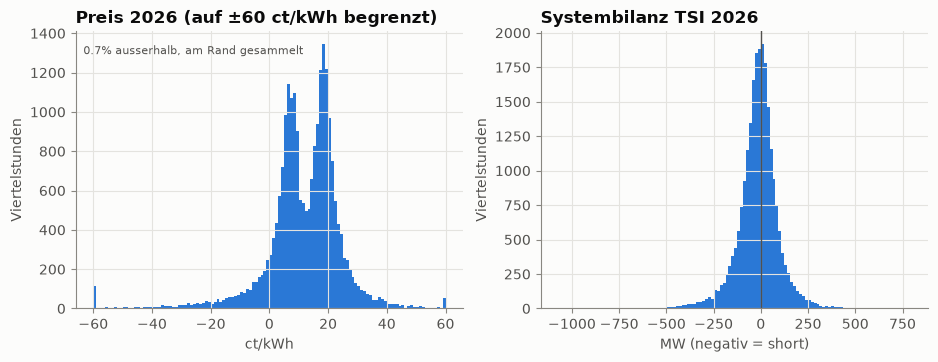

In [9]:
#--------------------------------------------
# Histogramme von Preis und Systembilanz 2026
#--------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(prices["aep_ct_kwh"].clip(-60, 60), bins=120, color=BLUE)
axes[0].set(title="Preis 2026 (auf ±60 ct/kWh begrenzt)", xlabel="ct/kWh", ylabel="Viertelstunden")
outside = (~prices["aep_ct_kwh"].between(-60, 60)).mean()
axes[0].text(0.02, 0.95, f"{outside:.1%} ausserhalb, am Rand gesammelt", transform=axes[0].transAxes, color=INK_2, fontsize=8, va="top")
axes[1].hist(cab["tsi_mw"], bins=120, color=BLUE)
axes[1].axvline(0, color=INK_2, linewidth=1)
axes[1].set(title="Systembilanz TSI 2026", xlabel="MW (negativ = short)", ylabel="Viertelstunden")
plt.show()

#### **Erkenntnisse**

Der Preis ist stark linksschief, die TSI etwa symmetrisch um 0. Die Ausreisser sind echte Werte und bleiben erhalten.

**Preis 2026 mit langem negativem Rand**
- **Lage:** Median 13.1 ct/kWh, Mittel 11.6 ct/kWh
- **Spanne:** von **−688** bis **+172** ct/kWh
- **Schiefe:** stark linksschief, der linke Rand ist viel länger
    - 1 %-Quantil −38 ct/kWh
    - 99 %-Quantil +42 ct/kWh
- **Negative Preise:** rund 11 % der Viertelstunden
- **Form:** schmaler Kern um 10 bis 20 ct/kWh

**TSI etwa symmetrisch**
- **Spanne:** zwischen −1072 und +792 MW, eingipflig um 0
- **Knappheit:** Die Schwellen der Swissgrid-Webseite (−1200 / +1000 MW) wurden **nie** erreicht

**Ausreisser sind echte Werte**
- Die IQR-Regel markiert beim Preis einige Prozent (Tabelle)
- Die Extremwerte decken sich mit hohen |TSI| (H4) und mit den finalen Monatsdateien von Swissgrid
- Kein Hinweis auf Platzhalterwerte (z.B. gehäuft 0 oder 999)
- **Nichts entfernen**

Für die Modellierung heisst das robuste Verluste bzw. Quantile statt mittlerer quadratischer Fehler.

### **1.1.6) Zusammenhänge derselben Viertelstunde**

In [10]:
#---------------------------------------------------------------------------------------------
# Rangkorrelation des Preises mit den Bilanzgrössen derselben Viertelstunde (nur beschreibend)
#---------------------------------------------------------------------------------------------
joint = cab.merge(prices[["timestamp_utc", "aep_ct_kwh"]], on="timestamp_utc", how="inner")
print("price columns identical:", np.allclose(joint["price_ct_kwh"], joint["aep_ct_kwh"]), f"({len(joint)} quarter hours)")
corr = joint[["aep_ct_kwh"] + columns + ["frce_pos_mw", "frce_neg_mw"]].corr(method="spearman")
corr["aep_ct_kwh"].drop("aep_ct_kwh").round(2).sort_values()

price columns identical: True (23324 quarter hours)


tsi_mw           -0.77
frce_neg_mw      -0.05
frce_pos_mw       0.08
igcc_import_mw    0.34
igcc_export_mw    0.35
mfrr_sa_neg_mw    0.39
mfrr_sa_pos_mw    0.40
afrr_neg_mw       0.53
afrr_pos_mw       0.57
Name: aep_ct_kwh, dtype: float64

#### **Erkenntnisse**

Der Preis hängt eng mit den Bilanzgrössen derselben Viertelstunde zusammen. Diese Grössen erklären den Mechanismus, sind aber keine Merkmale.

- **Doppelte Grösse:**
    - `price_ct_kwh` der Regelzonenbilanz ist für Januar bis August zu 100 % identisch mit dem finalen Preis
    - Dieselbe Grösse, nicht zweimal verwenden
- **TSI:** Rangkorrelation Preis und TSI **−0.77** (wie in `docs/data.md`)
- **Abrufe:**
    - Positive Regelenergie (`afrr_pos`, `mfrr_sa_pos`) geht mit hohen Preisen einher
    - Negative Regelenergie geht mit tiefen Preisen einher
- **Verbot als Merkmal:** All diese Grössen der Zielviertelstunde sind um 11:00 an D−1 unbekannt

### **1.1.7) Abdeckung pro Monat**

In [11]:
#------------------------------------------------------
# Anzahl Viertelstunden bzw. Tage pro Monat und Tabelle
#------------------------------------------------------
pd.DataFrame({
    "prices": prices.groupby(prices["timestamp_local"].dt.month).size(),
    "cab": cab.groupby(cab["timestamp_local"].dt.month).size(),
    "weather_days": weather.groupby(weather["delivery_day"].dt.month)["delivery_day"].nunique(),
})

,prices,cab,weather_days
1,2976,2976,31
2,2688,2688,28
3,2972,2972,31
4,2880,2880,30
5,2976,2976,31
6,2880,2880,30
7,2976,2976,31
8,2976,2976,31


#### **Erkenntnisse**

Es gibt keine Ausfälle oder Verdopplungen über die Zeit.

- **Monate:**
    - Jeder Monat ist voll (Tage × 96 Viertelstunden, im März 4 weniger)
- **Saison:**
    - Alle Tabellen nur Januar bis August, September und Oktober sind die Testperiode
    - Herbst und Winter-Ende fehlen

---
## **1.2) Muster von Systembilanz und Preis (H1 bis H8)**

Für H1 bis H7 dient eine gemeinsame Tabelle pro Viertelstunde mit TSI und Preis (bis **31.08.2026**), PV-gewichteter Strahlungsprognose, Uhrzeit, Wochentag, Monat und Tagtyp.

In [12]:
#------------------------------------------------------------------------------------
# Gemeinsame Tabelle je Viertelstunde mit TSI, Preis, Strahlungsprognose und Kalender
#------------------------------------------------------------------------------------
weights = sites.set_index("site")["pv_share"]
radiation = eda.weather_to_quarter_hours(weather, weights, ["shortwave_radiation"])
holiday_share = eda.holiday_pv_share(holidays, pv_capacity)

qh = cab[["timestamp_utc", "timestamp_local", "tsi_mw"]].merge(prices[["timestamp_utc", "aep_ct_kwh"]], on="timestamp_utc", how="left")
qh = qh.merge(radiation, left_on="timestamp_utc", right_index=True, how="left")
local = qh["timestamp_local"]
qh = qh.assign(slot=eda.clock_slot(local), hour=local.dt.hour, weekday=local.dt.weekday, month=local.dt.month,
               date=local.dt.date, short=qh["tsi_mw"] < 0)
qh["day_type"] = eda.day_types(qh["date"], holiday_share)
print(qh.shape, "| radiation missing on:", sorted(set(qh.loc[qh["shortwave_radiation"].isna(), "date"])))

(23324, 12) | radiation missing on: [datetime.date(2026, 6, 24)]


Die Strahlung fehlt nur am **24.06.2026**, alle 96 Viertelstunden (Archivlücke). Alle anderen Viertelstunden haben einen Wert.

### **1.2.1) H1 Muster nach Uhrzeit, Wochentag und Monat**

**Frage:** Ist das System zu bestimmten Uhrzeiten, Wochentagen oder Monaten häufiger short oder long?

**Erwartung:** Ja, weil Verbrauch und Solarproduktion einem Tages-, Wochen- und Jahresrhythmus folgen.

**Zeitraum:**
- Für H1 gelten nur Viertelstunden mit Preis (Januar bis August), damit TSI und Preis dieselben Viertelstunden zeigen

In [13]:
#----------------------------------------------
# Zeitraum mit Preis (Januar bis August) für H1
#----------------------------------------------
h1 = qh[qh["aep_ct_kwh"].notna()].copy()  # Jan-Aug: the period with prices
print(f"{h1['date'].min()} .. {h1['date'].max()}, {len(h1)} quarter hours")

2026-01-01 .. 2026-08-31, 23324 quarter hours


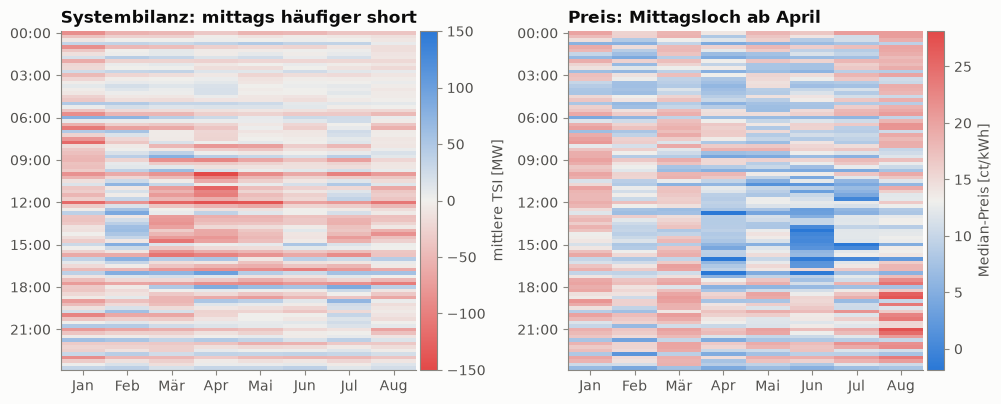

In [14]:
#-------------------------------------------------------------------------------
# Heatmaps der mittleren TSI und des Median-Preises nach Viertelstunde und Monat
#-------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
months = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug"]
for ax, column, limit, label in [(axes[0], "tsi_mw", 150, "mittlere TSI [MW]"), (axes[1], "aep_ct_kwh", 15, "Median-Preis [ct/kWh]")]:
    agg = "mean" if column == "tsi_mw" else "median"
    grid = h1.pivot_table(index="slot", columns="month", values=column, aggfunc=agg)
    # TSI: negative (short) = red like high prices; price: low = blue, high = red
    cmap = DIVERGING.reversed() if column == "tsi_mw" else DIVERGING
    centre = 0.0 if column == "tsi_mw" else float(h1[column].median())
    im = ax.imshow(grid, aspect="auto", cmap=cmap, vmin=centre - limit, vmax=centre + limit, interpolation="nearest")
    ax.set_xticks(range(grid.shape[1]), [months[m - 1] for m in grid.columns])
    ax.set_yticks(range(0, 96, 12), [f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.grid(False)
    fig.colorbar(im, ax=ax, pad=0.01).set_label(label, color=INK_2)
axes[0].set_title("Systembilanz: mittags häufiger short")
axes[1].set_title("Preis: Mittagsloch ab April")
save(fig, "eda_heatmap_tsi_price.png")
plt.show()

In [15]:
#----------------------------------------------
# Anteil short nach Stunde, Wochentag und Monat
#----------------------------------------------
by_hour = h1.groupby("hour")["short"].mean()
print(f"share short overall {h1['short'].mean():.3f}")
print(f"by hour min/max: {by_hour.min():.3f} ({by_hour.idxmin()}h) / {by_hour.max():.3f} ({by_hour.idxmax()}h)")
print("by weekday", h1.groupby("weekday")["short"].mean().round(3).to_dict())
print("by month  ", h1.groupby("month")["short"].mean().round(3).to_dict())
tsi_hour = h1.groupby("hour")["tsi_mw"].mean()
print(f"mean TSI by hour: {tsi_hour.min():.0f} ({tsi_hour.idxmin()}h) .. {tsi_hour.max():.0f} ({tsi_hour.idxmax()}h), std of TSI {h1['tsi_mw'].std():.0f}")

share short overall 0.547
by hour min/max: 0.503 (4h) / 0.617 (13h)
by weekday {0: 0.554, 1: 0.521, 2: 0.527, 3: 0.538, 4: 0.522, 5: 0.579, 6: 0.585}
by month   {1: 0.586, 2: 0.501, 3: 0.58, 4: 0.563, 5: 0.544, 6: 0.516, 7: 0.509, 8: 0.57}
mean TSI by hour: -34 (11h) .. -4 (3h), std of TSI 109


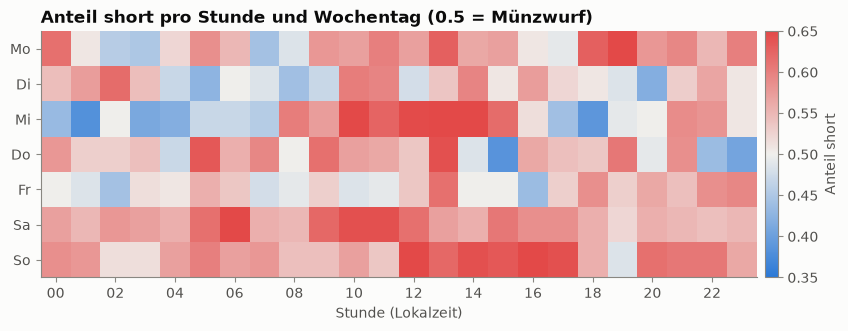

In [16]:
#----------------------------------------------------
# Heatmap des Anteils short nach Stunde und Wochentag
#----------------------------------------------------
grid = h1.pivot_table(index="weekday", columns="hour", values="short", aggfunc="mean")
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(grid, aspect="auto", cmap=DIVERGING, vmin=0.35, vmax=0.65, interpolation="nearest")
ax.set_yticks(range(7), ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set(xlabel="Stunde (Lokalzeit)", title="Anteil short pro Stunde und Wochentag (0.5 = Münzwurf)")
ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.01).set_label("Anteil short", color=INK_2)
save(fig, "eda_short_share.png")
plt.show()

Die Heatmap links zeigt um die Mittagszeit in fast jedem Monat ein rotes Band. Ist die Mittagszeit (10 bis 14 Uhr) in jedem Monat negativer als der Rest des Tages?

In [17]:
#---------------------------------------------------------------------------------------
# TSI und Anteil short über Mittag (10 bis 14 Uhr) gegenüber dem Rest des Tages je Monat
#---------------------------------------------------------------------------------------
midday = h1["hour"].between(10, 14)
per_month = pd.DataFrame({
    "tsi_midday": h1[midday].groupby("month")["tsi_mw"].mean(),
    "tsi_rest": h1[~midday].groupby("month")["tsi_mw"].mean(),
    "short_midday": h1[midday].groupby("month")["short"].mean(),
    "short_rest": h1[~midday].groupby("month")["short"].mean(),
})
print(f"all months: TSI midday {h1.loc[midday, 'tsi_mw'].mean():.1f} vs rest {h1.loc[~midday, 'tsi_mw'].mean():.1f} MW, "
      f"short {h1.loc[midday, 'short'].mean():.3f} vs {h1.loc[~midday, 'short'].mean():.3f}")
print("months with midday more negative:", int((per_month["tsi_midday"] < per_month["tsi_rest"]).sum()), "of", len(per_month))
per_month.round(2)

all months: TSI midday -32.4 vs rest -9.0 MW, short 0.586 vs 0.536
months with midday more negative: 7 of 8


,tsi_midday,tsi_rest,short_midday,short_rest
month,,,,
1,-28.84,-22.79,0.59,0.59
2,18.84,0.01,0.49,0.50
3,-53.76,-10.60,0.63,0.57
4,-65.56,-7.19,0.69,0.53
5,-41.77,-11.05,0.60,0.53
6,-19.03,-7.84,0.51,0.52
7,-25.91,-1.12,0.54,0.50
8,-38.99,-10.58,0.61,0.56


Die Heatmap zeigt ausserdem horizontale Streifen, das Tagesprofil in H7 ein Sägezahnmuster. Darum zusätzlich: Hängt es von der **Position der Viertelstunde in der Stunde** ab?

In [18]:
#---------------------------------------------------------
# Kennzahlen nach Position der Viertelstunde in der Stunde
#---------------------------------------------------------
h1["minute"] = h1["timestamp_local"].dt.minute
within_hour = h1.groupby("minute").agg(short=("short", "mean"), tsi_median=("tsi_mw", "median"),
                                       price_median=("aep_ct_kwh", "median"), negative=("aep_ct_kwh", lambda s: (s < 0).mean()))
print(within_hour.round(3).to_string())
by_month_minute = h1.pivot_table(index="month", columns="minute", values="short", aggfunc="mean")
print("\nshare short at :00 above :45 in", int((by_month_minute[0] > by_month_minute[45]).sum()), "of", len(by_month_minute), "months")

        short  tsi_median  price_median  negative
minute                                           
0       0.584     -18.544         14.52     0.115
15      0.554      -9.715         13.59     0.096
30      0.548      -8.718         13.09     0.090
45      0.501      -0.267         11.09     0.122

share short at :00 above :45 in 8 of 8 months


#### **Erkenntnisse**

Die TSI hat ein Muster nach Uhrzeit, Wochentag und Monat, aber nur ein schwaches. Deutlich ist allein die Position der Viertelstunde in der Stunde (Januar bis August).

**Mittags häufiger short**
- **Mittlere TSI:** zwischen 10 und 14 Uhr **−32 MW**, im Rest des Tages −9 MW
- **Anteil short:** **59 %** gegenüber 54 %
- **Monate:** gilt in **7 von 8 Monaten**, nur im Februar nicht
- **Stärkster Monat:** April mit −66 gegenüber −7 MW
- **Je Stunde:** Anteil short von 50 % (04 Uhr) bis 62 % (13 Uhr)

**Wochentag und Monat nur schwach**
- **Wochentag:** Samstag und Sonntag etwas häufiger short (58 % und 59 %) als Werktage (52 % bis 55 %)
- **Monat:** Anteil short zwischen 50 % (Februar) und 59 % (Januar), ohne klare Saison
- **Klein gegen die Streuung:**
    - Standardabweichung der TSI 109 MW, Unterschied Mittag gegenüber Rest 23 MW
    - Das Muster verschiebt die Wahrscheinlichkeit für short um wenige Prozentpunkte, es bestimmt die Richtung nicht

**Position in der Stunde deutlich**
- **Anteil short:** die erste Viertelstunde (:00) zu **58 %**, die letzte (:45) nur zu **50 %**
- **Median-TSI:** −19 gegenüber 0 MW
- **Median-Preis:** **14.5** gegenüber **11.1** ct/kWh
- **Monate:** gilt in **allen 8 Monaten**
- **Deutung (Vermutung):** Fahrpläne wechseln zur vollen Stunde in Stufen, Erzeugung und Verbrauch folgen gleitend

**Preis mit Mittagsloch**
- Der Preis hat ein deutliches Mittagsloch ab April (Heatmap rechts)
- Das obwohl die TSI mittags eher short ist (siehe H3)

Uhrzeit, Wochentag und vor allem die Viertelstunde in der Stunde sind sinnvolle Kalendermerkmale, alle ohne Einschränkung erlaubt.

### **1.2.2) H2 Stabilität der Richtung über mehrere Tage**

**Frage:** Ist das System zur gleichen Uhrzeit 2, 3 oder 7 Tage später wieder in derselben Richtung (short oder long)?

**Erwartung:** Ja, etwas häufiger als per Zufall, weil sich Wetter und Verbrauch über einige Tage ähneln.

In [19]:
#---------------------------------------------------------------------------
# Übereinstimmung der Richtung zur gleichen Uhrzeit nach 1, 2, 3 und 7 Tagen
#---------------------------------------------------------------------------
matches = eda.direction_matches(cab, [1, 2, 3, 7])
p_short = (cab["tsi_mw"] < 0).mean()
chance = p_short**2 + (1 - p_short) ** 2
print(f"agreement by chance: {chance:.3f}")
matches.groupby("lag_days")["match"].agg(["mean", "size"])

agreement by chance: 0.504


,mean,size
lag_days,,
1,0.551240,23224
2,0.544189,23128
3,0.535950,23032
7,0.537840,22648


In [20]:
#------------------------------------------------------------------
# Autokorrelation von mittlerer TSI und Anteil short auf Tagesebene
#------------------------------------------------------------------
daily = qh.groupby("date").agg(tsi=("tsi_mw", "mean"), short=("short", "mean"))
pd.DataFrame({lag: {"daily mean TSI": daily["tsi"].autocorr(lag), "daily share short": daily["short"].autocorr(lag)}
              for lag in [1, 2, 3, 7]}).round(3)

,1,2,3,7
daily mean TSI,0.193,0.159,0.112,0.022
daily share short,0.233,0.108,0.034,0.007


hourly agreement for lags >= 2: 0.454 .. 0.596


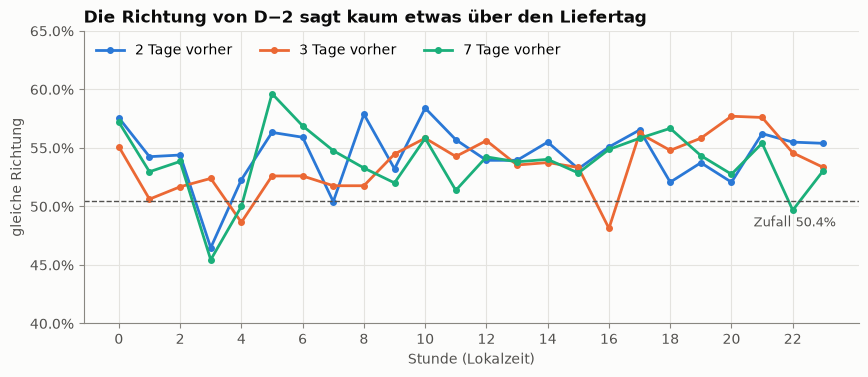

In [21]:
#---------------------------------------------------------------
# Übereinstimmung der Richtung je Stunde für Abstände ab 2 Tagen
#---------------------------------------------------------------
matches["hour"] = matches["slot"] // 4
per_hour = matches[matches["lag_days"] >= 2].groupby(["lag_days", "hour"])["match"].mean().unstack(0)
print(f"hourly agreement for lags >= 2: {per_hour.min().min():.3f} .. {per_hour.max().max():.3f}")
fig, ax = plt.subplots(figsize=(10, 3.8))
for colour, lag in zip(CATEGORICAL, per_hour.columns):
    ax.plot(per_hour.index, per_hour[lag], color=colour, marker="o", markersize=4, label=f"{lag} Tage vorher")
ax.axhline(chance, color=INK_2, linewidth=1, linestyle="--")
ax.text(23.4, chance - 0.012, f"Zufall {chance:.1%}", color=INK_2, ha="right", va="top", fontsize=9)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set(ylim=(0.4, 0.65), xticks=range(0, 24, 2), xlabel="Stunde (Lokalzeit)", ylabel="gleiche Richtung",
       title="Die Richtung von D−2 sagt kaum etwas über den Liefertag")
ax.legend(loc="upper left", ncols=3)
save(fig, "eda_direction_persistence.png")
plt.show()

#### **Erkenntnisse**

Das System ist zur gleichen Uhrzeit 2, 3 oder 7 Tage später nur knapp öfter in derselben Richtung als per Zufall.

- **Zufallsniveau:** **50.4 %** bei 55 % short
- **Gemessen** (je rund 23'000 Vergleiche, Januar bis August):
    - **54.4 %** nach 2 Tagen
    - **53.6 %** nach 3 Tagen
    - **53.8 %** nach 7 Tagen
    - zum Vergleich der *nicht erlaubte* Abstand von 1 Tag: 55.1 %
- **Tagesebene:** Autokorrelation der mittleren TSI
    - 0.19 nach 1 Tag
    - **0.16 nach 2 Tagen**
    - 0.11 nach 3 Tagen
    - 0.02 nach 7 Tagen
- **Stunden:** Keine Stunde sticht heraus (Spanne siehe Ausgabe über der Grafik)

**Folge**
- Die Vergangenheit bis D−2 trägt wenig zur Richtung am Liefertag bei
- TSI-Merkmale aus der Vergangenheit sind erlaubt (über `known_at_issue()`), aber wenig erfolgversprechend
- Am ehesten nützt ein Mass für das aktuelle *Niveau*, z.B. das Mittel der TSI an D−2
- Vorläufig, solange die Grenze D−2 nicht bestätigt ist

### **1.2.3) H3 Strahlungsprognose und Systembilanz**

**Frage:** Hängt die Strahlungsprognose mit der Systembilanz zusammen oder nur mit dem Preis?

**Erwartung:** Viel Sonne führt zu grösseren Abweichungen und darüber zu anderen Preisen (Weg „Sonne → Abweichung → Preis“).

In [22]:
#------------------------------------------------------------------------
# Rangkorrelation der Strahlungsprognose mit TSI und Preis bei Tageslicht
#------------------------------------------------------------------------
day = qh[qh["shortwave_radiation"] > 50]  # daylight quarter hours


def spearman(frame: pd.DataFrame, a: str, b: str) -> float:
    return frame[[a, b]].corr(method="spearman").iloc[0, 1]


print(f"daylight quarter hours: {len(day)}")
print(f"radiation ~ TSI   {spearman(day, 'shortwave_radiation', 'tsi_mw'):+.3f}")
print(f"radiation ~ |TSI| {spearman(day.assign(a=day['tsi_mw'].abs()), 'shortwave_radiation', 'a'):+.3f}")
print(f"radiation ~ price {spearman(day, 'shortwave_radiation', 'aep_ct_kwh'):+.3f}")
for name, part in [("long", day[day["tsi_mw"] > 0]), ("short", day[day["tsi_mw"] < 0])]:
    print(f"radiation ~ price within {name:5s} {spearman(part, 'shortwave_radiation', 'aep_ct_kwh'):+.3f}  (n={len(part)})")
by_month = {m: spearman(g, "shortwave_radiation", "tsi_mw") for m, g in day.groupby("month")}
print("radiation ~ TSI by month:", {m: round(float(v), 2) for m, v in by_month.items()})

daylight quarter hours: 11300
radiation ~ TSI   -0.076
radiation ~ |TSI| +0.070
radiation ~ price -0.225
radiation ~ price within long  -0.582  (n=5006)
radiation ~ price within short -0.388  (n=6294)
radiation ~ TSI by month: {1: -0.01, 2: 0.0, 3: -0.08, 4: -0.14, 5: -0.12, 6: 0.07, 7: -0.1, 8: -0.13}


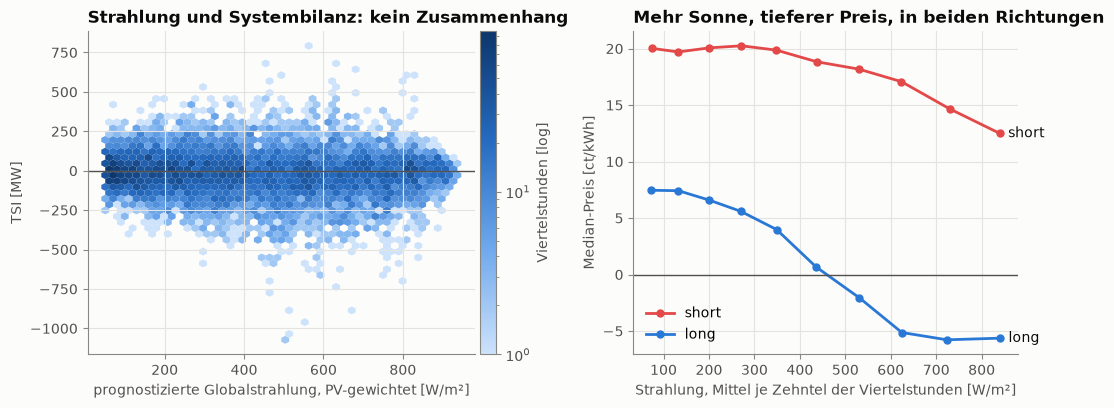

In [23]:
#--------------------------------------------------------------
# Strahlung gegen TSI und Median-Preis je Zehntel der Strahlung
#--------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
hb = axes[0].hexbin(day["shortwave_radiation"], day["tsi_mw"], gridsize=45, bins="log", mincnt=1, linewidths=0, cmap=cmap)
axes[0].axhline(0, color=INK_2, linewidth=1)
axes[0].set(xlabel="prognostizierte Globalstrahlung, PV-gewichtet [W/m²]", ylabel="TSI [MW]",
            title="Strahlung und Systembilanz: kein Zusammenhang")
fig.colorbar(hb, ax=axes[0], pad=0.01).set_label("Viertelstunden [log]", color=INK_2)

priced = day[day["aep_ct_kwh"].notna()]
bins = pd.qcut(priced["shortwave_radiation"], 10)
for colour, name, part in [(RED, "short", priced[priced["short"]]), (BLUE, "long", priced[~priced["short"]])]:
    med = part.groupby(bins.loc[part.index], observed=True).agg(rad=("shortwave_radiation", "mean"), price=("aep_ct_kwh", "median"))
    axes[1].plot(med["rad"], med["price"], color=colour, marker="o", markersize=5, label=name)
    axes[1].annotate(name, (med["rad"].iloc[-1], med["price"].iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
axes[1].axhline(0, color=INK_2, linewidth=1)
axes[1].set(xlabel="Strahlung, Mittel je Zehntel der Viertelstunden [W/m²]", ylabel="Median-Preis [ct/kWh]",
            title="Mehr Sonne, tieferer Preis, in beiden Richtungen")
axes[1].legend(loc="lower left")
save(fig, "eda_radiation_tsi.png")
plt.show()

#### **Erkenntnisse**

Der Weg „Sonne → Abweichung → Preis“ läuft nicht über die TSI.

**Strahlung hängt nicht mit der TSI zusammen**
- Nur Tageslicht, über 11'000 Viertelstunden
- **Mit der TSI:** Rangkorrelation **−0.08**
- **Mit dem Betrag |TSI|:** **+0.07**
- **Monate:** in keinem Monat über 0.14 im Betrag

**Strahlung hängt mit dem Preis zusammen**
- **Alle Viertelstunden:** **−0.23**
- **Innerhalb gleicher Richtung** sogar stärker
    - **−0.58 bei long**
    - **−0.39 bei short**

**Deutung (Vermutung, nicht geprüft)**
- Die Sonne verschiebt nicht die Richtung, sondern das *Preisniveau* der abgerufenen Regelenergie, vermutlich über tiefe Spotpreise an sonnigen Mittagen
- Das passt zum Mittagsloch in H1
- Die *Abweichung* der tatsächlichen Strahlung von der Prognose wäre die fachlich richtige Grösse für die TSI, ist um 11:00 aber nicht bekannt

Die Strahlungsprognose (Lauf D−2 18 UTC, erlaubt) ist ein starker Kandidat **für das Preisniveau**, nicht für die Richtung.

### **1.2.4) H4 Extrempreise**

**Frage:** Wann treten Extrempreise unter −100 und über +50 ct/kWh auf?

**Erwartung:** Sie häufen sich zu bestimmten Uhrzeiten, Wochentagen und Monaten, an Feiertagen und bei grosser |TSI|.

In [24]:
#---------------------------------------------------------------------
# Extremereignisse unter −100 und über +50 ct/kWh nach Zeit und Tagtyp
#---------------------------------------------------------------------
events = eda.extreme_events(prices, low=-100, high=50)
extreme = qh[qh["aep_ct_kwh"].notna()].assign(
    kind=lambda d: np.select([d["aep_ct_kwh"] < -100, d["aep_ct_kwh"] > 50], ["low", "high"], "none"))
extreme = extreme[extreme["kind"] != "none"]
print(events.groupby("kind").agg(events=("start", "size"), quarter_hours=("quarter_hours", "sum"), longest=("quarter_hours", "max")))
print(f"share of quarter hours: {len(extreme) / qh['aep_ct_kwh'].notna().sum():.2%}")
for kind in ["low", "high"]:
    part = extreme[extreme["kind"] == kind]
    print(f"\n{kind}: {part['date'].nunique()} days, TSI median {part['tsi_mw'].median():.0f} MW, "
          f"range {part['tsi_mw'].min():.0f} .. {part['tsi_mw'].max():.0f}")
    print("  hours   ", part["hour"].value_counts().sort_index().to_dict())
    print("  weekday ", part["weekday"].value_counts().sort_index().to_dict())
    print("  months  ", part["month"].value_counts().sort_index().to_dict())
    print("  day type", part["day_type"].value_counts().to_dict())
events.sort_values("extreme").iloc[[0, 1, 2, -3, -2, -1]]

      events  quarter_hours  longest
kind                                
high      71            110        7
low       20             43        6
share of quarter hours: 0.66%

low: 17 days, TSI median 335 MW, range 48 .. 662
  hours    {10: 3, 11: 5, 12: 10, 13: 11, 14: 8, 15: 4, 16: 2}
  weekday  {0: 5, 1: 8, 2: 3, 4: 4, 5: 10, 6: 13}
  months   {2: 6, 3: 8, 4: 8, 5: 5, 6: 4, 7: 8, 8: 4}
  day type {'Werktag': 15, 'Sonntag': 13, 'Samstag': 10, 'Feiertag': 5}

high: 41 days, TSI median -312 MW, range -1072 .. -2
  hours    {1: 2, 2: 1, 3: 1, 4: 1, 6: 1, 7: 7, 8: 7, 9: 8, 10: 12, 11: 15, 12: 6, 13: 2, 14: 8, 15: 3, 16: 3, 17: 4, 18: 6, 19: 7, 20: 6, 21: 4, 22: 4, 23: 2}
  weekday  {0: 26, 1: 20, 2: 33, 3: 15, 4: 2, 5: 1, 6: 13}
  months   {1: 21, 2: 3, 3: 15, 4: 5, 5: 8, 6: 21, 7: 16, 8: 21}
  day type {'Werktag': 96, 'Sonntag': 13, 'Samstag': 1}


,kind,start,end,quarter_hours,extreme
22,low,2026-03-28 09:30:00+00:00,2026-03-28 10:45:00+00:00,6,-688.48
66,low,2026-07-19 10:00:00+00:00,2026-07-19 10:30:00+00:00,3,-429.10
39,low,2026-05-19 10:30:00+00:00,2026-05-19 11:15:00+00:00,4,-335.22
62,high,2026-07-01 08:45:00+00:00,2026-07-01 10:00:00+00:00,6,138.28
4,high,2026-01-08 08:15:00+00:00,2026-01-08 08:45:00+00:00,3,138.44
11,high,2026-02-18 07:00:00+00:00,2026-02-18 07:15:00+00:00,2,171.93


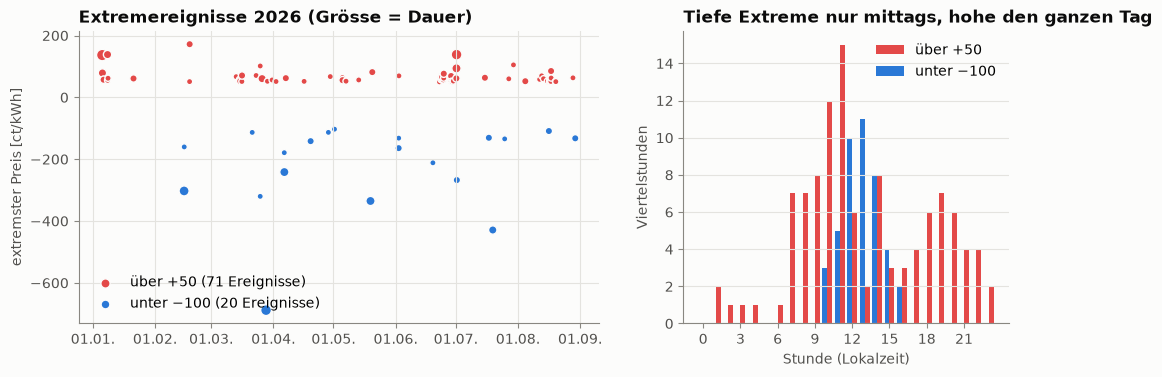

In [25]:
#-----------------------------------------------
# Extremereignisse über das Jahr und nach Stunde
#-----------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for colour, kind, label in [(RED, "high", "über +50"), (BLUE, "low", "unter −100")]:
    part = events[events["kind"] == kind]
    axes[0].scatter(part["start"].dt.tz_convert(TZ).dt.tz_localize(None), part["extreme"], s=12 + 8 * part["quarter_hours"],
                    color=colour, edgecolor=SURFACE, linewidth=1, label=f"{label} ({len(part)} Ereignisse)")
    counts = extreme[extreme["kind"] == kind]["hour"].value_counts().reindex(range(24), fill_value=0)
    axes[1].bar(counts.index + (0.2 if kind == "high" else -0.2), counts, width=0.4, color=colour, label=label)
axes[0].set(ylabel="extremster Preis [ct/kWh]", title="Extremereignisse 2026 (Grösse = Dauer)")
axes[0].legend(loc="lower left")
axes[0].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%d.%m."))
axes[1].set(xlabel="Stunde (Lokalzeit)", ylabel="Viertelstunden", xticks=range(0, 24, 3), title="Tiefe Extreme nur mittags, hohe den ganzen Tag")
axes[1].legend(loc="upper right")
axes[1].grid(axis="x", visible=False)
save(fig, "eda_extremes.png")
plt.show()

#### **Erkenntnisse**

Extrempreise sind selten und an Richtung, Tageszeit und Wochentag gebunden.

**Unter −100 ct/kWh nur mittags bei long**
- **Umfang:** 43 Viertelstunden in 20 Ereignissen an 17 Tagen, Februar bis August
- **Uhrzeit:** **nur zwischen 10 und 16 Uhr**
- **Wochentag:** gehäuft am **Wochenende**, 23 von 43 an Samstag oder Sonntag
- **TSI:** immer **long**, +48 bis +662 MW, Median +335 MW
- **Tiefster Wert:** −688 ct/kWh am **28.03.2026**

**Über +50 ct/kWh bei short an Werktagen**
- **Umfang:** 110 Viertelstunden in 71 Ereignissen an 41 Tagen
- **Uhrzeit:** über den Tag verteilt, Schwerpunkt **07 bis 11 Uhr** und abends
- **Wochentag:** fast nur **Montag bis Donnerstag**, Freitag und Samstag kaum, Sonntag 13
- **TSI:** immer **short**, −1072 bis −2 MW, Median −312 MW

**Ereignisse sind kurz**
- meist 1 bis 3 Viertelstunden, das längste 7
- insgesamt 0.7 % der Viertelstunden

**Folge**
- Die Richtung selbst ist um 11:00 unbekannt (H2)
- Ein Modell sollte Extreme über breite obere und untere Quantile abbilden, nicht als Punktwert

### **1.2.5) H5 Preise 2025 und 2026**

**Frage:** Lassen sich die parallel publizierten Preise `aep_ct_kwh` von Juli bis Dezember 2025 zusätzlich nutzen?

**Erwartung:** Sie sind ähnlich verteilt wie 2026. Dann wären 6 Monate mehr Trainingsdaten nutzbar.

In [26]:
#----------------------------------------------------------------------------
# Preise Juli bis Dezember 2025 mit 2026 vergleichen, KS-Abstand und Quantile
#----------------------------------------------------------------------------
local_all = prices_all["timestamp_local"]
p25 = prices_all[(local_all >= pd.Timestamp("2025-07-01", tz=TZ)) & (local_all < pd.Timestamp("2026-01-01", tz=TZ))]
p26 = prices
print("2025 aep equals long / short price:", np.isclose(p25["aep_ct_kwh"], p25["long_ct_kwh"]).mean(),
      np.isclose(p25["aep_ct_kwh"], p25["short_ct_kwh"]).mean())


def ks_statistic(a: np.ndarray, b: np.ndarray) -> float:
    a, b = np.sort(a), np.sort(b)
    grid = np.concatenate([a, b])
    return float(np.max(np.abs(np.searchsorted(a, grid, side="right") / len(a) - np.searchsorted(b, grid, side="right") / len(b))))


def describe(s: pd.Series) -> pd.Series:
    q = s.quantile([0.01, 0.1, 0.5, 0.9, 0.99]).rename(lambda x: f"P{int(round(x * 100))}")
    return pd.concat([q, pd.Series({"mean": s.mean(), "std": s.std(), "negative": (s < 0).mean(), "n": len(s)})])


summer25 = p25[p25["timestamp_local"].dt.month <= 8]["aep_ct_kwh"]
summer26 = p26[p26["timestamp_local"].dt.month >= 7]["aep_ct_kwh"]
print(f"KS distance all {ks_statistic(p25['aep_ct_kwh'].to_numpy(), p26['aep_ct_kwh'].to_numpy()):.3f}, "
      f"Jul-Aug vs Jul-Aug {ks_statistic(summer25.to_numpy(), summer26.to_numpy()):.3f}")
# One row per period, two comparisons: same season (Jul-Aug) and everything available.
pd.DataFrame({
    ("gleiche Saison", "2025 Jul-Aug"): describe(summer25), ("gleiche Saison", "2026 Jul-Aug"): describe(summer26),
    ("alles verfügbare", "2025 Jul-Dez"): describe(p25["aep_ct_kwh"]), ("alles verfügbare", "2026 Jan-Aug"): describe(p26["aep_ct_kwh"]),
}).T.round(2)

2025 aep equals long / short price: 0.0 0.0
KS distance all 0.183, Jul-Aug vs Jul-Aug 0.304


P1    P10    P50    P90    P99   mean  \
gleiche Saison   2025 Jul-Aug -44.44 -12.20   6.40  22.66  44.91   6.38   
                 2026 Jul-Aug -33.89  -1.20  12.92  27.10  45.40  12.75   
alles verfügbare 2025 Jul-Dez -40.63  -7.76  15.42  24.38  41.73   9.69   
                 2026 Jan-Aug -38.48  -0.56  13.13  23.97  42.07  11.56   

                                 std  negative        n  
gleiche Saison   2025 Jul-Aug  17.92      0.36   5952.0  
                 2026 Jul-Aug  16.59      0.11   5952.0  
alles verfügbare 2025 Jul-Dez  19.19      0.24  17668.0  
                 2026 Jan-Aug  16.42      0.11  23324.0

month     2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08
negative    0.398    0.316    0.312    0.184    0.146    0.101    0.045    0.058    0.073    0.166    0.130    0.152    0.133    0.089
median      3.260   13.015   12.265   17.820   18.915   16.305   16.620   12.365   17.040    9.880   11.825   11.145   11.755   16.915


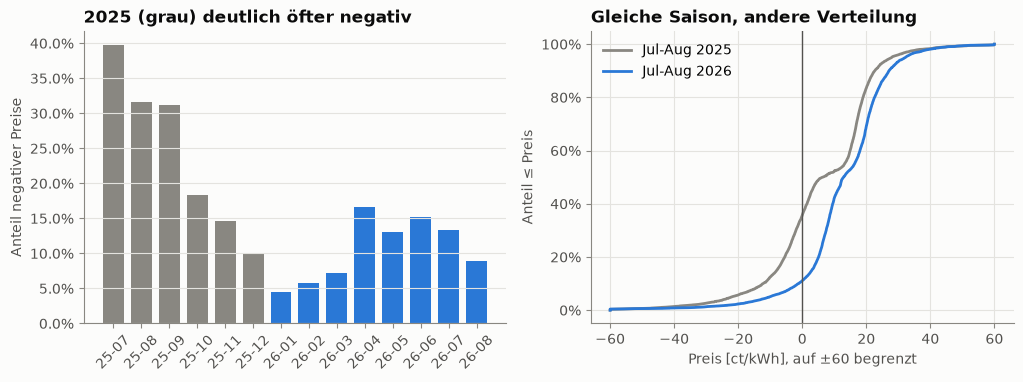

In [27]:
#-----------------------------------------------------------------------------
# Anteil negativer Preise je Monat und Verteilung Juli bis August beider Jahre
#-----------------------------------------------------------------------------
monthly = pd.concat([p25, p26]).assign(month=lambda d: d["timestamp_local"].dt.strftime("%Y-%m"))
monthly = monthly.groupby("month")["aep_ct_kwh"].agg(negative=lambda s: (s < 0).mean(), median="median")
print(monthly.round(3).T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colours = [MUTED if m < "2026" else BLUE for m in monthly.index]
axes[0].bar(range(len(monthly)), monthly["negative"], color=colours, width=0.75)
axes[0].set_xticks(range(len(monthly)), [m[2:] for m in monthly.index], rotation=45)
axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0].set(ylabel="Anteil negativer Preise", title="2025 (grau) deutlich öfter negativ")
axes[0].grid(axis="x", visible=False)
for colour, label, s in [(MUTED, "Jul-Aug 2025", summer25), (BLUE, "Jul-Aug 2026", summer26)]:
    x = np.sort(s.clip(-60, 60))
    axes[1].plot(x, np.arange(1, len(x) + 1) / len(x), color=colour, label=label)
axes[1].axvline(0, color=INK_2, linewidth=1)
axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[1].set(xlabel="Preis [ct/kWh], auf ±60 begrenzt", ylabel="Anteil ≤ Preis", title="Gleiche Saison, andere Verteilung")
axes[1].legend(loc="upper left")
save(fig, "eda_2025_vs_2026.png")
plt.show()

#### **Erkenntnisse**

Die parallel publizierten Preise von Juli bis Dezember 2025 sind deutlich anders verteilt als 2026.

**Echte Parallelrechnung**
- `aep_ct_kwh` 2025 ist keiner der beiden damaligen Preise
- 0 % identisch mit long oder short

**Gleiche Saison deutlich verschieden** (Juli und August)
- **Negative Preise:** 2025 **36 %** der Viertelstunden, 2026 nur **11 %**
- **Median:** 6.4 gegenüber 12.9 ct/kWh
- **P10:** −12.2 gegenüber −1.2 ct/kWh
- **Kolmogorov-Smirnov-Abstand:** **0.30**

**Über alle Monate**
- **Negative Preise:** 24 % gegenüber 11 %
- **KS-Abstand:** 0.18
- **Verlauf 2025:** Anteil negativer Preise fällt von 40 % (Juli) auf 10 % (Dezember)
- **Verlauf 2026:** zwischen 5 % und 17 %

**Kein p-Wert**
- Ein p-Wert wird bewusst **nicht** angegeben
- Benachbarte Viertelstunden sind stark abhängig, der übliche KS-Test wäre viel zu zuversichtlich

**Deutung (Vermutung)**
- Unter dem Zweipreissystem haben die Bilanzgruppen anders gehandelt
- Die Parallelrechnung legt den neuen Preis auf altes Verhalten

**Die Owner-Entscheidung „nur Daten ab 2026“ wird gestützt.** Die Preise 2025 eignen sich höchstens für einen Robustheitstest, nicht als Trainingsdaten.

### **1.2.6) H6 Feiertage und Brückentage**

**Frage:** Verhalten sich Preis und TSI an Feiertagen und Brückentagen anders als an Werktagen und Wochenenden?

**Erwartung:** Ja, Feiertage ähneln Sonntagen, weil weniger Strom verbraucht wird.

In [28]:
#--------------------------
# Preis und TSI nach Tagtyp
#--------------------------
with_price = qh[qh["aep_ct_kwh"].notna()]
special = with_price.drop_duplicates("date").query("day_type in @eda.HOLIDAY or day_type in @eda.BRIDGE_DAY")
print("holidays and bridge days with prices:", [(f"{d:%d.%m.}", t) for d, t in zip(special["date"], special["day_type"])])
with_price.groupby("day_type").agg(days=("date", "nunique"), price_median=("aep_ct_kwh", "median"),
                                   negative=("aep_ct_kwh", lambda s: (s < 0).mean()),
                                   tsi_mean=("tsi_mw", "mean"), short=("short", "mean")).reindex(eda.DAY_TYPES).round(3)

holidays and bridge days with prices: [('01.01.', 'Feiertag'), ('02.01.', 'Brückentag'), ('03.04.', 'Feiertag'), ('06.04.', 'Feiertag'), ('14.05.', 'Feiertag'), ('15.05.', 'Brückentag'), ('25.05.', 'Feiertag')]


,days,price_median,negative,tsi_mean,short
day_type,,,,,
Werktag,166,13.590,0.077,-11.673,0.532
Brückentag,2,13.935,0.161,-10.855,0.531
Samstag,35,12.895,0.157,-18.370,0.579
Sonntag,35,12.060,0.167,-20.859,0.585
Feiertag,5,8.440,0.258,-8.679,0.535


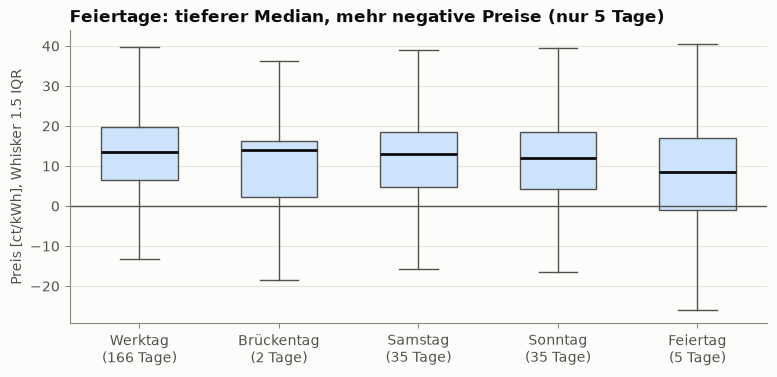

In [29]:
#-----------------------------------
# Verteilung des Preises nach Tagtyp
#-----------------------------------
fig, ax = plt.subplots(figsize=(9, 3.8))
data = [with_price.loc[with_price["day_type"] == t, "aep_ct_kwh"] for t in eda.DAY_TYPES]
parts = ax.boxplot(data, showfliers=False, widths=0.55, patch_artist=True, medianprops={"color": INK, "linewidth": 2},
                   whiskerprops={"color": INK_2}, capprops={"color": INK_2})
for box in parts["boxes"]:
    box.set(facecolor="#cde2fb", edgecolor=INK_2)
days = with_price.groupby("day_type")["date"].nunique()
ax.set_xticks(range(1, 6), [f"{t}\n({days.get(t, 0)} Tage)" for t in eda.DAY_TYPES])
ax.axhline(0, color=INK_2, linewidth=1)
ax.set(ylabel="Preis [ct/kWh], Whisker 1.5 IQR", title="Feiertage: tieferer Median, mehr negative Preise (nur 5 Tage)")
ax.grid(axis="x", visible=False)
save(fig, "eda_day_types.png")
plt.show()

#### **Erkenntnisse**

Feiertage unterscheiden sich, die Datenlage ist aber sehr dünn.

**Definition und Umfang**
- Als Feiertag zählt ein Montag bis Freitag, an dem Kantone mit mindestens **50 % der PV-Leistung** frei haben (`eda.day_types`)
- **Feiertage bis 31.08.2026:** nur **5 Tage**, nämlich 01.01., Karfreitag, Ostermontag, Auffahrt und Pfingstmontag
- **Brückentage:** **2 Tage**, nämlich 02.01. und Freitag nach Auffahrt
- Der 01.08. fiel auf einen Samstag

**Feiertage wie Sonntage, nur stärker**
- **Feiertage:** Median-Preis **8.4** ct/kWh, **26 %** negativ
- **Werktage:** 13.6 ct/kWh, **8 %** negativ
- **Wochenenden:** 12 bis 13 ct/kWh, 16 bis 17 % negativ
- Vier der fünf Feiertage liegen im sonnigen Frühling

**TSI und Brückentage**
- Die TSI unterscheidet sich kaum, Anteil short 53 % bis 59 % über alle Tagtypen
- Zu Brückentagen ist mit 2 Tagen keine Aussage möglich

**Folge**
- Ein Merkmal „Anteil der PV-Leistung mit Feiertag“ bzw. ein Tagtyp ist erlaubt und plausibel nützlich
- Der Effekt ist mit 5 Tagen statistisch nicht abgesichert und mit der Saison vermischt

### **1.2.7) H7 Tagesprofil des Preises**

**Frage:** Wie verläuft der Preis über die 96 Viertelstunden des Tages?

**Erwartung:** Er hat ein typisches Tagesprofil, und seine Streuung hängt von der Uhrzeit ab.

In [30]:
#----------------------------------------------------------------------
# Tagesprofil P10, P50 und P90 je Viertelstunde, gesamt und nach Saison
#----------------------------------------------------------------------
def clock(slot: int) -> str:
    return f"{slot // 4:02d}:{slot % 4 * 15:02d}"


profile = with_price.groupby("slot")["aep_ct_kwh"].quantile([0.1, 0.5, 0.9]).unstack()
width = profile[0.9] - profile[0.1]
print(f"median lowest {profile[0.5].min():.1f} at {clock(profile[0.5].idxmin())}, highest {profile[0.5].max():.1f} at {clock(profile[0.5].idxmax())}")
print(f"P10-P90 widest {width.max():.1f} at {clock(width.idxmax())}, narrowest {width.min():.1f} at {clock(width.idxmin())}")
summer = with_price[with_price["month"].between(4, 8)].groupby("slot")["aep_ct_kwh"].quantile([0.1, 0.5, 0.9]).unstack()
winter = with_price[with_price["month"] <= 3].groupby("slot")["aep_ct_kwh"].quantile([0.1, 0.5, 0.9]).unstack()
for name, frame in [("Jan-Mar", winter), ("Apr-Aug", summer)]:
    print(f"{name}: P10 lowest {frame[0.1].min():.1f} at {clock(frame[0.1].idxmin())}, median lowest {frame[0.5].min():.1f} at {clock(frame[0.5].idxmin())}")

median lowest 6.2 at 10:45, highest 19.0 at 21:00
P10-P90 widest 46.5 at 17:00, narrowest 15.2 at 03:15
Jan-Mar: P10 lowest -6.1 at 11:45, median lowest 6.3 at 23:45
Apr-Aug: P10 lowest -31.9 at 13:45, median lowest 1.2 at 16:00


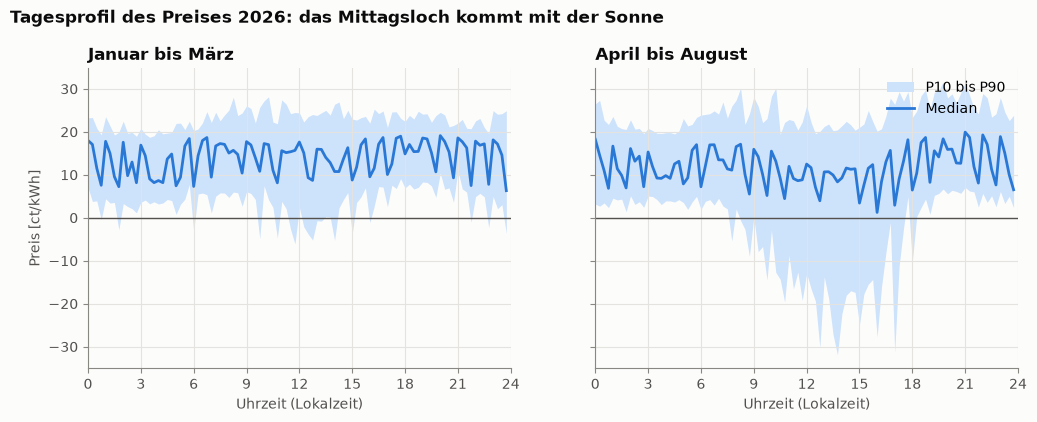

In [31]:
#-------------------------------------------------
# Tagesprofil Januar bis März und April bis August
#-------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, frame, title in [(axes[0], winter, "Januar bis März"), (axes[1], summer, "April bis August")]:
    x = frame.index / 4
    ax.fill_between(x, frame[0.1], frame[0.9], color="#cde2fb", linewidth=0, label="P10 bis P90")
    ax.plot(x, frame[0.5], color=BLUE, label="Median")
    ax.axhline(0, color=INK_2, linewidth=1)
    ax.set(xlabel="Uhrzeit (Lokalzeit)", xticks=range(0, 25, 3), xlim=(0, 24), title=title)
axes[0].set_ylabel("Preis [ct/kWh]")
axes[1].legend(loc="upper right")
fig.suptitle("Tagesprofil des Preises 2026: das Mittagsloch kommt mit der Sonne", x=0.06, y=1.03, ha="left", fontweight="bold", color=INK)
save(fig, "eda_daily_profile.png")
plt.show()

#### **Erkenntnisse**

Der Preis hat ein ausgeprägtes Tagesprofil, und seine Streuung hängt von Uhrzeit und Saison ab.

**Tagesprofil 2026**
- **Median:** am tiefsten um **10:45 (6.2 ct/kWh)**, am höchsten um **21:00 (19.0 ct/kWh)**
- **Streuung P10 bis P90:**
    - am **Nachmittag am grössten**, 46.5 ct/kWh um 17:00
    - in der **Nacht am kleinsten**, 15.2 ct/kWh um 03:15, also rund dreimal schmaler
- **Sägezahnmuster:** innerhalb jeder Stunde, der Effekt der Viertelstunden-Position aus H1

**Die Saison verändert das Profil stark**
- **April bis August:** P10 fällt über Mittag bis **−31.9** ct/kWh (13:45), der Median bis 1.2 ct/kWh (16:00)
- **Januar bis März:** P10 erreicht nur **−6.1** ct/kWh (11:45)
- Ein einziges Profil für alle Monate wäre falsch

**Folge für Baseline und Unsicherheit**
- Eine naive Baseline sollte Quantile pro Viertelstunde *und* Saison (bzw. Strahlungsprognose) nutzen
- Die Breite der Bänder muss von der Uhrzeit abhängen

### **1.2.8) H8 Kippen der Systembilanz innerhalb der Stunde**

**Beobachtung:** In Abschnitt `1.2.1) H1 Muster nach Uhrzeit, Wochentag und Monat` ist das System um :00 zu 58 % short, um :45 nur zu 50 %.

**Frage:** Woran liegt das?

**Erklärungsversuch nach Recherche:** Fahrpläne und viele Kraftwerke wechseln zur vollen Stunde in Stufen, Verbrauch und Solarproduktion ändern sich dagegen gleitend. Darum kippt die TSI *innerhalb* jeder Stunde. Die Richtung hängt davon ab, ob die Residuallast (Verbrauch minus PV) gerade steigt oder fällt.
- **Residuallast steigt** (z.B. morgens vor Sonnenaufgang, abends bei Sonnenuntergang)
    - zu Beginn der Stunde noch zu viel Erzeugung, also :00 long
    - am Ende zu wenig, also :45 short
- **Residuallast fällt** (z.B. vormittags mit steigender PV, spätabends)
    - umgekehrt, :00 short und :45 long

**Quellen für den Mechanismus:**
- **EURELECTRIC und ENTSO-E**, „Deterministic frequency deviations: root causes and proposals for potential solutions“ (Dezember 2011)
    - Kraftwerke ändern ihre Einspeisung zur vollen Stunde fast stufenweise, der Verbrauch langsamer
    - am stärksten um 6, 7, 8 und 21, 22, 23 Uhr
- **Swissgrid**, Allgemeine Bilanzgruppenvorschriften v3.2, Ziffer 7.2
    - Fahrplanwechsel werden als Rampe von 5 Minuten vor bis 5 Minuten nach dem Wechsel abgerechnet

In [32]:
#------------------------------------------------------------------------------
# Mittlere TSI je Position in der Stunde und Änderung von :00 bis :45 je Stunde
#------------------------------------------------------------------------------
trend = eda.within_hour_trend(h1)
by_hour = trend.groupby("hour")[["q00", "q15", "q30", "q45", "trend"]].mean()
short_by = h1.pivot_table(index="hour", columns="minute", values="short", aggfunc="mean")
by_hour["short_00"], by_hour["short_45"] = short_by[0], short_by[45]
print(f"{len(trend)} complete hours; mean TSI per quarter hour of the clock hour [MW] and share short at :00 and :45")
by_hour.round(2)

5831 complete hours; mean TSI per quarter hour of the clock hour [MW] and share short at :00 and :45


,q00,q15,q30,q45,trend,short_00,short_45
hour,,,,,,,
0,-49.93,-16.56,-1.73,31.43,81.36,0.80,0.30
1,-34.23,-5.96,-0.77,17.92,52.15,0.69,0.36
2,-27.44,-2.69,-10.19,19.45,46.89,0.67,0.35
3,-19.84,-5.36,1.79,8.08,27.92,0.63,0.45
4,2.72,2.41,-7.21,-13.28,-16.00,0.46,0.57
5,26.20,9.22,-18.20,-44.84,-71.03,0.35,0.79
6,34.69,6.71,-25.94,-43.26,-77.95,0.32,0.70
7,9.41,-3.84,-16.64,-15.35,-24.76,0.43,0.53
8,-38.82,-16.79,3.75,26.17,64.99,0.63,0.36


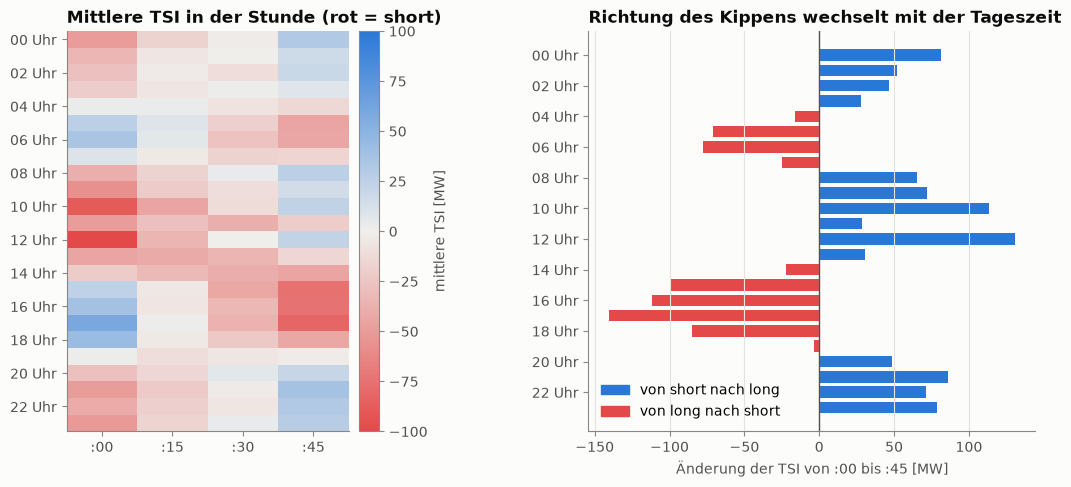

In [33]:
#-----------------------------------------------------
# TSI in der Stunde und Richtung des Kippens je Stunde
#-----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1, 1.3], "wspace": 0.45})
im = axes[0].imshow(by_hour[["q00", "q15", "q30", "q45"]], aspect="auto", cmap=DIVERGING.reversed(), vmin=-100, vmax=100,
                    interpolation="nearest")
axes[0].set_xticks(range(4), [":00", ":15", ":30", ":45"])
axes[0].set_yticks(range(0, 24, 2), [f"{h:02d} Uhr" for h in range(0, 24, 2)])
axes[0].grid(False)
axes[0].set_title("Mittlere TSI in der Stunde (rot = short)")
fig.colorbar(im, ax=axes[0], pad=0.03).set_label("mittlere TSI [MW]", color=INK_2)
colours = [BLUE if v > 0 else RED for v in by_hour["trend"]]
axes[1].barh(by_hour.index, by_hour["trend"], color=colours, height=0.75)
axes[1].axvline(0, color=INK_2, linewidth=1)
axes[1].invert_yaxis()
axes[1].set_yticks(range(0, 24, 2), [f"{h:02d} Uhr" for h in range(0, 24, 2)])
axes[1].set(xlabel="Änderung der TSI von :00 bis :45 [MW]", title="Richtung des Kippens wechselt mit der Tageszeit")
axes[1].legend(handles=[matplotlib.patches.Patch(color=BLUE, label="von short nach long"),
                        matplotlib.patches.Patch(color=RED, label="von long nach short")], loc="lower left")
axes[1].grid(axis="y", visible=False)
save(fig, "eda_within_hour.png")
plt.show()

Welche Regelenergie gleicht das Kippen aus? Mittel der Netto-Abrufe je Position in der Stunde (positiv = Hochregeln, also Ausgleich von short).

In [34]:
#----------------------------------------------------------------------------
# Netto-Abrufe der Regelenergie je Position in der Stunde (Januar bis August)
#----------------------------------------------------------------------------
flows = cab[cab["timestamp_local"] < pd.Timestamp("2026-09-01", tz=TZ)].dropna()
flows = pd.DataFrame({
    "minute": flows["timestamp_local"].dt.minute,
    "tsi_mw": flows["tsi_mw"],
    "afrr_net": flows["afrr_pos_mw"] + flows["afrr_neg_mw"],
    "mfrr_net": flows["mfrr_sa_pos_mw"] + flows["mfrr_sa_neg_mw"],
    "igcc_net": flows["igcc_import_mw"] + flows["igcc_export_mw"],
    "frce_net": flows["frce_pos_mw"] + flows["frce_neg_mw"],
})
flows.groupby("minute").mean().round(1)

,tsi_mw,afrr_net,mfrr_net,igcc_net,frce_net
minute,,,,,
0,-19.5,3.8,17.7,-4.5,2.5
15,-13.6,5.5,12.2,-2.1,-2.0
30,-14.6,4.1,10.7,-1.8,1.6
45,-7.8,2.9,3.1,4.1,-2.3


Wenn die Steigung der Residuallast das Kippen steuert, muss die **Steigung der Strahlungsprognose** (Lauf D−2 18 UTC, um 11:00 bekannt) damit zusammenhängen: steigende Sonne heisst fallende Residuallast, also Kippen von short nach long (positive Änderung).

In [35]:
#-------------------------------------------------------------------
# Steigung der Strahlungsprognose über die Stunde und Kippen der TSI
#-------------------------------------------------------------------
hourly_rad = h1.groupby(["date", "hour"])["shortwave_radiation"].mean()
# change of the forecast radiation across the hour: next hour minus previous hour of the same day
rad_slope = (hourly_rad.groupby(level="date").shift(-1) - hourly_rad.groupby(level="date").shift(1)).rename("rad_slope")
joined = trend.set_index(["date", "hour"])[["trend"]].join(rad_slope, how="inner").dropna()
sunny = joined[joined["rad_slope"] != 0]  # hours with changing sun only
print(f"hours with changing radiation: {len(sunny)}, Spearman(trend, radiation slope) = "
      f"{sunny[['trend', 'rad_slope']].corr(method='spearman').iloc[0, 1]:.3f}")
bins = pd.qcut(sunny["rad_slope"], 5)
by_slope = sunny.groupby(bins, observed=True).agg(rad_slope=("rad_slope", "mean"), trend_mean=("trend", "mean"),
                                                  trend_median=("trend", "median"), hours=("trend", "size"))
by_slope.round(1)

hours with changing radiation: 3880, Spearman(trend, radiation slope) = 0.473


,rad_slope,trend_mean,trend_median,hours
rad_slope,,,,
"(-392.772, -190.995]",-263.9,-122.2,-115.9,776
"(-190.995, -45.655]",-116.0,-25.7,-14.5,776
"(-45.655, 37.661]",-1.7,12.3,15.5,776
"(37.661, 188.835]",109.5,20.3,8.6,776
"(188.835, 435.709]",272.2,85.8,82.4,776


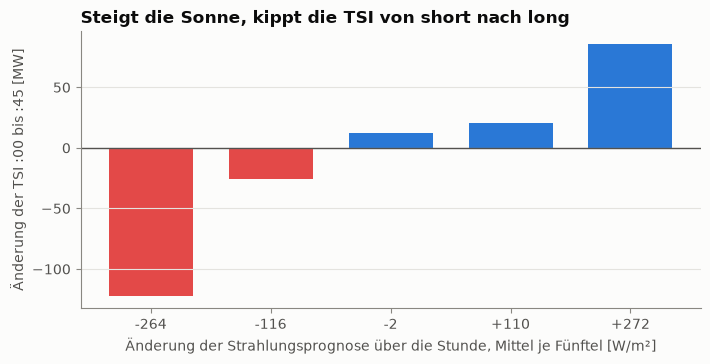

In [36]:
#--------------------------------------------------------------
# Kippen der TSI je Fünftel der Steigung der Strahlungsprognose
#--------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 3.6))
colours = [BLUE if v > 0 else RED for v in by_slope["trend_mean"]]
ax.bar(range(len(by_slope)), by_slope["trend_mean"], color=colours, width=0.7)
ax.axhline(0, color=INK_2, linewidth=1)
labels = [f"{v:+.0f}" for v in by_slope["rad_slope"]]
ax.set_xticks(range(len(by_slope)), labels)
ax.set(xlabel="Änderung der Strahlungsprognose über die Stunde, Mittel je Fünftel [W/m²]",
       ylabel="Änderung der TSI :00 bis :45 [MW]", title="Steigt die Sonne, kippt die TSI von short nach long")
ax.grid(axis="x", visible=False)
save(fig, "eda_within_hour_radiation.png")
plt.show()

Verschieben sich die Kipp-Stunden mit Sonnenauf- und -untergang über die Monate?

In [37]:
#----------------------------------------------------------------
# Kippen der TSI je Monat und Stunde um Sonnenauf- und -untergang
#----------------------------------------------------------------
month_hour = trend.assign(month=pd.to_datetime(trend["date"]).dt.month).pivot_table(index="month", columns="hour", values="trend", aggfunc="mean")
month_hour[[5, 6, 7, 8, 9, 16, 17, 18, 19, 20, 21]].round(0)

hour,5,6,7,8,9,16,17,18,19,20,21
month,,,,,,,,,,,
1,-135.0,-181.0,-167.0,-31.0,18.0,-84.0,-113.0,28.0,94.0,142.0,136.0
2,-97.0,-143.0,-90.0,46.0,60.0,-128.0,-146.0,14.0,101.0,110.0,119.0
3,-84.0,-103.0,21.0,127.0,149.0,-120.0,-141.0,-99.0,70.0,90.0,93.0
4,-61.0,-64.0,24.0,121.0,112.0,-138.0,-185.0,-145.0,-75.0,37.0,96.0
5,-52.0,-3.0,17.0,101.0,69.0,-80.0,-135.0,-137.0,-64.0,9.0,75.0
6,-40.0,-57.0,6.0,48.0,51.0,-140.0,-106.0,-106.0,-49.0,5.0,37.0
7,-44.0,-17.0,-12.0,89.0,91.0,-105.0,-140.0,-123.0,-90.0,-16.0,50.0
8,-56.0,-61.0,-2.0,19.0,27.0,-104.0,-160.0,-103.0,-10.0,18.0,83.0


Und folgt der Preis dem Kippen? Median-Preis um :00 und :45, getrennt nach Stunden, in denen die TSI im Mittel von short nach long kippt und umgekehrt.

In [38]:
#------------------------------------------------------
# Median-Preis um :00 und :45 nach Richtung des Kippens
#------------------------------------------------------
rising = by_hour.index[by_hour["trend"] > 0]  # short at :00, long at :45
prices_hour = h1[h1["minute"].isin([0, 45])].assign(kind=lambda d: np.where(d["hour"].isin(rising), "short nach long", "long nach short"))
prices_hour.pivot_table(index="kind", columns="minute", values="aep_ct_kwh", aggfunc="median").round(1)

minute,0,45
kind,,
long nach short,8.8,16.5
short nach long,16.9,8.0


#### **Erkenntnisse**

Die erste Viertelstunde ist öfter short, weil die TSI in jeder Stunde kippt, und zwar in den meisten Stunden von short nach long. Die Hypothese ist mit den Daten vereinbar. Der Mechanismus selbst ist nicht direkt gemessen, weil Fahrpläne und Verbrauch nicht in unseren Daten sind.

**Das Kippen ist gross und regelmässig**
- **17 Uhr:** TSI um :00 im Mittel +59 MW (zu 30 % short), um :45 −82 MW (zu 79 % short)
- **12 Uhr:** umgekehrt, −108 MW um :00 und +23 MW um :45
- Die vier Viertelstunden liegen meist fast auf einer Geraden, wie bei einer Stufe im Fahrplan gegen eine gleitende Änderung zu erwarten

**Die Richtung wechselt mit der Tageszeit, genau wie die Residuallast**
- **Von long nach short** (Residuallast steigt)
    - 04 bis 07 Uhr, Morgenrampe vor und um Sonnenaufgang
    - 14 bis 18 Uhr, PV nimmt ab
- **Von short nach long** (Residuallast fällt)
    - 08 bis 13 Uhr, PV nimmt zu
    - 20 bis 03 Uhr, Verbrauch sinkt am Abend und in der Nacht

**Warum im Mittel :00 öfter short ist**
- 15 der 24 Stunden kippen von short nach long
- Der Mittelwert aus H1 (58 % gegenüber 50 %) mischt zwei entgegengesetzte Muster und unterschätzt den Effekt stark
- Je nach Stunde liegt der Anteil short um :00 zwischen 30 % und 80 %

**Die Sonne steuert es mit**
- Die Änderung der Strahlungsprognose über die Stunde hängt mit dem Kippen zusammen, Rangkorrelation **0.47** über 3'880 Stunden
- **Strahlung steigt stark** (+272 W/m²): TSI kippt im Mittel um **+86 MW** nach long
- **Strahlung fällt stark** (−264 W/m²): TSI kippt um **−122 MW** nach short

**Die Kipp-Stunden wandern mit Sonnenauf- und -untergang**
- **07 Uhr:** im Januar nach short (−167 MW, Morgenrampe im Dunkeln), ab März nach long (PV steigt schon)
- **19 Uhr:** im Januar nach long (+94 MW), von April bis Juli nach short (PV geht zurück)

**Ausgleich vor allem mit manueller Regelenergie**
- Netto-Abrufe von mFRR um :00 mit +18 MW am höchsten
- um :45 mit +3 MW am tiefsten

**Der Preis folgt dem Kippen**
- **Stunden von short nach long:** Median-Preis um :00 **16.9**, um :45 **8.0** ct/kWh
- **Stunden von long nach short:** umgekehrt, 8.8 und 16.5 ct/kWh

**Folge für das Modell**
- Die Kombination **Viertelstunde in der Stunde × Uhrzeit** und die **Steigung der Strahlungsprognose** sind starke, um 11:00 bekannte Merkmale
- Für die Stunden ohne Sonne (Abend, Nacht, Morgen) würde die Steigung der Lastprognose dasselbe leisten
- Dafür bräuchte es die ENTSO-E-Lastprognose

---
## **1.3) Wetter, vergangene Preise und Stabilität (H9 bis H12)**

Die zweite Runde prüft, ob das Wetter als Unsicherheitssignal taugt, ob vergangene Preise etwas über den Liefertag sagen und ob die Zusammenhänge über die Monate stabil sind.

| # | Frage |
|---|---|
| H9 | Wird die Systembilanz bei unsicherem Wetter unruhiger, und streut der Preis dann breiter? |
| H10 | Helfen weitere Wettervariablen zusätzlich zur Strahlung? |
| H11 | Sagen die Preise bis D−2 etwas über den Preis am Liefertag? |
| H12 | Bleiben die gefundenen Zusammenhänge über die Monate gleich? |

**Zeitraum:**
- nur Viertelstunden mit finalem Preis, **01.01.2026** bis **31.08.2026**
- Damit hängen die Ergebnisse nicht davon ab, welcher Snapshot der Regelzonenbilanz gerade der neueste ist

**Leak-Regeln wie in der ersten Runde:**
- **Wetter:** nur aus dem Lauf D−2 18 UTC, über `weather_to_quarter_hours` bzw. `site_spread`
- **Vergangene Preise:** nur über `known_at_issue()`
- **Dieselbe Viertelstunde:** Zusammenhänge mit TSI oder Preis sind beschreibend, keine Merkmale

In [39]:
#----------------------------------------------------------------------------------
# Hilfsfunktionen der zweiten Runde
# width ersetzt die gleichnamige Breite des Tagesprofils aus H7 durch eine Funktion
#----------------------------------------------------------------------------------
def spearman(frame: pd.DataFrame, a: str, b: str) -> float:
    # DataFrame.corr computes Spearman without scipy (Series.corr would need it)
    return frame[[a, b]].corr(method="spearman").iloc[0, 1]


def width(s: pd.Series) -> float:
    return s.quantile(0.9) - s.quantile(0.1)


#------------------------------------------------------------------------------------------------
# Tabelle je Viertelstunde mit Preis, TSI und allen Wettervariablen, nur Viertelstunden mit Preis
# Preis, Regelzonenbilanz, Wetter und Standorte sind oben bereits geladen
#------------------------------------------------------------------------------------------------
weights = sites.set_index("site")["pv_share"]

WEATHER = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance", "sunshine_duration",
           "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high", "temperature_2m",
           "relative_humidity_2m", "precipitation", "snowfall", "wind_speed_10m", "wind_speed_100m"]
mean_weather = eda.weather_to_quarter_hours(weather, weights, WEATHER)
spread = eda.site_spread(weather, ["shortwave_radiation"]).add_suffix("_spread")

qh = cab[["timestamp_utc", "timestamp_local", "tsi_mw"]].merge(prices[["timestamp_utc", "aep_ct_kwh"]], on="timestamp_utc")
qh = qh.merge(mean_weather, left_on="timestamp_utc", right_index=True, how="left")
qh = qh.merge(spread, left_on="timestamp_utc", right_index=True, how="left")
local = qh["timestamp_local"]
qh = qh.assign(hour=local.dt.hour, month=local.dt.month, date=local.dt.date, slot=eda.clock_slot(local),
               short=qh["tsi_mw"] < 0, abs_tsi=qh["tsi_mw"].abs())
print(qh.shape, qh["date"].min(), "..", qh["date"].max())
print("missing radiation on:", sorted(set(qh.loc[qh["shortwave_radiation"].isna(), "date"])))

(23324, 26) 2026-01-01 .. 2026-08-31
missing radiation on: [datetime.date(2026, 6, 24)]


23'324 Viertelstunden, wie in der ersten Runde. Die Strahlung fehlt nur am **24.06.2026** (Archivlücke).

### **1.3.1) H9 Wetter als Unsicherheitssignal**

**Frage:** Wird die Systembilanz bei unsicherem Wetter unruhiger, und streut der Preis dann breiter?

**Erwartung:** Ja, weil die Solarproduktion bei wechselhaftem Wetter schwerer vorherzusagen ist.

Die *Abweichung* der Sonne von der Prognose ist um 11:00 unbekannt. Ob die Lage unsicher ist, lässt sich aber aus der Prognose selbst schätzen.

**Masse für die Unsicherheit** (alle aus dem Lauf D−2 18 UTC):
1. **Bewölkung** (PV-gewichtet)
    - klar, unter 20 %
    - wechselnd, 20 bis 80 %
    - bedeckt, über 80 %
2. **Streuung zwischen den Standorten**
    - Standardabweichung der Strahlungsprognose über die sechs Standorte
    - geteilt durch die mittlere Strahlung, sonst misst sie nur, wie hell es ist
3. **Sprünge über den Tag:** mittlere Änderung der Strahlungsprognose von Stunde zu Stunde

**Abgrenzung:**
- nur Tageslicht, Strahlung über 50 W/m²
- getrennt nach Tageszeit, damit nicht die Uhrzeit den Effekt erzeugt
- **Breite:** P90 minus P10 des Preises

In [40]:
#---------------------------------------------------------------------
# Bewölkungsklassen bei Tageslicht, |TSI| und Preisband nach Tageszeit
#---------------------------------------------------------------------
day = qh[qh["shortwave_radiation"] > 50].copy()
day["cloud"] = pd.cut(day["cloud_cover"], [-1, 20, 80, 101], labels=["klar", "wechselnd", "bedeckt"])
day["daytime"] = pd.cut(day["hour"], [0, 10, 14, 24], labels=["bis 10 Uhr", "10 bis 14 Uhr", "ab 14 Uhr"], right=False)
by_cloud = day.groupby(["daytime", "cloud"], observed=True).agg(
    quarter_hours=("abs_tsi", "size"), abs_tsi_median=("abs_tsi", "median"),
    price_width=("aep_ct_kwh", width), negative=("aep_ct_kwh", lambda s: (s < 0).mean()))
by_cloud.round(2)

quarter_hours  abs_tsi_median  price_width  negative
daytime       cloud                                                          
bis 10 Uhr    klar                 872           50.55        27.19      0.12
              wechselnd           1096           67.59        27.51      0.11
              bedeckt              568           79.08        26.26      0.11
10 bis 14 Uhr klar                1040           62.09        32.00      0.27
              wechselnd           1672           93.49        36.36      0.23
              bedeckt             1156          105.86        35.08      0.16
ab 14 Uhr     klar                1312           57.01        33.18      0.20
              wechselnd           2424           82.20        35.68      0.19
              bedeckt             1160           80.70        26.44      0.10

Hängt das nur an der Saison (bedeckte Tage eher im Winter)? Gleicher Vergleich **pro Monat**:

In [41]:
#----------------------------
# Gleicher Vergleich je Monat
#----------------------------
cloud_month = day.pivot_table(index="month", columns="cloud", values="abs_tsi", aggfunc="median", observed=True)
width_month = day.pivot_table(index="month", columns="cloud", values="aep_ct_kwh", aggfunc=width, observed=True)
print("median |TSI| [MW]\n", cloud_month.round(0).to_string())
print("\nprice width P90-P10 [ct/kWh]\n", width_month.round(1).to_string())

median |TSI| [MW]


 cloud  klar  wechselnd  bedeckt
month                          
1      94.0      109.0     79.0
2      82.0       88.0     83.0
3      62.0       80.0     90.0
4      76.0       98.0     90.0
5      53.0       84.0     84.0
6      45.0       70.0     97.0
7      53.0       83.0    117.0
8      48.0       77.0     99.0

price width P90-P10 [ct/kWh]
 cloud  klar  wechselnd  bedeckt
month                          
1      19.7       20.1     21.7
2      23.8       19.9     17.7
3      23.1       28.8     32.5
4      30.0       64.2     34.1
5      35.2       33.6     33.9
6      29.5       37.0     37.0
7      33.9       34.3     36.0
8      31.9       35.9     44.3


In [42]:
#---------------------------------------------------------------------------------------
# Relative Streuung der Strahlungsprognose zwischen den Standorten, Drittel je Tageszeit
#---------------------------------------------------------------------------------------
day["rel_spread"] = day["shortwave_radiation_spread"] / day["shortwave_radiation"]
day["spread_class"] = day.groupby("daytime", observed=True)["rel_spread"].transform(
    lambda s: pd.qcut(s, 3, labels=["tief", "mittel", "hoch"]))
day.groupby(["daytime", "spread_class"], observed=True).agg(
    abs_tsi_median=("abs_tsi", "median"), price_width=("aep_ct_kwh", width)).round(2)

abs_tsi_median  price_width
daytime       spread_class                             
bis 10 Uhr    tief                   52.66        30.94
              mittel                 54.50        23.88
              hoch                   80.42        25.77
10 bis 14 Uhr tief                   62.50        32.69
              mittel                 97.47        35.60
              hoch                  107.11        33.30
ab 14 Uhr     tief                   64.30        38.07
              mittel                 75.00        30.16
              hoch                   84.93        29.04

In [43]:
#-----------------------------------------------------------------------------
# Sprünge der Strahlungsprognose über den Tag gegen |TSI| und Preisband je Tag
#-----------------------------------------------------------------------------
jumps = eda.daily_mean_abs_change(mean_weather["shortwave_radiation"]).rename("jumps")
daily = day.groupby("date").agg(abs_tsi=("abs_tsi", "mean"), price_width=("aep_ct_kwh", width),
                                radiation=("shortwave_radiation", "mean"), month=("month", "first")).join(jumps)
daily["rel_jumps"] = daily["jumps"] / daily["radiation"]
print(f"{len(daily)} days")
for target in ["abs_tsi", "price_width"]:
    within = daily.groupby("month").apply(lambda g: spearman(g, "rel_jumps", target), include_groups=False)
    print(f"rel_jumps ~ {target:11s}: all days {spearman(daily, 'rel_jumps', target):+.2f}, "
          f"within months median {within.median():+.2f} (range {within.min():+.2f} .. {within.max():+.2f})")
print(f"radiation ~ price_width: {spearman(daily, 'radiation', 'price_width'):+.2f}")

242 days
rel_jumps ~ abs_tsi    : all days +0.08, within months median +0.22 (range -0.18 .. +0.47)
rel_jumps ~ price_width: all days +0.32, within months median -0.16 (range -0.24 .. +0.38)
radiation ~ price_width: +0.47


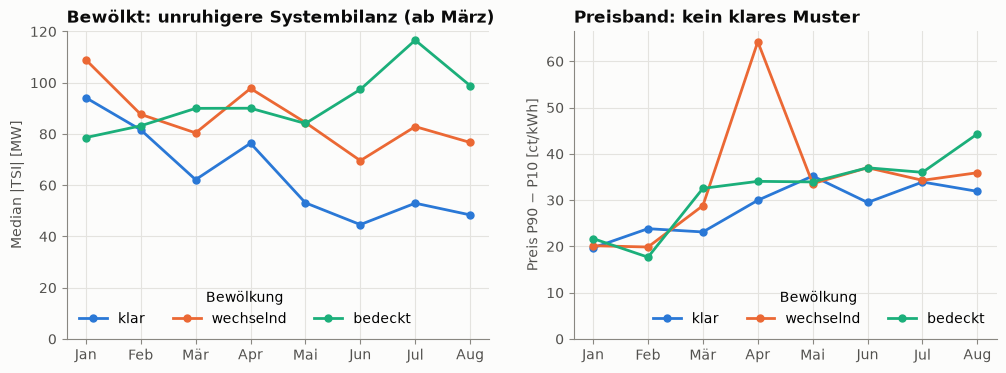

In [44]:
#--------------------------------------------
# |TSI| und Preisband je Monat nach Bewölkung
#--------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
classes = ["klar", "wechselnd", "bedeckt"]
for colour, cls in zip(CATEGORICAL, classes):
    axes[0].plot(range(len(cloud_month)), cloud_month[cls], color=colour, marker="o", markersize=5, label=cls)
    axes[1].plot(range(len(width_month)), width_month[cls], color=colour, marker="o", markersize=5, label=cls)
for ax, where in zip(axes, ["lower left", "lower right"]):
    ax.set_xticks(range(len(cloud_month)), [MONTHS[m - 1] for m in cloud_month.index])
    ax.legend(loc=where, title="Bewölkung", ncols=3)
axes[0].set(ylabel="Median |TSI| [MW]", ylim=(0, None), title="Bewölkt: unruhigere Systembilanz (ab März)")
axes[1].set(ylabel="Preis P90 − P10 [ct/kWh]", ylim=(0, None), title="Preisband: kein klares Muster")
save(fig, "eda2_weather_uncertainty.png")
plt.show()

#### **Erkenntnisse**

Wechselhaftes Wetter macht die Systembilanz unruhiger, das Preisband aber nicht breiter. Die Hypothese ist teilweise bestätigt.

**Bewölkt: unruhigere Systembilanz**
- **10 bis 14 Uhr,** Median |TSI|
    - klar **62 MW**
    - wechselnd 93 MW
    - bedeckt **106 MW**
- **März bis August:** |TSI| bei klarem Himmel in **jedem** Monat am kleinsten, im Juli zum Beispiel 53 gegenüber 83 und 117 MW
- **Januar und Februar:** gilt nicht, dort spielt die PV kaum eine Rolle
- **Anders als erwartet:** nicht „wechselnd“ ist am unruhigsten, sondern im Sommer „bedeckt“. Eine Erklärung ist nicht geprüft

**Streuung zwischen den Standorten: unruhigere Systembilanz**
- Im obersten Drittel ist |TSI| zu jeder Tageszeit grösser als im untersten
    - bis 10 Uhr 53 gegenüber 80 MW
    - 10 bis 14 Uhr 63 gegenüber 107 MW
    - ab 14 Uhr 64 gegenüber 85 MW

**Sprünge über den Tag: schwach**
- Innerhalb der Monate liegt die Rangkorrelation mit |TSI| im Median bei +0.22
- Sie schwankt zwischen −0.18 und +0.47

**Preisband: keine durchgehende Ordnung nach Bewölkung**
- Die Monatswerte liegen meist nahe beieinander, mit einem einzelnen Ausreisser im April (wechselnd, 64 ct/kWh)
- Die Breite folgt vor allem der Saison
    - über alle Tage Zusammenhang mit der Tagesstrahlung (+0.47)
    - innerhalb der Monate kein Zusammenhang mit den Sprüngen (Median −0.16)

**Folge**
- Bewölkung und Standort-Streuung sind Kandidaten für die **Grösse** der Abweichung, etwa in einem Modell, das Richtung und Preis getrennt behandelt
- Als direkte Merkmale für die Breite des Preisbands sind sie schwach
- Ob sie im Modell helfen, entscheidet der Backtest

### **1.3.2) H10 Weitere Wettervariablen**

**Frage:** Helfen weitere Wettervariablen wie Temperatur, Wind, Niederschlag, Feuchte oder Bewölkung nach Höhe zusätzlich zur Strahlung?

**Erwartung:** Ja, sie hängen mit Preis oder |TSI| zusammen, auch bei gleicher Uhrzeit und gleicher Strahlung.

**Schichtung:**
- Über alle Viertelstunden gemessen würde jede Variable vor allem Tageszeit und Saison spiegeln
- Darum die Rangkorrelation **innerhalb von Schichten**, je Stunde und Drittel der Strahlung (Tageslicht)
- Danach der Median über die Schichten

In [45]:
#--------------------------------------------------------------------------------
# Rangkorrelation weiterer Wettervariablen innerhalb Stunde und Strahlungsdrittel
#--------------------------------------------------------------------------------
day["radiation_third"] = day.groupby("hour")["shortwave_radiation"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 3, labels=False))
candidates = ["cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high", "temperature_2m",
              "relative_humidity_2m", "precipitation", "snowfall", "wind_speed_10m", "wind_speed_100m"]
rows = []
for var in candidates:
    strata = [g for _, g in day.groupby(["hour", "radiation_third"]) if len(g) > 50 and g[var].nunique() > 2]
    rows.append({"variable": var, "strata": len(strata),
                 "price": np.nanmedian([spearman(g, var, "aep_ct_kwh") for g in strata]),
                 "abs_tsi": np.nanmedian([spearman(g, var, "abs_tsi") for g in strata])})
within_strata = pd.DataFrame(rows).set_index("variable")
within_strata.round(3)

,strata,price,abs_tsi
variable,,,
cloud_cover,45,0.009,0.072
cloud_cover_low,45,0.022,0.058
cloud_cover_mid,45,0.002,0.069
cloud_cover_high,45,-0.024,0.059
temperature_2m,45,0.017,-0.005
relative_humidity_2m,45,0.013,0.064
precipitation,42,0.006,0.087
snowfall,19,0.072,-0.040
wind_speed_10m,45,-0.018,0.033


Zum Vergleich die Strahlung selbst innerhalb derselben Stunden (ohne Schichtung nach Strahlung), und die Nacht, in der die Strahlung keine Rolle spielt:

In [46]:
#--------------------------------------------------------------------
# Vergleich mit der Strahlung innerhalb der Stunden und mit der Nacht
#--------------------------------------------------------------------
by_hour = [g for _, g in day.groupby("hour") if len(g) > 50]
print(f"radiation ~ price within hours (daylight): median {np.nanmedian([spearman(g, 'shortwave_radiation', 'aep_ct_kwh') for g in by_hour]):+.2f}")
night = qh[qh["shortwave_radiation"] <= 50]
for var in ["temperature_2m", "wind_speed_100m", "relative_humidity_2m"]:
    r = [spearman(g, var, "aep_ct_kwh") for _, g in night.groupby("hour")]
    print(f"night, {var:20s} ~ price within hours: median {np.nanmedian(r):+.2f}")

radiation ~ price within hours (daylight): median -0.16
night, temperature_2m       ~ price within hours: median +0.05
night, wind_speed_100m      ~ price within hours: median -0.04
night, relative_humidity_2m ~ price within hours: median -0.03


In [47]:
#-------------------------------------------------------
# Paare von Wettervariablen mit Rangkorrelation über 0.9
#-------------------------------------------------------
corr = qh[WEATHER].corr(method="spearman").abs()
redundant = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(WEATHER) for b in WEATHER[i + 1:] if corr.loc[a, b] > 0.9]
pd.DataFrame(redundant, columns=["variable", "variable_2", "abs_spearman"])

,variable,variable_2,abs_spearman
0,shortwave_radiation,direct_radiation,0.99
1,shortwave_radiation,diffuse_radiation,0.95
2,shortwave_radiation,direct_normal_irradiance,0.96
3,shortwave_radiation,sunshine_duration,0.92
4,direct_radiation,diffuse_radiation,0.92
5,direct_radiation,direct_normal_irradiance,0.99
6,direct_radiation,sunshine_duration,0.95
7,direct_normal_irradiance,sunshine_duration,0.96


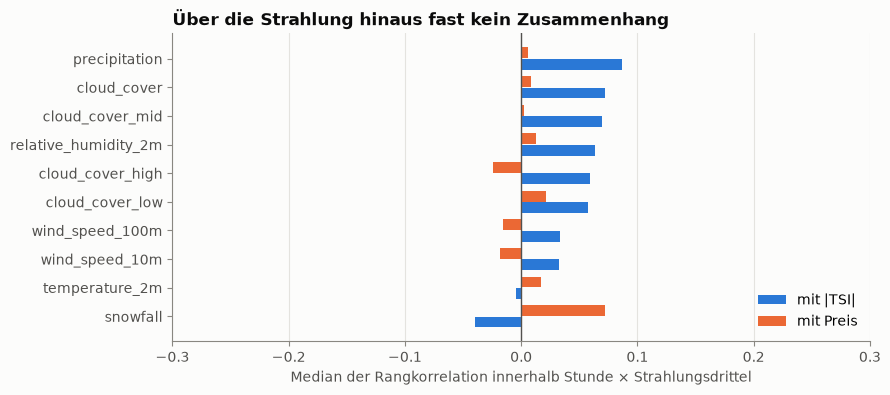

In [48]:
#----------------------------------------------
# Mediane der Rangkorrelation je Wettervariable
#----------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
order = within_strata.sort_values("abs_tsi").index
y = np.arange(len(order))
ax.barh(y - 0.2, within_strata.loc[order, "abs_tsi"], height=0.38, color=BLUE, label="mit |TSI|")
ax.barh(y + 0.2, within_strata.loc[order, "price"], height=0.38, color=CATEGORICAL[1], label="mit Preis")
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, order)
ax.set(xlim=(-0.3, 0.3), xlabel="Median der Rangkorrelation innerhalb Stunde × Strahlungsdrittel",
       title="Über die Strahlung hinaus fast kein Zusammenhang")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "eda2_weather_variables.png")
plt.show()

#### **Erkenntnisse**

Weitere Wettervariablen tragen über die Strahlung hinaus nichts bei. Die Hypothese ist widerlegt.

**Innerhalb der Schichten nahe null**
- **Mit |TSI|:** alle Mediane zwischen −0.04 und +0.09
- **Mit dem Preis:** zwischen −0.02 und +0.07
- **Zum Vergleich:** die Strahlung selbst innerhalb derselben Stunden −0.16 mit dem Preis

**Auch in der Nacht nahe null**
- Temperatur +0.05
- Wind 100 m −0.04
- Feuchte −0.03

**Strahlungsvariablen redundant**
- Global-, Direkt- und Diffusstrahlung, Direktnormalstrahlung und Sonnenscheindauer hängen paarweise mit 0.92 bis 0.99 zusammen

**Empfehlung Wettervariablen**
- **Ins Modell:**
    - `shortwave_radiation`, Niveau und Steigung über die Stunde (H3 und H8)
    - `cloud_cover` oder die Standort-Streuung (H9)
- **Vorerst weglassen:** die übrigen vier Strahlungsvariablen, Temperatur, Wind, Feuchte, Niederschlag und Schneefall
- **Vorbehalt:**
    - Die Temperatur könnte im Herbst und Winter (Heizlast) wichtiger werden
    - Januar bis März zeigen das nicht, Herbstmonate fehlen in den Daten

### **1.3.3) H11 Preisniveau bis D−2**

**Frage:** Sagen die Preise bis D−2 etwas über den Preis am Liefertag?

**Erwartung:** Ja, der Preis derselben Viertelstunde einige Tage zuvor und Quantile der letzten Wochen geben einen Anhaltspunkt.

**Zulässigkeit:**
- Ein Abstand ab 2 Tagen ist für jede Zielviertelstunde erlaubt (Ende D−2)
- **Vorbehalt:** Die Preise sind final, um 11:00 gab es nur provisorische Werte. Wie gross der Unterschied ist, misst ein eigenes Issue nach dem **21.10.2026**

In [49]:
#---------------------------------------------------------------------------
# Rangkorrelation mit dem Preis derselben Viertelstunde 2 bis 28 Tage vorher
#---------------------------------------------------------------------------
price_frame = prices[["timestamp_local", "aep_ct_kwh"]]
pairs = eda.same_slot_pairs(price_frame, [2, 3, 7, 14, 28])
by_lag = pairs.groupby("lag_days").apply(lambda g: spearman(g, "value", "earlier"), include_groups=False).rename("spearman")
pairs["daytime"] = pd.cut(pairs["slot"] // 4, [0, 6, 10, 16, 20, 24], right=False,
                          labels=["0 bis 6", "6 bis 10", "10 bis 16", "16 bis 20", "20 bis 24"])
lag2 = pairs[pairs["lag_days"] == 2].groupby("daytime", observed=True).apply(
    lambda g: spearman(g, "value", "earlier"), include_groups=False)
daily_median = price_frame.groupby(price_frame["timestamp_local"].dt.date)["aep_ct_kwh"].median()
print("same quarter hour, by lag:", by_lag.round(3).to_dict())
print("lag 2 by time of day:", lag2.round(2).to_dict())
print("daily median price, autocorrelation:", {k: round(daily_median.autocorr(k), 3) for k in [2, 3, 7, 14]})

same quarter hour, by lag: {2: 0.158, 3: 0.127, 7: 0.123, 14: 0.131, 28: 0.106}
lag 2 by time of day: {'0 bis 6': 0.16, '6 bis 10': 0.1, '10 bis 16': 0.12, '16 bis 20': 0.17, '20 bis 24': 0.19}
daily median price, autocorrelation: {2: np.float64(0.217), 3: np.float64(0.111), 7: np.float64(0.002), 14: np.float64(0.102)}


Wie gut beschreiben **Quantile der Vergangenheit** den Liefertag?

**Vorgehen:**
1. Für jeden Liefertag P10, P50 und P90 je Viertelstunde des Tages aus den letzten W Tagen bis D−2 berechnen (`eda.past_slot_quantiles`)
    - „alles“ heisst alle Tage seit **01.01.2026**
2. Abdeckung des Intervalls (Ziel 80 %), mittlere Breite und MAE des Medians bestimmen
    - verglichen auf denselben Liefertagen, ab dem Tag, an dem auch das 56-Tage-Fenster voll ist

Das ist eine Vorschau auf die naive Baseline, **keine** Modellbewertung. Der Vergleich mit dem Pinball-Loss gehört ins Baseline-Issue.

In [50]:
#-----------------------------------------------------------------------------
# Quantile der Vergangenheit je Fenster, Abdeckung, Breite und MAE des Medians
#-----------------------------------------------------------------------------
days = sorted(set(price_frame["timestamp_local"].dt.date))
actual = price_frame.assign(slot=eda.clock_slot(price_frame["timestamp_local"]), date=price_frame["timestamp_local"].dt.date)
actual_by_day = {d: g.groupby("slot")["aep_ct_kwh"].mean() for d, g in actual.groupby("date")}
WINDOWS = {"7 Tage": 7, "14 Tage": 14, "28 Tage": 28, "56 Tage": 56, "alles": 400}
start = days[0] + dt.timedelta(days=1 + 56)  # first delivery day with a full 56-day window
rows = []
for name, w in WINDOWS.items():
    for d in [d for d in days if d >= start]:
        q = eda.past_slot_quantiles(price_frame, d, w).join(actual_by_day[d].rename("actual"), how="inner")
        rows.append({"window": name, "date": d,
                     "coverage": ((q["actual"] >= q[0.1]) & (q["actual"] <= q[0.9])).mean(),
                     "width": (q[0.9] - q[0.1]).mean(), "mae": (q["actual"] - q[0.5]).abs().mean()})
windows = pd.DataFrame(rows)
summary = windows.groupby("window", sort=False)[["coverage", "width", "mae"]].mean()
print(f"{windows['date'].nunique()} delivery days from {start}")
summary.round(3)

186 delivery days from 2026-02-27


,coverage,width,mae
window,,,
7 Tage,0.606,22.949,10.484
14 Tage,0.683,24.240,9.993
28 Tage,0.723,24.959,9.847
56 Tage,0.746,24.715,9.716
alles,0.728,22.322,9.730


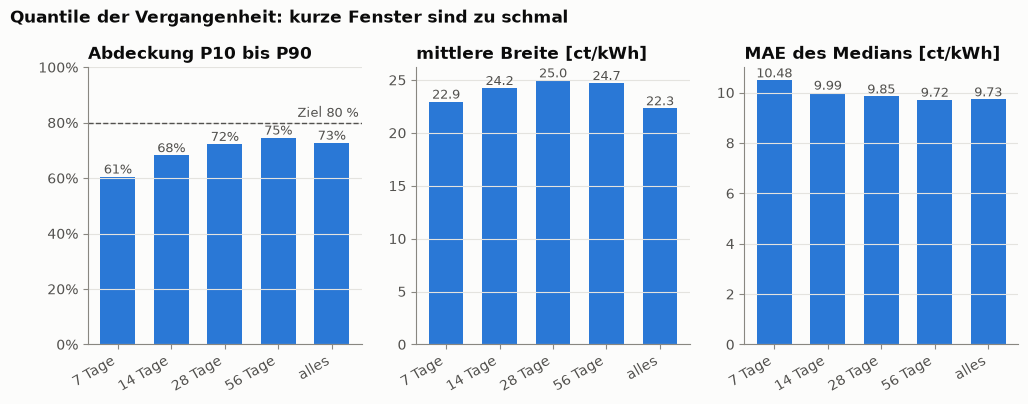

In [51]:
#-------------------------------------
# Abdeckung, Breite und MAE je Fenster
#-------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
x = range(len(summary))
for ax, col, label, fmt in [(axes[0], "coverage", "Abdeckung P10 bis P90", "{:.0%}"),
                            (axes[1], "width", "mittlere Breite [ct/kWh]", "{:.1f}"),
                            (axes[2], "mae", "MAE des Medians [ct/kWh]", "{:.2f}")]:
    bars = ax.bar(x, summary[col], color=BLUE, width=0.65)
    for rect, v in zip(bars, summary[col]):
        ax.text(rect.get_x() + rect.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", color=INK_2, fontsize=9)
    ax.set_xticks(x, summary.index, rotation=30, ha="right")
    ax.set(title=label)
    ax.grid(axis="x", visible=False)
axes[0].axhline(0.8, color=INK_2, linewidth=1, linestyle="--")
axes[0].text(len(summary) - 0.5, 0.81, "Ziel 80 %", ha="right", va="bottom", color=INK_2, fontsize=9)
axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_ylim(0, 1)
fig.suptitle("Quantile der Vergangenheit: kurze Fenster sind zu schmal", x=0.06, y=1.04, ha="left", fontweight="bold", color=INK)
save(fig, "eda2_past_windows.png")
plt.show()

#### **Erkenntnisse**

Das Preisniveau bis D−2 sagt nur schwach etwas über den Liefertag.

**Gleiche Viertelstunde einige Tage zuvor: schwach**
- **Rangkorrelation nach Abstand:**
    - 0.16 nach 2 Tagen
    - 0.13 nach 3 Tagen
    - 0.12 nach 7 Tagen
    - 0.13 nach 14 Tagen
    - 0.11 nach 28 Tagen
- **Je nach Tageszeit:** 0.10 bis 0.19
- **Tagesmedian:** Autokorrelation 0.22 nach 2 Tagen, 0.11 nach 3 und 0.00 nach 7

**Quantile der Vergangenheit sind zu schmal**
- **Abdeckung P10 bis P90** statt der angestrebten 80 %
    - 61 % bei 7 Tagen
    - 68 % bei 14 Tagen
    - 72 % bei 28 Tagen
    - **75 % bei 56 Tagen**
    - 73 % mit allen Daten seit Januar
- **MAE des Medians:** zwischen 9.7 und 10.5 ct/kWh, am tiefsten bei 56 Tagen und „alles“
- **„alles“ schmaler als 56 Tage:** 22.3 gegenüber 24.7 ct/kWh, und deckt schlechter ab, weil es die ruhigen Wintermonate einmischt (siehe H12)

**Folge für die Baseline**
- mindestens 8 Wochen Fenster
- Auch dann ist das Band zu schmal
- Ein Modell muss es mit Merkmalen (Uhrzeit, Position in der Stunde, Strahlung, Saison) besser setzen oder nachträglich kalibrieren
- Vergangene Preise allein reichen nicht

**Vorbehalt:** Alle Werte sind final. Um 11:00 gab es nur provisorische, der Unterschied wird nach dem **21.10.2026** gemessen.

### **1.3.4) H12 Stabilität über die Monate**

**Frage:** Bleiben die gefundenen Zusammenhänge über die Monate gleich?

**Erwartung:** Ja, diese Grössen ändern sich von Monat zu Monat nicht grundlegend.
- Preisverteilung
- Strahlung und Preis (H3)
- Kippen in der Stunde (H8)
- Tagesprofil (H7)

**Massstab:** Als „grundlegend“ gilt eine Änderung über dem Rauschen *innerhalb* eines Monats, gemessen als KS-Abstand zwischen der ersten und der zweiten Monatshälfte.

In [52]:
#----------------------------------------------------------------------------
# Kennzahlen je Monat, KS-Abstand zum Vormonat und zwischen den Monatshälften
#----------------------------------------------------------------------------
months = sorted(qh["month"].unique())
trend = eda.within_hour_trend(qh)
trend["month"] = pd.to_datetime(trend["date"]).dt.month
monthly = pd.DataFrame({
    "P10": qh.groupby("month")["aep_ct_kwh"].quantile(0.1),
    "P50": qh.groupby("month")["aep_ct_kwh"].median(),
    "P90": qh.groupby("month")["aep_ct_kwh"].quantile(0.9),
    "negative": qh.groupby("month")["aep_ct_kwh"].apply(lambda s: (s < 0).mean()),
    "short": qh.groupby("month")["short"].mean(),
    "rad_price_long": day[~day["short"]].groupby("month").apply(lambda g: spearman(g, "shortwave_radiation", "aep_ct_kwh"), include_groups=False),
    "rad_price_short": day[day["short"]].groupby("month").apply(lambda g: spearman(g, "shortwave_radiation", "aep_ct_kwh"), include_groups=False),
    "flip_21_to_02": trend[trend["hour"].isin([21, 22, 23, 0, 1, 2])].groupby("month")["trend"].mean(),
    "flip_15_to_17": trend[trend["hour"].isin([15, 16, 17])].groupby("month")["trend"].mean(),
})
halves = []
for m in months:
    g = qh[qh["month"] == m]
    first_half = pd.to_datetime(g["date"]).dt.day <= 15
    halves.append(eda.ks_distance(g.loc[first_half, "aep_ct_kwh"], g.loc[~first_half, "aep_ct_kwh"]))
monthly["ks_previous_month"] = [np.nan] + [eda.ks_distance(qh.loc[qh["month"] == a, "aep_ct_kwh"], qh.loc[qh["month"] == b, "aep_ct_kwh"])
                                           for a, b in zip(months[:-1], months[1:])]
monthly["ks_month_halves"] = halves
monthly.round(2)

,P10,P50,P90,negative,short,rad_price_long,rad_price_short,flip_21_to_02,flip_15_to_17,ks_previous_month,ks_month_halves
month,,,,,,,,,,,
1,3.79,16.62,24.48,0.04,0.59,-0.21,-0.18,104.41,-95.75,NaN,0.14
2,2.56,12.36,19.56,0.06,0.50,-0.27,0.05,86.32,-138.01,0.25,0.12
3,2.46,17.04,24.20,0.07,0.58,-0.46,-0.27,71.65,-128.17,0.24,0.28
4,-8.16,9.88,20.69,0.17,0.56,-0.54,-0.56,64.71,-140.74,0.27,0.12
5,-2.74,11.82,22.36,0.13,0.54,-0.60,-0.51,70.05,-100.79,0.12,0.08
6,-5.30,11.14,23.59,0.15,0.52,-0.54,-0.47,62.85,-119.79,0.09,0.18
7,-3.66,11.76,24.51,0.13,0.51,-0.64,-0.43,51.13,-116.38,0.11,0.11
8,1.38,16.92,29.24,0.09,0.57,-0.58,-0.54,44.92,-101.40,0.16,0.08


In [53]:
#------------------------------------------------------
# Rangkorrelation der Tagesprofile zwischen den Monaten
#------------------------------------------------------
profile = qh.pivot_table(index="slot", columns="month", values="aep_ct_kwh", aggfunc="median")
profile_corr = profile.corr(method="spearman")
print("daily profile, Spearman with January:", profile_corr[1].round(2).to_dict())
print("daily profile, Spearman with July:   ", profile_corr[7].round(2).to_dict())

daily profile, Spearman with January: {1: 1.0, 2: 0.79, 3: 0.51, 4: 0.45, 5: 0.3, 6: 0.39, 7: 0.29, 8: 0.43}
daily profile, Spearman with July:    {1: 0.29, 2: 0.52, 3: 0.55, 4: 0.64, 5: 0.66, 6: 0.57, 7: 1.0, 8: 0.61}


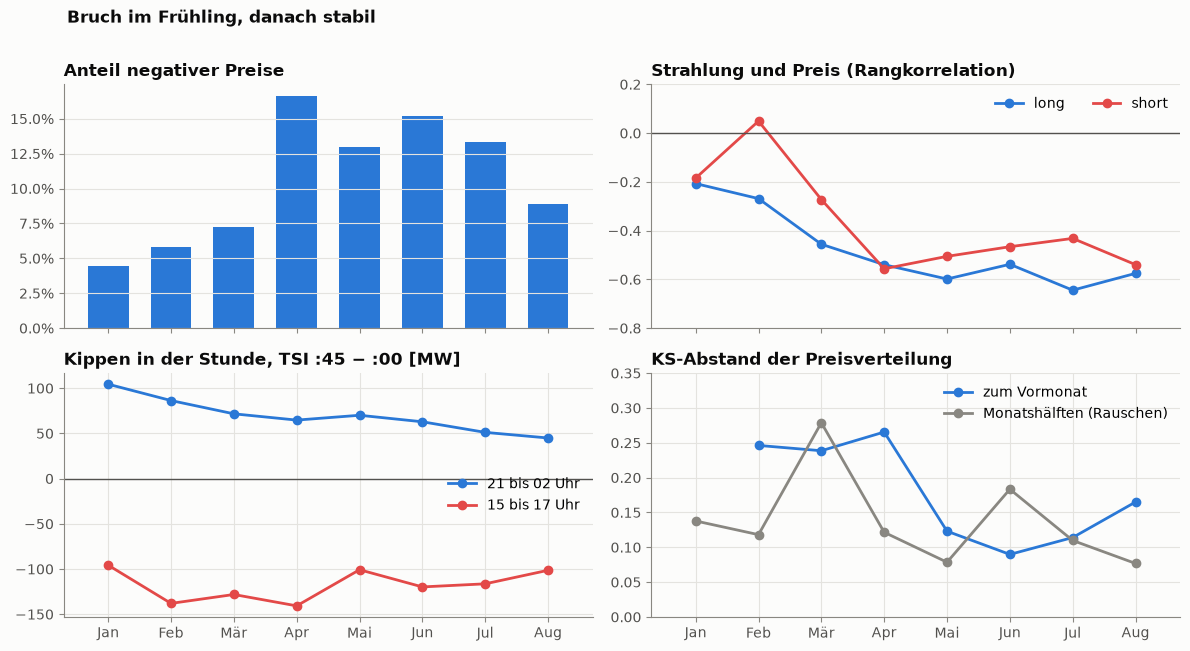

In [54]:
#------------------------------------------
# Stabilität der Kennzahlen über die Monate
#------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True)
x = range(len(monthly))
axes[0, 0].bar(x, monthly["negative"], color=BLUE, width=0.65)
axes[0, 0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0, 0].set(title="Anteil negativer Preise")
axes[0, 1].plot(x, monthly["rad_price_long"], color=BLUE, marker="o", label="long")
axes[0, 1].plot(x, monthly["rad_price_short"], color=RED, marker="o", label="short")
axes[0, 1].axhline(0, color=INK_2, linewidth=1)
axes[0, 1].set(title="Strahlung und Preis (Rangkorrelation)", ylim=(-0.8, 0.2))
axes[0, 1].legend(loc="upper right", ncols=2)
axes[1, 0].plot(x, monthly["flip_21_to_02"], color=BLUE, marker="o", label="21 bis 02 Uhr")
axes[1, 0].plot(x, monthly["flip_15_to_17"], color=RED, marker="o", label="15 bis 17 Uhr")
axes[1, 0].axhline(0, color=INK_2, linewidth=1)
axes[1, 0].set(title="Kippen in der Stunde, TSI :45 − :00 [MW]")
axes[1, 0].legend(loc="center right")
axes[1, 1].plot(x, monthly["ks_previous_month"], color=BLUE, marker="o", label="zum Vormonat")
axes[1, 1].plot(x, monthly["ks_month_halves"], color=MUTED, marker="o", label="Monatshälften (Rauschen)")
axes[1, 1].set(title="KS-Abstand der Preisverteilung", ylim=(0, 0.35))
axes[1, 1].legend(loc="upper right")
for ax in axes[1]:
    ax.set_xticks(x, [MONTHS[m - 1] for m in monthly.index])
for ax in axes[0]:
    ax.grid(axis="x", visible=False)
fig.suptitle("Bruch im Frühling, danach stabil", x=0.06, y=1.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "eda2_stability.png")
plt.show()

#### **Erkenntnisse**

Die Zusammenhänge sind nicht über alle Monate stabil. Im Frühling gibt es einen Bruch, ab April sind sie weitgehend stabil.

**Preisverteilung mit Bruch im März**
- **KS-Abstand zum Vormonat:**
    - Februar bis April 0.24 bis 0.27
    - ab Mai 0.09 bis 0.16, etwa so viel wie das Rauschen zwischen den Monatshälften (0.08 bis 0.18)
- **Rauschen im März:** 0.28, der Übergang fällt also mitten in den März
- **Negative Preise:**
    - 4 bis 7 % von Januar bis März
    - 13 bis 17 % von April bis Juli
    - 9 % im August

**Strahlung und Preis ab April stabil**
- **Bei long:** Januar −0.21, März −0.46, ab April −0.54 bis −0.64
- **Bei short:** ab April −0.43 bis −0.56

**Kippen in der Stunde (H8)**
- **Nachmittag (15 bis 17 Uhr):** stabil zwischen −96 und −141 MW
- **Abend und Nacht (21 bis 02 Uhr):** von Januar bis August immer kleiner, von +104 auf +45 MW

**Tagesprofil**
- Das Januar-Profil hängt mit den Sommermonaten nur zu 0.29 bis 0.45 zusammen
- Das Juli-Profil hängt mit April bis August zu 0.57 bis 0.66 zusammen

**Empfehlung Trainingsfenster**
1. **Baseline:** gleitende 8 Wochen
    - das beste Fenster in H11
    - es folgt dem Wechsel der Saison
2. **Modelle mit Merkmalen:** alle Daten seit Januar mit einem Saisonsignal (Strahlung, Tageslänge oder Monat)
    - damit das Modell Winter und Sommer trennen kann
    - beide Varianten im Backtest vergleichen
3. **Winterdaten behalten:**
    - Ab Oktober bewegen sich die Liefertage auf den Winter zu
    - Dann sind Januar bis März die einzigen ähnlichen Monate unter dem neuen Preissystem
    - Herbstmonate fehlen in den Daten ganz

---
## **1.4) Bewertungsdesign und Metriken**

Die EDA zeigt, wie der Preis verteilt ist und wovon er abhängt. Dieses Kapitel leitet daraus ab, was genau vorhergesagt wird, wie die Prognosen geprüft werden und mit welchen Metriken die Modelle verglichen werden. Die Begründungen stützen sich nur auf die Daten und auf Argumente, die vor den ersten Modellergebnissen feststanden. So kann die Wahl der Metrik die Rangfolge der Modelle nicht nachträglich verschieben.

### **1.4.1) Prognoseaufgabe**

Die Prognose ist eine Day-Ahead-Prognose, so wie sie eine Bilanzgruppe am Vortag braucht (Owner-Entscheid vom **01.10.2026**).

**Festlegungen:**
- **Zeitpunkt:** am Vortag D−1 um 11:00
- **Ziel:** Ausgleichsenergiepreis `aep_ct_kwh` in ct/kWh für alle 96 Viertelstunden des Liefertags D
- **Ausgabe je Viertelstunde:** drei Quantile P10, P50 und P90
    - **P50 (Median):** Punktprognose
    - **P10 bis P90:** Band, in dem der Preis mit 80 % Wahrscheinlichkeit liegen soll. Es ist das Konfidenzmass, das der Auftrag pro Vorhersage verlangt
- **Wissensstand:** nur Daten, die um 11:00 an D−1 bekannt sind (`known_at_issue()`, Leak-Regel in der Datenbasis)
- **Zeitraum:** nur Daten ab **01.01.2026**, weil seit dann das Einpreissystem gilt (`1.2.5) H5 Preise 2025 und 2026`)

### **1.4.2) Bewertungsverfahren**

Eine Prognose für die Zukunft lässt sich nur fair prüfen, wenn das Modell bei jeder Prognose nur das weiss, was es damals gewusst hätte.

**Rollierender Backtest:**
- Für jeden Liefertag wird einmal um 11:00 an D−1 prognostiziert, nur mit Daten bis D−2
- Kein zufälliger Split, weil benachbarte Tage voneinander abhängen und sonst Zukunft ins Training gelangt
- Die Metriken werden zusätzlich nach Uhrzeit, Monat und Richtung (short oder long) aufgeschlüsselt, weil sich der Preis dort stark unterscheidet (H1, H7, H8)

**Referenz (Baseline):**
- Quantile P10, P50 und P90 je Viertelstunde des Tages aus den Preisen der letzten **56 Tage** bis D−2 (`reference_forecast` aus `src/energy_price/models/shared/reference.py`)
- 56 Tage, weil dieses Fenster in `1.3.3) H11 Preisniveau bis D−2` am besten abdeckt und jeden Wochentag gleich oft enthält
- Ein Modell muss die Referenz im mittleren Pinball-Loss schlagen, sonst lohnt es sich nicht

**Perioden (Stand 14.11.2026):**
- **Heute im Code** (`PERIODS` in `src/energy_price/evaluation/backtest.py`): Training ab Januar, Auswahl der Settings auf April und Mai, Vergleich auf Juni bis August, Holdout September und Oktober gesperrt
- **Im Umbau** (#36): tägliches Walk-forward, Auswahl über mehrere Blöcke und eine einzige Testperiode am Schluss. Dieser Abschnitt wird danach nachgeführt

**Leakage aus der EDA (gelöst mit #50):**
- Das Notebook schneidet Preis, Systembilanz und Wetter direkt nach dem Laden vor dem **01.09.2026** ab, H2 und H3 nutzen nur noch Januar bis August
- **Vorbehalt:** Keine Preisbewertung auf September und Oktober, aber TSI und Wetter daraus wurden in einer früheren Fassung der EDA betrachtet (H2, H3). Die Periode heisst deshalb **Testperiode mit Vorbehalt**
- `1.5.4) Vor und nach der Umstellung auf Viertelstunden` liest weiterhin die Systembilanz ab September, ohne Preise

### **1.4.3) Warum Quantile statt einer einzelnen Zahl**

Ein einzelner Prognosewert sagt nichts darüber, wie sicher er ist. Der Auftrag verlangt aber ein Konfidenzmass pro Vorhersage. Ob eine einfache Form wie Mittelwert ± Standardabweichung reicht, hängt davon ab, wie der Preis verteilt ist.

**Daten (Januar bis August 2026):**
- `prices`: Preis `aep_ct_kwh` je Viertelstunde
- `cab`: Systembilanz `tsi_mw` je Viertelstunde, Richtung `short` (TSI unter 0) / `long`

**Vorgehen:**
1. Preis und Systembilanz derselben Viertelstunde verbinden und nach Richtung trennen
    - nur beschreibend, weil die Richtung der Zielviertelstunde um 11:00 unbekannt ist
2. Quantile, Median, Anteil negativer Preise und Minimum je Richtung vergleichen
3. Verteilung je Richtung als Histogramm zeigen

In [55]:
#-----------------------------------------------------------------------------------------
# Preis und Richtung der Systembilanz derselben Viertelstunde verbinden (nur beschreibend)
#-----------------------------------------------------------------------------------------
ev = cab[["timestamp_utc", "tsi_mw"]].merge(prices[["timestamp_utc", "timestamp_local", "aep_ct_kwh"]], on="timestamp_utc")
ev["direction"] = np.where(ev["tsi_mw"] < 0, "short", "long")
print(f"{ev['timestamp_local'].dt.date.nunique()} Liefertage und {len(ev):,} Viertelstunden".replace(",", "'"))

#-----------------------------------
# Kennzahlen des Preises je Richtung
#-----------------------------------
by_direction = ev.groupby("direction")["aep_ct_kwh"].agg(
    quarter_hours="size", P10=lambda s: s.quantile(0.1), median="median", P90=lambda s: s.quantile(0.9),
    negative=lambda s: (s < 0).mean(), minimum="min", maximum="max")
by_direction.round(3)

243 Liefertage und 23'324 Viertelstunden


,quarter_hours,P10,median,P90,negative,minimum,maximum
direction,,,,,,,
long,10572,-10.189,5.56,9.94,0.234,-688.48,27.57
short,12752,13.280,18.90,27.81,0.000,0.00,171.93


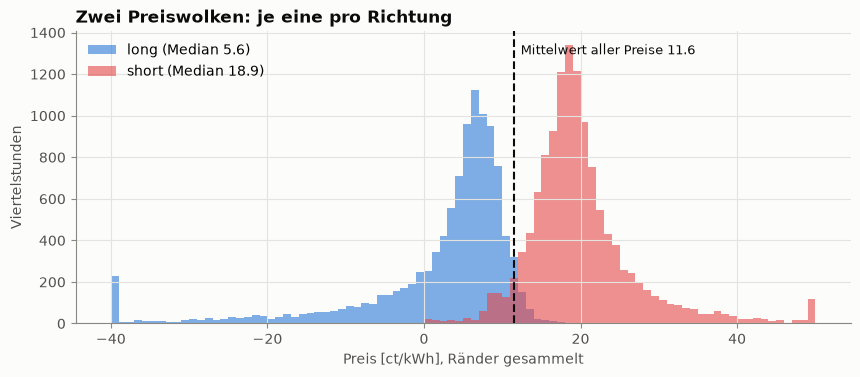

In [56]:
#--------------------------------------------------------------------
# Verteilung des Preises je Richtung, auf -40 bis +50 ct/kWh begrenzt
#--------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.linspace(-40, 50, 91)
for colour, name in [(BLUE, "long"), (RED, "short")]:
    values = ev.loc[ev["direction"] == name, "aep_ct_kwh"].clip(-40, 50)
    ax.hist(values, bins=bins, color=colour, alpha=0.6, label=f"{name} (Median {values.median():.1f})")
ax.axvline(ev["aep_ct_kwh"].mean(), color=INK, linewidth=1.5, linestyle="--")
ax.text(ev["aep_ct_kwh"].mean() + 0.8, ax.get_ylim()[1] * 0.92, f"Mittelwert aller Preise {ev['aep_ct_kwh'].mean():.1f}", color=INK, fontsize=9)
ax.set(xlabel="Preis [ct/kWh], Ränder gesammelt", ylabel="Viertelstunden", title="Zwei Preiswolken: je eine pro Richtung")
ax.legend(loc="upper left")
save(fig, "eval_price_by_direction.png")
plt.show()

#### **Erkenntnisse**

Der Preis besteht aus zwei getrennten Wolken, je eine pro Richtung. Ein symmetrisches Band um den Mittelwert läge genau dort, wo kaum Preise vorkommen.

**Zwei Wolken je Richtung** (243 Liefertage, 23'324 Viertelstunden)
- **short:** Median 18.9 ct/kWh, P10 bis P90 von 13.3 bis 27.8, nie negativ, höchstens 171.9
- **long:** Median 5.6 ct/kWh, P10 bis P90 von −10.2 bis 9.9, zu 23 % negativ, bis −688.5
- **Mittelwert aller Preise:** 11.6 ct/kWh, also zwischen den beiden Wolken

**Richtung am Vortag kaum bekannt**
- Welche Wolke gilt, hängt von der Richtung ab, und die ist um 11:00 an D−1 kaum vorhersagbar
    - in `1.2.2) H2 Stabilität der Richtung über mehrere Tage` stimmt die Richtung nach 2 Tagen nur in 54 % überein, Zufall wäre 50.5 %
- Die Prognose muss deshalb beide Möglichkeiten abdecken, und das Band wird je nach Lage asymmetrisch

Quantile brauchen keine Verteilungsannahme und dürfen je Viertelstunde unterschiedlich breit und asymmetrisch sein.

### **1.4.4) Warum P10 und P90**

Je weiter aussen ein Quantil liegt, desto weniger Preise liegen jenseits davon, und desto unsicherer lässt es sich aus wenigen Monaten schätzen. Ein breites Band wie P2.5 bis P97.5 wäre aussagekräftiger, wenn es sich verlässlich schätzen liesse.

**Daten (Januar bis August 2026):**
- `ev`: Preis je Viertelstunde aus `1.4.3) Warum Quantile statt einer einzelnen Zahl`

**Definitionen:**
- **Bootstrap über Tage:** Aus den vorhandenen Tagen werden viele Male zufällig gleich viele Tage mit Zurücklegen gezogen und jedes Mal die Quantile berechnet. Wie stark ein Quantil zwischen diesen Ziehungen schwankt, zeigt, wie genau es sich aus so vielen Tagen schätzen lässt
- **Streuung eines Quantils:** Abstand zwischen dem 5 %- und dem 95 %-Wert der 500 Bootstrap-Schätzungen, in ct/kWh

**Vorgehen:**
1. Je Monat zählen, wie viele Viertelstunden bei 80 %, 90 % und 95 % ausserhalb des Bands erwartet werden
2. Quantile von P2.5 bis P97.5 mit einem Bootstrap über ganze Tage schätzen, einmal mit allen Tagen und einmal mit 56 Tagen wie in der Referenz
    - ganze Tage statt einzelner Viertelstunden, weil benachbarte Viertelstunden stark voneinander abhängen
3. Die Streuung je Quantil vergleichen

In [57]:
#------------------------------------------------------------------------
# Erwartete Anzahl Viertelstunden ausserhalb des Bands je Monat und Seite
#------------------------------------------------------------------------
per_month = ev.groupby(ev["timestamp_local"].dt.month).size()
outside = pd.DataFrame({f"Band {int(cov * 100)} %": (per_month * (1 - cov) / 2).round(0) for cov in [0.8, 0.9, 0.95]})
outside.index.name = "Monat"
print(f"Viertelstunden je Monat: {per_month.min()} bis {per_month.max()}")
print(outside.T.to_string())

#---------------------------------------------------------------------
# Bootstrap über ganze Tage: Quantile mit allen Tagen und mit 56 Tagen
# 500 Ziehungen je Fenster, fester Zufallsstartwert
#---------------------------------------------------------------------
rng = np.random.default_rng(SEED)
LEVELS = [0.025, 0.05, 0.1, 0.5, 0.9, 0.95, 0.975]
values_by_day = [g.to_numpy() for _, g in ev.groupby(ev["timestamp_local"].dt.date)["aep_ct_kwh"]]
boot_rows = []
for label, n_days in [("alle Tage", len(values_by_day)), ("56 Tage", 56)]:
    for _ in range(500):
        picked = rng.choice(len(values_by_day), size=n_days, replace=True)
        values = np.concatenate([values_by_day[i] for i in picked])
        boot_rows.append({"Fenster": label, **{tau: np.quantile(values, tau) for tau in LEVELS}})
boot = pd.DataFrame(boot_rows)
quantile_spread = boot.groupby("Fenster")[LEVELS].agg(lambda s: s.quantile(0.95) - s.quantile(0.05)).T
quantile_spread.index = [f"P{tau * 100:g}" for tau in LEVELS]
quantile_spread["Schätzwert alle Tage"] = [ev["aep_ct_kwh"].quantile(tau) for tau in LEVELS]
quantile_spread[["Schätzwert alle Tage", "alle Tage", "56 Tage"]].round(2)

Viertelstunden je Monat: 2688 bis 2976
Monat          1      2      3      4      5      6      7      8
Band 80 %  298.0  269.0  297.0  288.0  298.0  288.0  298.0  298.0
Band 90 %  149.0  134.0  149.0  144.0  149.0  144.0  149.0  149.0
Band 95 %   74.0   67.0   74.0   72.0   74.0   72.0   74.0   74.0


Fenster,Schätzwert alle Tage,alle Tage,56 Tage
P2.5,-20.31,7.06,14.05
P5,-8.85,4.06,8.27
P10,-0.56,1.88,4.12
P50,13.13,1.69,2.86
P90,23.97,1.33,2.80
P95,28.50,2.23,4.94
P97.5,34.05,3.46,7.25


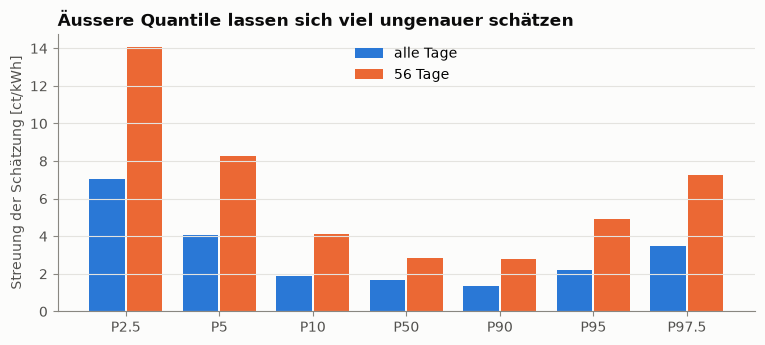

In [58]:
#--------------------------------------------
# Streuung der geschätzten Quantile je Niveau
#--------------------------------------------
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(quantile_spread))
for offset, colour, label in [(-0.2, BLUE, "alle Tage"), (0.2, CATEGORICAL[1], "56 Tage")]:
    ax.bar(x + offset, quantile_spread[label], width=0.38, color=colour, label=label)
ax.set_xticks(x, quantile_spread.index)
ax.set(ylabel="Streuung der Schätzung [ct/kWh]", title="Äussere Quantile lassen sich viel ungenauer schätzen")
ax.legend(loc="upper center")
ax.grid(axis="x", visible=False)
save(fig, "eval_quantile_stability.png")
plt.show()

#### **Erkenntnisse**

Die äusseren Quantile lassen sich mit den vorhandenen Tagen deutlich ungenauer schätzen als P10 und P90. Ein 80-%-Band ist der beste Kompromiss zwischen Aussagekraft und Verlässlichkeit.

**Wenige Preise ausserhalb breiter Bänder**
- Je Monat und Seite liegen bei 80 % rund 270 bis 300 Viertelstunden ausserhalb, bei 95 % nur noch 67 bis 74
- Je weniger Preise ausserhalb liegen, desto stärker hängt das Quantil an wenigen Extremereignissen (H4)

**Äussere Quantile ungenau geschätzt**
- **Mit allen Tagen:**
    - P10 auf 1.9 ct/kWh genau, P90 auf 1.3
    - P2.5 nur auf 7.1 ct/kWh, P97.5 auf 3.5
- **Mit 56 Tagen wie in der Referenz:**
    - P10 auf 4.1 ct/kWh genau, P90 auf 2.8
    - P2.5 nur auf 14.1 ct/kWh, P97.5 auf 7.3
- **Unterer Rand am unsichersten:** P2.5 liegt bei −20.3 ct/kWh und schwankt mit 56 Tagen um 14.1 ct/kWh, also fast so stark wie der Wert selbst

**Grenze:** Der Bootstrap zieht zufällige Tage aus allen Monaten und blendet die Saison aus. Er zeigt den Unterschied zwischen den Quantilen, nicht die genaue Unsicherheit eines bestimmten Fensters.

P10 und P90 lassen sich auch mit 56 Tagen auf wenige ct/kWh genau schätzen und lassen genug Preise ausserhalb, um die Abdeckung je Monat zu prüfen.

### **1.4.5) Warum der Pinball-Loss als Hauptmetrik**

Für Quantilprognosen braucht es eine Metrik, die belohnt, wer das richtige Quantil trifft, und weder ein zu schmales noch ein zu breites Band bevorzugt. Der Pinball-Loss ist dafür das übliche Mass.

**Pinball-Loss:**

$$L_\tau(y, q) = \max\bigl(\tau \, (y - q),\ (\tau - 1) \, (y - q)\bigr)$$

- $y$ ist der echte Preis, $q$ die Prognose für das Quantil $\tau$, beides in ct/kWh
- **Gewichtung:** Liegt der Preis über der Prognose, kostet jede ct/kWh Abstand $\tau$, liegt er darunter, kostet sie $1 - \tau$. Bei $\tau = 0.9$ ist eine zu tiefe Prognose neunmal teurer als eine zu hohe
- **Hauptmetrik:** Mittel über alle Viertelstunden und über $\tau \in \{0.1, 0.5, 0.9\}$, berechnet mit `pinball_loss` aus `src/energy_price/metrics.py`
- **Bezug zum MAE:** Bei $\tau = 0.5$ ist der Pinball-Loss genau der halbe MAE

**Daten:**
- `ev`: Preise von 12:00 bis 13:45, April bis August, wo die Preise am stärksten streuen (H7)

**Vorgehen:**
1. Für viele mögliche Prognosewerte $q$ den mittleren Pinball-Loss über diese Preise berechnen, je für $\tau$ = 0.1, 0.5 und 0.9
2. Den Wert $q$ mit dem kleinsten Loss mit dem empirischen Quantil vergleichen

In [59]:
#----------------------------------------------------------------------------------------------
# Mittlerer Pinball-Loss je Prognosewert q für die Preise von 12:00 bis 13:45, April bis August
#----------------------------------------------------------------------------------------------
local_ev = ev["timestamp_local"]
example = ev.loc[local_ev.dt.hour.between(12, 13) & local_ev.dt.month.between(4, 8), "aep_ct_kwh"].to_numpy()
grid = np.linspace(np.quantile(example, 0.02), np.quantile(example, 0.98), 401)
loss_curves = {tau: np.array([pinball_loss(example, np.full(len(example), q), tau) for q in grid]) for tau in (0.1, 0.5, 0.9)}
check = pd.DataFrame({
    "q mit kleinstem Loss": {tau: grid[curve.argmin()] for tau, curve in loss_curves.items()},
    "empirisches Quantil": {tau: np.quantile(example, tau) for tau in loss_curves},
    "kleinster Loss": {tau: curve.min() for tau, curve in loss_curves.items()},
})
print(f"{len(example):,} Viertelstunden".replace(",", "'"))
check.round(2)

1'224 Viertelstunden


,q mit kleinstem Loss,empirisches Quantil,kleinster Loss
0.1,-21.73,-21.70,6.50
0.5,9.73,9.64,7.76
0.9,21.25,21.30,2.79


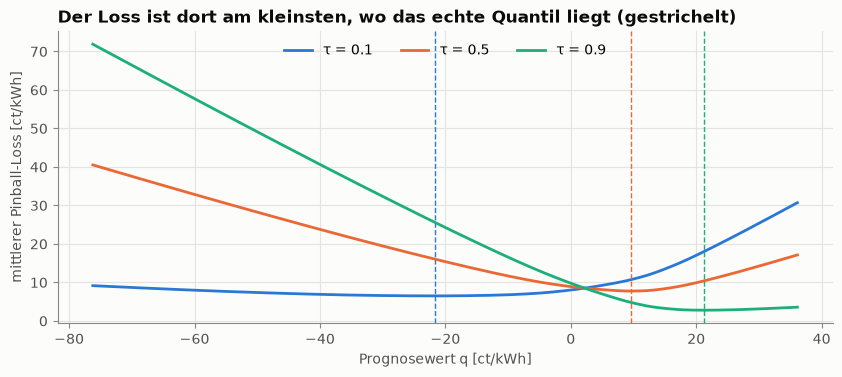

In [60]:
#----------------------------------------------------------------------
# Pinball-Loss je Prognosewert mit dem Minimum beim empirischen Quantil
#----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.8))
for colour, (tau, curve) in zip(CATEGORICAL, loss_curves.items()):
    ax.plot(grid, curve, color=colour, label=f"τ = {tau}")
    ax.axvline(np.quantile(example, tau), color=colour, linewidth=1, linestyle="--")
ax.set(xlabel="Prognosewert q [ct/kWh]", ylabel="mittlerer Pinball-Loss [ct/kWh]",
       title="Der Loss ist dort am kleinsten, wo das echte Quantil liegt (gestrichelt)")
ax.legend(loc="upper center", ncols=3)
save(fig, "eval_pinball_loss.png")
plt.show()

#### **Erkenntnisse**

Der Pinball-Loss ist genau dort am kleinsten, wo das echte Quantil liegt. Den besten Wert erreicht ein Modell also nur, wenn es die Quantile richtig trifft.

**Minimum beim echten Quantil** (1'224 Viertelstunden, 12:00 bis 13:45, April bis August)
- **τ = 0.1:** kleinster Loss bei −21.7 ct/kWh, empirisches Quantil −21.7
- **τ = 0.5:** kleinster Loss bei 9.7 ct/kWh, Median 9.6
- **τ = 0.9:** kleinster Loss bei 21.3 ct/kWh, empirisches Quantil 21.3
- Die kleinen Unterschiede kommen vom Raster der Prognosewerte

**Asymmetrische Strafe**
- Die Kurve für τ = 0.9 steigt links steil an, eine zu tiefe Prognose kostet viel
- Die Kurve für τ = 0.1 steigt rechts steil an, eine zu hohe Prognose kostet viel
- Wer das Band künstlich schmal oder breit macht, verliert deshalb auf mindestens einer Seite

**Eigenschaften, die vor den Ergebnissen feststanden**
- **Proper scoring rule:** Der erwartete Loss ist beim echten Quantil am kleinsten (Gneiting und Raftery 2007). Die Grafik zeigt das mit unseren Preisen
- **Einheit ct/kWh:** direkt mit dem MAE vergleichbar
- **Linear statt quadratisch:** Der Loss wächst linear mit dem Fehler, Extrempreise beherrschen ihn darum weniger als einen quadratischen Fehler

Ein Modell kann den Pinball-Loss nur senken, indem es die Quantile besser trifft. Er eignet sich deshalb als Hauptmetrik.

### **1.4.6) Zusatzmetriken**

Der Pinball-Loss fasst alles in einer Zahl zusammen. Für die Präsentation und die Fehlersuche braucht es zusätzlich Zahlen, die sich direkt deuten lassen.

**Zusatzmetriken:**

| Metrik | Frage | gut ist |
|---|---|---|
| MAE des Medians | Wie weit liegt die Punktprognose im Mittel daneben, in ct/kWh? | tief |
| Abdeckung P10 bis P90 | Liegen wirklich etwa 80 % der Preise im Band? | nahe 80 % |
| mittlere Breite P10 bis P90 | Wie schmal und damit nützlich ist das Band? | schmal bei Abdeckung nahe 80 % |

**Daten:**
- `ev`: alle Preise Januar bis August

**Vorgehen:**
1. Die Abweichung jedes Preises vom Median derselben Viertelstunde des Tages berechnen
    - nur beschreibend, der Median über alle Tage ist keine Prognose
2. Den Anteil des 1 % grösster Abweichungen am absoluten und am quadratischen Fehler vergleichen
    - zeigt, warum MAE statt RMSE
3. Die Abdeckung eines festen Bands P10 bis P90 aller Preise je Stunde berechnen
    - zeigt, warum die Abdeckung nur zur Diagnose dient und nach Uhrzeit geprüft werden muss

In [61]:
#----------------------------------------------------------------------------------
# Anteil des grössten 1 % der Abweichungen am absoluten und am quadratischen Fehler
# Abweichung vom Median derselben Viertelstunde des Tages, nur beschreibend
#----------------------------------------------------------------------------------
deviation = ev["aep_ct_kwh"] - ev.groupby(eda.clock_slot(ev["timestamp_local"]))["aep_ct_kwh"].transform("median")
largest = deviation.abs() >= deviation.abs().quantile(0.99)
print(f"- Anteil am absoluten Fehler (MAE):    {deviation.abs()[largest].sum() / deviation.abs().sum():.1%}")
print(f"- Anteil am quadratischen Fehler (RMSE): {(deviation[largest] ** 2).sum() / (deviation ** 2).sum():.1%}")

#----------------------------------------------------------------
# Abdeckung eines festen Bands P10 bis P90 aller Preise je Stunde
#----------------------------------------------------------------
low, high = ev["aep_ct_kwh"].quantile([0.1, 0.9])
inside = ev["aep_ct_kwh"].between(low, high)
coverage_by_hour = inside.groupby(ev["timestamp_local"].dt.hour).mean()
print(f"- Band {low:.1f} bis {high:.1f} ct/kWh, Abdeckung insgesamt {inside.mean():.1%}")
print(f"- je Stunde von {coverage_by_hour.min():.1%} ({coverage_by_hour.idxmin()} Uhr) bis {coverage_by_hour.max():.1%} ({coverage_by_hour.idxmax()} Uhr)")

- Anteil am absoluten Fehler (MAE):    10.5%
- Anteil am quadratischen Fehler (RMSE): 52.2%
- Band -0.6 bis 24.0 ct/kWh, Abdeckung insgesamt 80.0%
- je Stunde von 67.8% (12 Uhr) bis 95.7% (4 Uhr)


#### **Erkenntnisse**

Der MAE ist robust gegen einzelne Extrempreise, ein quadratischer Fehler nicht. Die Abdeckung taugt nur zur Diagnose und muss nach Uhrzeit geprüft werden.

**MAE statt RMSE**
- Das grösste 1 % der Abweichungen macht 10.5 % des absoluten Fehlers aus
- Beim quadratischen Fehler sind es 52.2 %, also mehr als die Hälfte
- Ein RMSE würde vor allem zeigen, wie ein Modell mit wenigen Extremereignissen umgeht
- **Median und MAE gehören zusammen:** Der Median ist die Punktprognose, die den MAE minimiert

**Abdeckung nur als Diagnose**
- Ein festes Band von −0.6 bis 24.0 ct/kWh deckt per Definition insgesamt 80.0 % ab
- Je Stunde liegt die Abdeckung aber zwischen 67.8 % (12 Uhr) und 95.7 % (4 Uhr)
- Das Band ist mittags zu schmal und nachts zu breit, obwohl die Gesamtzahl perfekt aussieht
- Abdeckung und Breite werden deshalb immer zusammen und je Uhrzeit, Monat und Richtung ausgewiesen, aber nie allein zur Auswahl der Modelle genutzt

Hauptmetrik ist der mittlere Pinball-Loss, ergänzt durch MAE des Medians, Abdeckung und Breite.

### **1.4.7) Verworfene Metriken**

| Metrik | Warum verworfen |
|---|---|
| MAE allein | bewertet die Unsicherheit gar nicht |
| RMSE | quadratisch, wird von wenigen Extrempreisen beherrscht (`1.4.6) Zusatzmetriken`) |
| CRPS | braucht viele Quantile oder eine Verteilungsannahme. Das Mittel des Pinball-Loss über die drei Quantile ist eine grobe, aber gut erklärbare Näherung davon |
| Winkler- bzw. Interval-Score | bewertet nur das Band, nicht den Median |
| Mittelwert ± Standardabweichung als Band | setzt eine symmetrische Verteilung voraus (`1.4.3) Warum Quantile statt einer einzelnen Zahl`) |

**Quellen:** Die Begründung mit Literatur steht in [`docs/evaluation.md`](../docs/evaluation.md).

---
## **1.5) Stundenslot-Handel und Kippen der Systembilanz**

In `1.2.8) H8 Kippen der Systembilanz innerhalb der Stunde` kippt die Systembilanz innerhalb jeder Stunde, und die Richtung folgt der Tageszeit. Dieses Kapitel prüft, ob der vermutete Mechanismus belegt ist, wie stabil das Muster ist und ob es schwächer wird, seit die Schweizer Day-Ahead-Auktion Viertelstunden handelt.

### **1.5.1) Granularität von Handel und Abrechnung in der Schweiz**

Das Kippen entsteht nur, wenn in Stunden gehandelt, aber in Viertelstunden abgerechnet wird. Ob das für die Schweiz 2026 zutrifft, zeigen die Marktregeln.

**Stand 2026:**
- **Abrechnung der Ausgleichsenergie:** je Viertelstunde, wie die 96 Preise pro Tag in unseren Daten
- **Schweizer Day-Ahead-Auktion bei EPEX SPOT:**
    - lokale Auktion, nicht Teil der europäischen Marktkopplung (SDAC)
    - bis zum Handelstag **02.11.2026** nur Stundenprodukte
    - seit dem Handelstag **03.11.2026** Viertelstunden, erster Liefertag **04.11.2026**
    - Gebotsschluss am Vortag um 11:00, also genau zum Zeitpunkt unserer Prognose
- **Grenzkapazitäten an den Schweizer Grenzen (JAO):** weiterhin Stunden, die Umstellung auf Viertelstunden ist auf 2027 verschoben
- **Nachbarländer in der Marktkopplung:** Viertelstunden im Day-Ahead seit dem Liefertag **01.10.2025**

**Folge für unsere Daten (Januar bis Oktober 2026):**
- Eine Bilanzgruppe kauft am Vortag eine Stunde mit konstanter Leistung, ihr Verbrauch steigt oder sinkt aber innerhalb der Stunde
- Bei steigendem Verbrauch ist sie in den ersten Viertelstunden long und in den letzten short, bei sinkendem umgekehrt
- Weil viele Bilanzgruppen gleich handeln, addiert sich das zum Kippen der Systembilanz, das H8 misst

**Quellen:**
- EPEX SPOT, „15-minute products in Market Coupling“, Abschnitt Switzerland ([epexspot.com](https://www.epexspot.com/en/15-minute-products-market-coupling))
- JAO, „Update of ST auctions on Swiss borders in 15 min MTU“, 30.06.2026 ([jao.eu](https://www.jao.eu/news/update-st-auctions-swiss-borders-15-min-mtu-and))
- A. Millet, „Switzerland moves to 15 minutes: what to expect?“, Oktober 2026, mit dem Beispiel einer Bilanzgruppe mit Stundenposition ([substack](https://alexandremillet.substack.com/p/switzerland-moves-to-15-minutes-what))
- Swissgrid, Allgemeine Bilanzgruppenvorschriften v3.2, Ziffer 7.2, zur Abrechnung von Fahrplanwechseln

### **1.5.2) Vergleich mit anderen Märkten**

Wenn der Mechanismus stimmt, zeigt sich das Kippen auch in anderen Ländern, und es wird schwächer, wo in Viertelstunden gehandelt wird.

| Markt | Abrechnung | Handel | Was zum Stundenwechsel belegt ist |
|---|---|---|---|
| Kontinentaleuropa | je Land | bis **09.2025** Day-Ahead in Stunden | Kraftwerke ändern ihre Einspeisung zur vollen Stunde fast stufenweise, der Verbrauch langsamer. Das erzeugt Frequenzabweichungen zur vollen Stunde, am stärksten morgens und abends (EURELECTRIC und ENTSO-E 2011) |
| Kontinentaleuropa nach der Umstellung | je Land | seit **01.10.2025** Day-Ahead in Viertelstunden | Die stündlichen Abweichungen sind deutlich kleiner, viertelstündliche Muster werden relativ wichtiger (Böttcher et al. 2026) |
| Deutschland | reBAP, ein symmetrischer Preis je Viertelstunde, also ein Einpreissystem wie bei uns seit 2026 | Viertelstunden im Intraday seit 2011, Intraday-Auktion seit 2014, Fahrpläne viertelstündlich änderbar (StromNZV § 5) | Viertelstundenhandel und strengere Pflichten der Bilanzkreise haben die deterministischen Ungleichgewichte und den Bedarf an Regelenergie deutlich gesenkt, Reste bleiben (zitiert in Böttcher et al. 2026) |
| Schweiz | ein Preis je Viertelstunde seit **01.01.2026** | Day-Ahead in Stunden bis **03.11.2026** | Kippen innerhalb jeder Stunde, in den meisten Stunden von short nach long (H8) |

**Zu den Niederlanden** wurde keine eigene Auswertung zum Stundenwechsel gefunden. Die Tabelle beschränkt sich deshalb auf Märkte mit belegten Aussagen.

**Quellen:**
- EURELECTRIC und ENTSO-E (2011): *Deterministic frequency deviations: root causes and proposals for potential solutions*
- P. C. Böttcher et al. (2026): *Impact of Market Reforms on Deterministic Frequency Deviations in the European Power Grid*, [arXiv:2602.09645](https://arxiv.org/abs/2602.09645)
- Netztransparenz.de, „Uniform imbalance price (reBAP)“ ([netztransparenz.de](https://www.netztransparenz.de/BalancingCapacity/Imbalanceprice/Uniformimbalanceprice(reBAP)))
- Stromnetzzugangsverordnung (StromNZV) § 5, Fahrplanänderungen je Viertelstunde

#### **Erkenntnisse**

Das Kippen zur vollen Stunde ist kein Schweizer Sonderfall. Es entsteht überall, wo in Stunden gehandelt und in Viertelstunden abgerechnet wird, und wird schwächer, wo der Handel auf Viertelstunden umstellt.

**Mechanismus in der Literatur belegt**
- Fahrpläne und Kraftwerke wechseln zur vollen Stunde stufenweise, der Verbrauch gleitend
- Nach der Umstellung der europäischen Marktkopplung auf Viertelstunden sind die stündlichen Abweichungen deutlich kleiner geworden

**Schweiz bis Anfang November ein Spezialfall**
- Die Nachbarländer handeln im Day-Ahead seit **01.10.2025** in Viertelstunden, die Schweiz erst seit **04.11.2026**
- Unsere Trainingsdaten von Januar bis Oktober 2026 stammen deshalb vollständig aus der Zeit mit Stundenhandel

Wenn der Mechanismus stimmt, muss das Kippen in den Schweizer Daten nach dem **04.11.2026** schwächer werden.

### **1.5.3) Stabilität des Kippens**

H8 zeigt das Kippen im Mittel über alle Tage. Für ein Merkmal zählt, ob das Muster an allen Tagtypen und in allen Monaten gleich bleibt und ob es der Uhr oder der Sonne folgt.

**Daten:**
- `cab`: Systembilanz `tsi_mw` je Viertelstunde, **01.01.2026** bis **31.08.2026**
- `holiday_share`: Anteil der PV-Leistung mit Feiertag je Tag aus `1.2) Muster von Systembilanz und Preis (H1 bis H8)`

**Definitionen:**
- **Kippen einer Stunde:** TSI der Viertelstunde :45 minus TSI der Viertelstunde :00, in MW (`within_hour_trend` aus `src/energy_price/eda.py`). Positiv heisst von short nach long
- **Profil:** mittleres Kippen je Stunde des Tages
- **Übereinstimmung zweier Profile:** Korrelation der 24 Stundenwerte und Anteil der Stunden mit gleichem Vorzeichen
- **Systematisches Kippen:** mittlerer Betrag des Profils über die 24 Stunden. Es misst nur den Teil, der sich jeden Tag zur gleichen Uhrzeit wiederholt, und blendet zufällige Schwankungen aus

**Vorgehen:**
1. Kippen je Tag und Stunde berechnen
2. Profile je Tagtyp und je Monat mit dem Gesamtprofil vergleichen
3. Je zwei Wochen vor und nach dem Beginn der Sommerzeit am **29.03.2026** vergleichen
    - einmal zur gleichen Uhrzeit, einmal um eine Stunde verschoben, weil die Sonne nach der Umstellung eine Stunde später auf der Uhr steht

In [62]:
#-------------------------------------------------------------------------
# Kippen je Tag und Stunde, Tagtyp aus dem Feiertagsanteil der PV-Leistung
#-------------------------------------------------------------------------
flips = eda.within_hour_trend(cab)
flips["day_type"] = eda.day_types(flips["date"], holiday_share).to_numpy()
flips["month"] = pd.to_datetime(flips["date"]).dt.month
overall = flips.groupby("hour")["trend"].mean()


def agreement(profile: pd.Series, reference: pd.Series) -> tuple[float, float]:
    # correlation of the 24 hourly values and share of hours with the same sign
    profile = profile.reindex(reference.index)
    return float(np.corrcoef(profile, reference)[0, 1]), float((np.sign(profile) == np.sign(reference)).mean())


#----------------------------------------------------------
# Profile je Tagtyp und je Monat gegenüber dem Gesamtprofil
#----------------------------------------------------------
rows = []
for kind, column in [("Tagtyp", "day_type"), ("Monat", "month")]:
    for key, group in flips.groupby(column):
        corr, same_sign = agreement(group.groupby("hour")["trend"].mean(), overall)
        rows.append({"Gruppe": kind, "Wert": key, "Tage": group["date"].nunique(), "Korrelation": corr,
                     "gleiches Vorzeichen": same_sign, "systematisches Kippen [MW]": group.groupby("hour")["trend"].mean().abs().mean()})
stability = pd.DataFrame(rows)

#-----------------------------------------------------------------
# Zwei Wochen vor und nach dem Beginn der Sommerzeit am 29.03.2026
#-----------------------------------------------------------------
days = pd.to_datetime(flips["date"])
before = flips[days.between("2026-03-15", "2026-03-28")].groupby("hour")["trend"].mean()
after = flips[days.between("2026-03-30", "2026-04-12")].groupby("hour")["trend"].mean()
same_clock = float(np.corrcoef(before, after)[0, 1])
same_sun = float(np.corrcoef(before.to_numpy(), after.reindex((before.index + 1) % 24).to_numpy())[0, 1])
print(f"- Sommerzeit, gleiche Uhrzeit:           Korrelation {same_clock:.2f}")
print(f"- Sommerzeit, um eine Stunde verschoben: Korrelation {same_sun:.2f}")
stability.round(2)

- Sommerzeit, gleiche Uhrzeit:           Korrelation 0.80
- Sommerzeit, um eine Stunde verschoben: Korrelation 0.90


,Gruppe,Wert,Tage,Korrelation,gleiches Vorzeichen,systematisches Kippen [MW]
0,Tagtyp,Brückentag,2,0.70,0.79,72.04
1,Tagtyp,Feiertag,5,0.87,0.83,102.31
2,Tagtyp,Samstag,35,0.91,0.88,65.54
3,Tagtyp,Sonntag,35,0.87,0.83,66.94
4,Tagtyp,Werktag,166,0.98,0.96,67.76
5,Monat,1,31,0.79,0.88,87.63
6,Monat,2,28,0.91,0.92,89.27
7,Monat,3,31,0.94,0.92,81.47
8,Monat,4,30,0.95,0.96,80.94
9,Monat,5,31,0.92,0.96,62.28


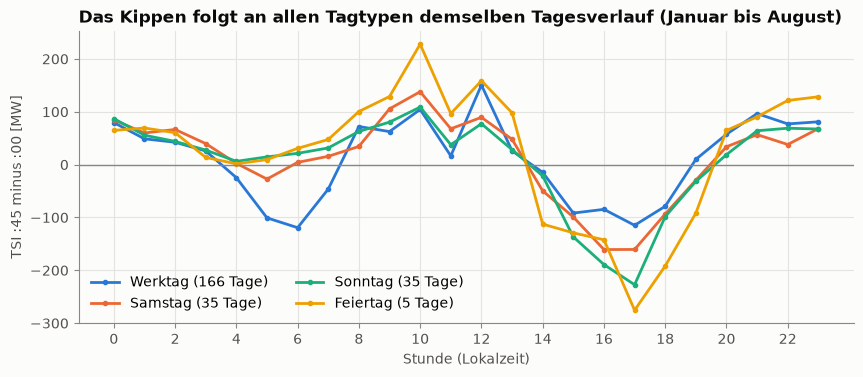

In [63]:
#---------------------------------------
# Mittleres Kippen je Stunde nach Tagtyp
#---------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.8))
for colour, kind in zip(CATEGORICAL, ["Werktag", "Samstag", "Sonntag", "Feiertag"]):
    profile = flips[flips["day_type"] == kind].groupby("hour")["trend"].mean()
    ax.plot(profile.index, profile, marker="o", markersize=3, color=colour, label=f"{kind} ({flips.loc[flips['day_type'] == kind, 'date'].nunique()} Tage)")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set(xlabel="Stunde (Lokalzeit)", ylabel="TSI :45 minus :00 [MW]", xticks=range(0, 24, 2),
       title="Das Kippen folgt an allen Tagtypen demselben Tagesverlauf (Januar bis August)")
ax.legend(loc="lower left", ncols=2)
save(fig, "sl_flip_by_day_type.png")
plt.show()

#### **Erkenntnisse**

Das Kippen ist über alle Tagtypen und Monate stabil und folgt der Sonne, nicht der Uhr. Nur am Morgen der Werktage weicht es ab.

**Gleiches Muster an allen Tagtypen**
- **Werktage, Samstage, Sonntage:** Korrelation mit dem Gesamtprofil 0.87 bis 0.98, gleiches Vorzeichen in 83 % bis 96 % der Stunden
- **Feiertage und Brückentage:** 0.87 und 0.70, mit 5 und 2 Tagen aber nicht aussagekräftig
- **Morgen nur an Werktagen nach short:** Von 4 bis 7 Uhr kippt die TSI an Werktagen von long nach short (bis −120 MW um 6 Uhr), an Samstagen, Sonntagen und Feiertagen kaum. Vermutlich steigt der Verbrauch an freien Tagen später und flacher an

**Gleiches Muster in allen Monaten, aber schwächer im Sommer**
- Korrelation mit dem Gesamtprofil von Februar bis August 0.91 bis 0.95, im Januar 0.79
- Das systematische Kippen nimmt von 88 bis 89 MW im Januar und Februar auf 48 MW im August ab

**Das Muster folgt der Sonne**
- Nach dem Beginn der Sommerzeit passt das Profil besser zum um eine Stunde verschobenen Profil davor (Korrelation 0.90) als zur gleichen Uhrzeit (0.80)
- Die Stundengrenzen kommen vom Handel, die Richtung aber von Sonne und Verbrauch
- Mit je zwei Wochen ist das ein Hinweis, kein Beweis

Für ein Merkmal heisst das: Uhrzeit allein reicht nicht, die Richtung hängt auch von Saison, Sonnenstand und Werktag ab.

### **1.5.4) Vor und nach der Umstellung auf Viertelstunden**

Seit dem Liefertag **04.11.2026** kann eine Bilanzgruppe in der Schweizer Day-Ahead-Auktion jede Viertelstunde einzeln kaufen. Wenn der Mechanismus aus `1.5.1) Granularität von Handel und Abrechnung in der Schweiz` stimmt, sollte das Kippen danach schwächer werden.

**Daten:**
- Snapshot der Regelzonenbilanz vom **15.11.2026** (`control-area-balance-2026_2026-11-15T16-31-50Z.csv`), gelesen mit `read_snapshot` aus `src/energy_price/data/control_area_balance.py`
    - fest eingetragen, damit ein neuerer Snapshot die Zahlen unten nicht verändert
    - nur für dieses Kapitel. Die übrigen Kapitel nutzen den Snapshot vom **04.10.2026**, abgeschnitten vor der Testperiode (bis **31.08.2026**)
    - **Vorbehalt:** Dieses Kapitel liest als einziges die Systembilanz der Testperiode (September und Oktober), keine Preise

**Definitionen:**
- **Vorher:** Liefertage **26.10.2026** bis **03.11.2026**, Day-Ahead in Stunden
    - erst ab **26.10.2026**, weil am **25.10.2026** die Winterzeit beginnt und sich die Uhrzeiten des Musters um eine Stunde verschieben (`1.5.3) Stabilität des Kippens`)
- **Nachher:** Liefertage **04.11.2026** bis **14.11.2026**, Day-Ahead in Viertelstunden
- **Rauschgrenze:** systematisches Kippen, das allein der Zufall mit denselben Tagen erreicht. Dafür bekommt jeder Tag 2000-mal ein zufälliges Vorzeichen, das löscht jedes gemeinsame Tagesprofil (`flip_noise_floor` aus `src/energy_price/eda.py`). Liegt ein Wert unter dem 95-%-Quantil, ist er vom Zufall nicht zu unterscheiden. Mit wenigen Tagen liegt die Grenze höher

**Vorgehen:**
1. Kippen je Tag und Stunde für beide Zeiträume berechnen
    - nur Spätherbst gegen Spätherbst, damit die Saison möglichst wenig mitspielt (`1.3.4) H12 Stabilität über die Monate`)
    - zum Vergleich auch September und Oktober bis zur Zeitumstellung
2. Systematisches Kippen mit der Rauschgrenze, mittleres |Kippen| und den Anteil starker Stunden über 100 MW vergleichen
3. Das Profil je Stunde nachher mit dem Profil vorher vergleichen

In [64]:
#---------------------------------------------------------------------------
# Snapshot vom 15.11.2026 der Regelzonenbilanz, Kippen vor und nach dem 04.11.2026
#---------------------------------------------------------------------------
# Fixed file and end date, so a newer snapshot does not change the numbers quoted below.
SWITCH_SNAPSHOT = Path("data/control_area_balance/snapshots/control-area-balance-2026_2026-11-15T16-31-50Z.csv")
SWITCH_END = "2026-11-14"
latest_cab = read_snapshot(SWITCH_SNAPSHOT)
print(f"- Snapshot {SWITCH_SNAPSHOT.name}, letzte Viertelstunde {latest_cab['timestamp_local'].max():%d.%m.%Y %H:%M}")

latest_flips = eda.within_hour_trend(latest_cab)
latest_days = pd.to_datetime(latest_flips["date"])
periods = {"September (Stunden)": latest_flips[latest_days.between("2026-09-01", "2026-09-30")],
           "Oktober bis 24.10. (Stunden)": latest_flips[latest_days.between("2026-10-01", "2026-10-24")],
           "vorher (Stunden)": latest_flips[latest_days.between("2026-10-26", "2026-11-03")],
           "nachher (Viertelstunden)": latest_flips[latest_days.between("2026-11-04", SWITCH_END)]}
switch_rows = []
for label, group in periods.items():
    assert not group.empty, f"{label}: keine Daten in {SWITCH_SNAPSHOT.name}"
    noise_median, noise_upper = eda.flip_noise_floor(group, seed=SEED)
    switch_rows.append({"Zeitraum": label, "Tage": group["date"].nunique(),
                        "systematisches Kippen [MW]": eda.systematic_flip(group),
                        "Rauschgrenze Median [MW]": noise_median,
                        "Rauschgrenze 95 % [MW]": noise_upper,
                        "mittleres |Kippen| [MW]": group["trend"].abs().mean(),
                        "Stunden mit |Kippen| > 100 MW": (group["trend"].abs() > 100).mean()})
switch = pd.DataFrame(switch_rows)
corr_switch, sign_switch = agreement(periods["nachher (Viertelstunden)"].groupby("hour")["trend"].mean(),
                                     periods["vorher (Stunden)"].groupby("hour")["trend"].mean())
print(f"- Profil nachher gegenüber vorher: Korrelation {corr_switch:.2f}, gleiches Vorzeichen {sign_switch:.0%}")
switch.round(2)

- Snapshot control-area-balance-2026_2026-11-15T16-31-50Z.csv, letzte Viertelstunde 14.11.2026 23:45


- Profil nachher gegenüber vorher: Korrelation -0.25, gleiches Vorzeichen 38%


,Zeitraum,Tage,systematisches Kippen [MW],Rauschgrenze Median [MW],Rauschgrenze 95 % [MW],mittleres |Kippen| [MW],Stunden mit |Kippen| > 100 MW
0,September (Stunden),30,53.71,13.84,23.42,80.22,0.30
1,Oktober bis 24.10. (Stunden),24,55.99,16.02,26.69,80.35,0.29
2,vorher (Stunden),9,38.64,20.23,32.23,61.93,0.22
3,nachher (Viertelstunden),11,18.82,16.97,22.96,56.35,0.15


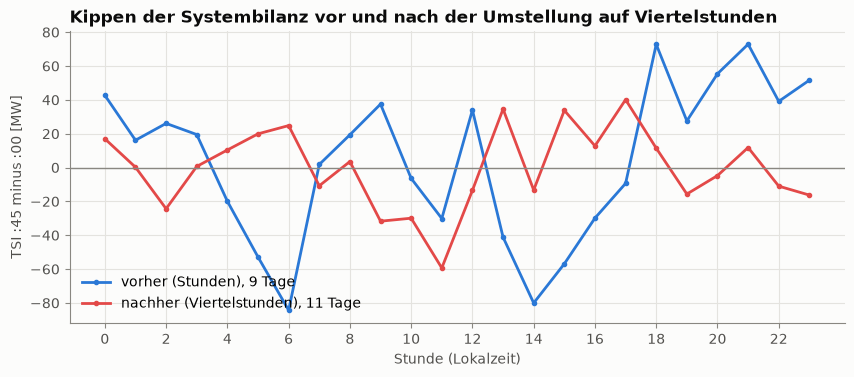

In [65]:
#-------------------------------------------------------
# Mittleres Kippen je Stunde vor und nach dem 04.11.2026
#-------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.8))
for colour, label in zip([BLUE, RED], ["vorher (Stunden)", "nachher (Viertelstunden)"]):
    group = periods[label]
    profile = group.groupby("hour")["trend"].mean()
    ax.plot(profile.index, profile, marker="o", markersize=3, color=colour, label=f"{label}, {group['date'].nunique()} Tage")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set(xlabel="Stunde (Lokalzeit)", ylabel="TSI :45 minus :00 [MW]", xticks=range(0, 24, 2),
       title="Kippen der Systembilanz vor und nach der Umstellung auf Viertelstunden")
ax.legend(loc="lower left")
save(fig, "sl_flip_before_after_switch.png")
plt.show()

#### **Erkenntnisse**

Seit der Umstellung auf Viertelstunden ist kein systematisches Kippen mehr nachweisbar, und das typische Tagesprofil ist verschwunden. Das passt zum Mechanismus, ist mit 11 Tagen aber erst ein vorläufiger Befund.

**Kein systematisches Kippen mehr nachweisbar**
- **Vorher** (**26.10.** bis **03.11.2026**, 9 Tage): 38.6 MW, über der Rauschgrenze (95 %: 32.2 MW)
- **Nachher** (**04.11.** bis **14.11.2026**, 11 Tage): 18.8 MW, unter der Rauschgrenze (95 %: 23.0 MW, Median 17.0 MW). Der Wert ist so gross, wie ihn der Zufall allein erreicht
- **September und Oktober** mit Stundenhandel: 53.7 und 56.0 MW, weit über der Rauschgrenze (23.4 und 26.7 MW). Mit 30 und 24 Tagen liegt die Grenze tiefer, die Werte sind deshalb nicht direkt mit 9 und 11 Tagen vergleichbar
- Die Kippen der einzelnen Stunden bleiben fast gleich gross: mittleres |Kippen| von 61.9 auf 56.4 MW, starke Stunden über 100 MW von 22 % auf 15 %. Es verschwindet nur das Muster, das sich jeden Tag zur gleichen Uhrzeit wiederholt

**Tagesprofil verschwunden**
- Das Profil nachher hängt mit dem Profil vorher nicht mehr zusammen (Korrelation −0.25, gleiches Vorzeichen nur in 38 % der Stunden)
- Morgenrampe und Abendrampe sind nicht mehr zu erkennen

**Grenzen**
- **Kurze Zeiträume:** 9 und 11 Tage, und der Spätherbst hat ohnehin schwächere Sonnenrampen
- **Provisorische Werte:** Die Regelzonenbilanz der letzten Tage kann sich noch ändern
- **Kein Preis:** Die finalen Preise für November erscheinen erst um Mitte Dezember. Ob sich auch der Preisunterschied zwischen :00 und :45 verkleinert, lässt sich noch nicht prüfen

Unsere Modelle lernen das Muster aus Januar bis Oktober. Ab dem **04.11.2026** könnte das Merkmal „Position in der Stunde“ deutlich weniger tragen. Das ist eine wichtige Grenze für alle Modelle und für die Testperiode.

### **1.5.5) Residuallast und Kippen**

Die Richtung des Kippens sollte der Steigung der Residuallast folgen, also Verbrauch minus Solarproduktion. Tagsüber lässt sich die Solarseite mit der Strahlungsprognose messen, für den Verbrauch fehlen die Daten.

**Daten:**
- `flips`: Kippen je Tag und Stunde aus `1.5.3) Stabilität des Kippens`
- `mean_weather`: PV-gewichtete Strahlungsprognose je Viertelstunde aus `1.3) Wetter, vergangene Preise und Stabilität (H9 bis H12)`
- **Lastprognose von ENTSO-E:** noch nicht verfügbar (#37). Der Teil zum Verbrauch bleibt deshalb offen

**Vorgehen:**
1. Steigung der Strahlungsprognose je Stunde wie in H8 berechnen, Strahlung der nächsten minus der vorherigen Stunde
    - die Prognose liegt nur stündlich vor, eine Änderung innerhalb der Stunde ist deshalb nicht messbar
2. Stunden mit sich ändernder Sonne von Stunden mit konstanter Sonne trennen, praktisch die Nacht
3. Je Gruppe das systematische und das mittlere Kippen vergleichen, für Stunden mit Sonne zusätzlich die Rangkorrelation mit der Steigung
    - ohne Sonne können nur Verbrauch und Fahrpläne das Kippen erklären

In [66]:
#----------------------------------------------------------------------
# Steigung der Strahlungsprognose je Stunde und Kippen der Systembilanz
#----------------------------------------------------------------------
radiation = mean_weather[["shortwave_radiation"]].join(cab.set_index("timestamp_utc")["timestamp_local"], how="inner")
hourly_radiation = radiation.groupby([radiation["timestamp_local"].dt.date.rename("date"),
                                      radiation["timestamp_local"].dt.hour.rename("hour")])["shortwave_radiation"].mean()
# change of the forecast radiation across the hour: next hour minus previous hour of the same day
radiation_slope = (hourly_radiation.groupby(level="date").shift(-1)
                   - hourly_radiation.groupby(level="date").shift(1)).rename("radiation_slope")
joined = flips.set_index(["date", "hour"])[["trend"]].join(radiation_slope, how="inner").dropna().reset_index()
joined["sun"] = np.where(joined["radiation_slope"] != 0, "Sonne ändert sich", "Sonne konstant")
residual = pd.DataFrame({
    sun: {"Stunden": len(group),
          "systematisches Kippen [MW]": group.groupby("hour")["trend"].mean().abs().mean(),
          "mittleres |Kippen| [MW]": group["trend"].abs().mean(),
          "Rangkorrelation mit der Steigung": spearman(group, "trend", "radiation_slope") if sun == "Sonne ändert sich" else np.nan}
    for sun, group in joined.groupby("sun")}).T
print(f"- Stunden mit konstanter Sonne: {sorted(joined.loc[joined['sun'] == 'Sonne konstant', 'hour'].value_counts().head(8).index)}")
residual.round(2)

- Stunden mit konstanter Sonne: [1, 2, 3, 4, 5, 20, 21, 22]


,Stunden,systematisches Kippen [MW],mittleres |Kippen| [MW],Rangkorrelation mit der Steigung
Sonne konstant,1443.0,76.51,68.08,NaN
Sonne ändert sich,3880.0,65.78,108.96,0.47


#### **Erkenntnisse**

Tagsüber erklärt die Sonne einen Teil des Kippens, nachts nicht. Dort kippt die Systembilanz trotzdem deutlich, also müssen Verbrauch und Fahrpläne den Rest erklären.

**Mit Sonne teilweise erklärt**
- In Stunden mit sich ändernder Sonne hängt das Kippen mit der Steigung der Strahlungsprognose zusammen, Rangkorrelation 0.47 wie in H8
- Das mittlere |Kippen| ist dort mit 109.0 MW am grössten

**Ohne Sonne deutliches Kippen**
- In Stunden mit konstanter Sonne, vor allem von 20 bis 5 Uhr, beträgt das mittlere |Kippen| 68.1 MW. Die Strahlung kann es dort nicht erklären
- Die Stunden 0 und 23 fehlen, weil die Steigung die Stunde davor und danach am selben Tag braucht
- Das systematische Kippen der beiden Gruppen (76.5 und 65.8 MW) ist nicht vergleichbar: Manche Stunden gehören nur an wenigen Tagen zur Gruppe ohne Sonne, etwa 6, 18 und 19 Uhr nur im Januar und Februar an 14 bis 56 Tagen, und ihre Mittel streuen stark

**Lücke Verbrauch**
- Die Lastprognose von ENTSO-E (#37) liegt noch nicht vor
- Ob die Steigung der Last das Kippen am Abend, in der Nacht und am Morgen erklärt, bleibt deshalb offen

Die Hypothese „Richtung folgt der Residuallast“ ist für den Solarteil gestützt, für den Verbrauchsteil noch nicht geprüft.

### **1.5.6) Empfehlung zum Merkmal**

Das Kippen hängt von Uhrzeit und Position in der Stunde ab. Uhrzeit und Position sind um 11:00 an D−1 bekannt, das Kippen selbst nicht. Ob ein Modell davon profitiert, zeigt der Vergleich der Referenz mit einer Variante ohne Position in der Stunde.

**Daten (April und Mai 2026):**
- `prices`: Preis je Viertelstunde
- nur der Zeitraum zur Auswahl der Settings, damit die Testperiode Juni bis August unberührt bleibt (`1.4.2) Bewertungsverfahren`)

**Definitionen:**
- **Referenz:** Quantile P10, P50 und P90 je Viertelstunde des Tages aus den letzten 56 Tagen bis D−2 (`reference_forecast` aus `src/energy_price/models/shared/reference.py`)
- **Referenz ohne Position:** dieselben Quantile, aber je Stunde, die vier Viertelstunden zusammengelegt

**Vorgehen:**
1. Beide Varianten für jeden Liefertag im April und Mai berechnen
2. Mittleren Pinball-Loss und Abdeckung je Position in der Stunde vergleichen

In [67]:
#-----------------------------------------------------------------------------------
# Referenz je Viertelstunde und je Stunde für April und Mai, nur mit Preisen bis D−2
#-----------------------------------------------------------------------------------
rows = []
for day in pd.date_range("2026-04-01", "2026-05-31").date:
    target = prices[prices["timestamp_local"].dt.date == day]
    by_slot = reference_forecast(prices, target, day)
    known = prices[prices["timestamp_local"].dt.date.between(day - dt.timedelta(days=57), day - dt.timedelta(days=2))]
    by_hour = known.groupby(known["timestamp_local"].dt.hour)["aep_ct_kwh"].quantile([0.1, 0.5, 0.9]).unstack()
    by_hour = by_hour.reindex(target["timestamp_local"].dt.hour.to_numpy()).set_axis(target.index)
    by_hour.columns = ["h10", "h50", "h90"]
    rows.append(pd.concat([target[["timestamp_local", "aep_ct_kwh"]], by_slot, by_hour], axis=1))
position_test = pd.concat(rows).dropna()


def mean_loss(frame: pd.DataFrame, columns: list[str]) -> float:
    return float(np.mean([pinball_loss(frame["aep_ct_kwh"], frame[c], tau) for c, tau in zip(columns, (0.1, 0.5, 0.9))]))


#-----------------------------------------------------
# Pinball-Loss und Abdeckung je Position in der Stunde
#-----------------------------------------------------
position_rows = []
for minute, group in [("alle", position_test), *position_test.groupby(position_test["timestamp_local"].dt.minute)]:
    position_rows.append({
        "Position": f":{minute:02d}" if minute != "alle" else "alle",
        "Pinball je Viertelstunde": mean_loss(group, ["q10", "q50", "q90"]),
        "Pinball je Stunde": mean_loss(group, ["h10", "h50", "h90"]),
        "Abdeckung je Viertelstunde": group["aep_ct_kwh"].between(group["q10"], group["q90"]).mean(),
        "Abdeckung je Stunde": group["aep_ct_kwh"].between(group["h10"], group["h90"]).mean()})
print(f"{position_test['timestamp_local'].dt.date.nunique()} Liefertage und {len(position_test):,} Viertelstunden".replace(",", "'"))
pd.DataFrame(position_rows).round(3)

61 Liefertage und 5'856 Viertelstunden


,Position,Pinball je Viertelstunde,Pinball je Stunde,Abdeckung je Viertelstunde,Abdeckung je Stunde
0,alle,3.449,3.552,0.776,0.793
1,:00,3.683,3.886,0.771,0.758
2,:15,3.574,3.581,0.762,0.778
3,:30,3.128,3.131,0.783,0.836
4,:45,3.408,3.612,0.787,0.798


#### **Erkenntnisse**

Schon die Referenz profitiert von der Position in der Stunde. Die bestehenden Modelle enthalten sie bereits, ein neues Merkmal braucht es vor allem für die Last.

**Position in der Stunde zahlt sich aus**
- Mit Quantilen je Viertelstunde sinkt der Pinball-Loss gegenüber Quantilen je Stunde von 3.552 auf 3.449, also um 2.9 %
- Der Gewinn kommt fast nur aus :00 (3.886 auf 3.683) und :45 (3.612 auf 3.408), bei :15 und :30 ist er praktisch null
- Die Referenz je Viertelstunde reproduziert den Tuning-Wert der Referenz aus `gbm_quantile` (3.4485)

**Empfehlung**
- **Behalten:** Position in der Stunde × Uhrzeit und die Steigung der Strahlung × Position. Beides steckt schon in B1 und B2 und damit in Baseline, Gradient Boosting und Regime-Modell
- **Ergänzen, sobald #37 liefert:** Steigung der Lastprognose über die Stunde, für Abend, Nacht und Morgen, wo die Sonne nichts erklärt
- **Ergänzen:** Werktag × Uhrzeit für die Morgenrampe, die es nur an Werktagen gibt
- **Überwachen:** Ab dem **04.11.2026** könnte die Position in der Stunde stark an Wert verlieren. Bevor ein Modell für die Zeit danach eingesetzt wird, muss es auf Daten nach der Umstellung geprüft und neu trainiert werden

Ergebnis als Empfehlung, keine Umsetzung im Rahmen von #39.

---
## **1.6) Fazit**

**Erste Runde (H1 bis H8):**

| # | Antwort in einem Satz |
|---|---|
| H1 | Teilweise <br> • mittags (10 bis 14 Uhr) in 7 von 8 Monaten häufiger short (59 % gegenüber 54 %) <br> • deutlich nach Position in der Stunde (:00 zu 58 % short, :45 zu 50 %) <br> • Wochentag und Monat schwach <br> • Mittagsloch des Preises ab April |
| H2 | Die Richtung von D−2 stimmt nur in 54 % mit dem Liefertag überein, Zufall wäre 50.4 %. |
| H3 | Die Strahlungsprognose hängt nicht mit der TSI zusammen (−0.08), aber mit dem Preisniveau (−0.58 bei long). |
| H4 | • Tiefe Extreme nur mittags bei long, oft am Wochenende <br> • Hohe Extreme bei short, an Werktagen, morgens und abends |
| H5 | 2025 und 2026 sind klar verschieden (Jul-Aug 36 % gegenüber 11 % negativ), nur 2026 verwenden. |
| H6 | Feiertage mit tieferem Preis und mehr negativen Preisen, aber nur 5 Tage Belege. |
| H7 | Streuung am Nachmittag am grössten, das Profil hängt stark von der Saison ab. |
| H8 | • Die TSI kippt innerhalb jeder Stunde, die Richtung folgt der Residuallast (z.B. 17 Uhr :00 zu 30 %, :45 zu 79 % short) <br> • Die Steigung der Strahlungsprognose erklärt einen Teil (0.47) |

**Zweite Runde (H9 bis H12):**

| # | Ergebnis | Antwort in einem Satz |
|---|---|---|
| H9 | teilweise | Bewölkung und Standort-Streuung machen die Systembilanz unruhiger (mittags 62 gegenüber 106 MW), das Preisband aber nicht breiter. |
| H10 | widerlegt | Über Strahlung und Uhrzeit hinaus tragen die übrigen Wettervariablen nichts bei (alle Mediane zwischen −0.04 und +0.09). |
| H11 | schwach | • Vergangene Preise sagen wenig (0.16 nach 2 Tagen) <br> • Quantile der Vergangenheit decken höchstens 75 % statt 80 % ab |
| H12 | Bruch im Frühling | Von Februar bis April ändert sich die Preisverteilung stark, ab April ist sie stabil. |

**Bewertungsdesign und Metriken (`1.4) Bewertungsdesign und Metriken`):**
- **Ausgabe:** P10, P50 und P90 je Viertelstunde, weil der Preis aus zwei Wolken je Richtung besteht
- **Band:** 80 %, weil äussere Quantile mit 56 Tagen bis auf 14 ct/kWh ungenau sind
- **Hauptmetrik:** mittlerer Pinball-Loss, ergänzt durch MAE des Medians, Abdeckung und Breite
- **Referenz:** Quantile je Viertelstunde aus den letzten 56 Tagen bis D−2

**Stundenslot-Handel (`1.5) Stundenslot-Handel und Kippen der Systembilanz`):**
- **Mechanismus:** Day-Ahead in Stunden, Abrechnung in Viertelstunden, belegt durch Marktregeln und Literatur
- **Stabilität:** gleiches Muster an allen Tagtypen und Monaten, die Richtung folgt der Sonne, die Morgenrampe gibt es nur an Werktagen
- **Umstellung am 04.11.2026:** kein systematisches Kippen mehr nachweisbar (18.8 MW, Rauschgrenze 23.0 MW, vorher 38.6 MW), Tagesprofil verschwunden, vorläufig mit 11 Tagen
- **Merkmal:** Position in der Stunde senkt den Pinball-Loss der Referenz um 2.9 %, könnte nach der Umstellung aber an Wert verlieren

**Empfehlungen für die Baseline und die Merkmale:**
- **Wettervariablen:**
    - Strahlung (Niveau und Steigung) und Bewölkung bzw. Standort-Streuung
    - die übrigen vorerst weglassen
- **Trainingsfenster:**
    - Baseline mit gleitenden 8 Wochen
    - Modelle mit allen Daten seit Januar plus Saisonsignal
    - beide im Backtest vergleichen
- **Unsicherheitsband:**
    - Quantile aus der Vergangenheit allein sind zu schmal
    - Kalibrierung einplanen und die Abdeckung je Monat prüfen

**Grenzen:**
- **Zeitraum:** Preise nur von Januar bis August, Herbst und Winter-Ende fehlen
- **Finale Werte:**
    - Die Preise sind final, nicht provisorisch
    - Die Regelzonenbilanz der letzten Wochen vor einem Abruf ist provisorisch. Das betrifft vor allem die Tage nach der Umstellung in `1.5.4) Vor und nach der Umstellung auf Viertelstunden`
    - Die Grenze D−2 ist bis ca. **18.10.2026** eine Annahme
- **Deutungen:** Die Deutungen in H3 und H5 sind Vermutungen

Merkmalskandidaten, Fragen an den Owner und nächste Schritte stehen in [`docs/eda.md`](../docs/eda.md).